# Forecasting the Next 48 Hours of Washington D.C. Bike-Share Rentals

## The Research Question

In this project, I forecast hourly recorded rentals across the **Capital Bikeshare** system. My aim is to answer two related questions: how accurately can I predict the next 48 hours from a single forecast origin, and how much evidence supports one forecasting procedure’s apparent advantage over another?

At midnight, each procedure issues a complete path of **48 hourly predictions**, before any actual rental counts from that future window become available. Forecast origins are spaced two calendar days apart.

Finding the lowest average error is a useful starting point. However, a small average advantage can be driven by a few unusually favorable forecast paths. I therefore evaluate procedures at the **same origins and target hours**, then examine their paired loss differences across those occasions.

This lets me assess the size, variability, and consistency of the observed advantages. Temporal dependence and the use of development data to inform modeling choices remain important limits on the evidence.

## The Prediction Target

The target is **system-wide recorded rentals**, reconstructed under one consistent policy:

- Retain the rental counts supplied in the original data.
- Assign inferred zeros to absent non-DST timestamps under the daily-total completeness assumption explained in Section 1.
- Retain the 83 hours within four labelled development-period disruptions.

Training, development selection, and final scoring use this same target definition. The inferred zeros are a reconstruction supported by the supplied aggregates under an explicit assumption; they are not independently verified observations of zero activity.

A secondary, development-only sensitivity re-scores **the same predictions** after excluding disruption hours from the evaluation. Of the 83 labelled hours, 36 fall within scored development paths. This comparison measures how their inclusion affects the reported errors; it does not measure their influence on training. No model is refitted or reselected for this sensitivity.

**Recorded rentals are not unconstrained demand.** An unavailable bicycle or full return station can prevent a potential rental from being recorded. References to *demand* therefore mean this recorded-rental target. Station-level forecasting and rebalancing are outside the study.

## Forecasting Design

I separate hyperparameter tuning, model-family selection, and final evaluation so readers can identify which observations informed each decision.

Paired statistical comparisons concern the development paths. The final block reports accuracy and coverage descriptively, without new significance tests or uncertainty intervals for model differences.

| Design element | Specification |
|:---|:---|
| Forecast path | 48 hourly grid positions, issued at midnight every two calendar days |
| Primary selection metric | MAE |
| Supporting metrics | Pooled RMSE, MASE, and errors by horizon step |
| Hyperparameter tuning | 22 early rolling origins, followed by frozen settings |
| Model-family selection | 92 later rolling origins within development |
| Final evaluation block | November 1–December 31, 2012 |
| Headline scoring population | 30 complete paths covering November 1–December 30: 1,440 hourly targets |
| Carried pipeline | Chosen from development evidence and named before final performance evaluation |

The trailing December 31 positions remain unscored. Later final-evaluation origins may use earlier actuals once observed, while the selected configuration remains fixed.

**Historical holdback disclosure.** Before the original final performance evaluation, an early data-quality check exposed four inferred zero outcomes and the block’s absence structure. Section 0 documents this limited prior exposure. The final block is therefore not described as a pristine holdout.

**Clock convention.** Forecast steps follow the dataset’s timezone-naive civil-time grid. Around daylight-saving transitions, 48 grid positions need not represent 48 elapsed hours. Section 1 explains the treatment and limitations of these timestamps.

## Data and Attribution

The project uses Fanaee-T’s (2013) UCI **Bike Sharing Dataset**, [DOI 10.24432/C5W894](https://doi.org/10.24432/C5W894), licensed under [Creative Commons Attribution 4.0 International (CC BY 4.0)](https://creativecommons.org/licenses/by/4.0/).

**Commercial use is permitted.** The dataset may be used, modified, and redistributed for commercial and non-commercial purposes, subject to the license terms, including appropriate attribution, a link to the license, and an indication of any changes.

The reconstructed target and engineered features are project transformations of the original inputs. The dataset license does not automatically apply to the project’s code or unrelated third-party material.

## Section 0: Setup

### Historical Holdback Disclosure

Before the original model-performance evaluation, an early data-quality check identified **four isolated absent hourly timestamps** in the November–December 2012 final evaluation block. There was no multi-hour run of absent timestamps.

Under the reconstruction assumption explained in Section 1, those four missing positions were assigned inferred zero rental counts. This exposed **four reconstructed target values among 1,464 hourly grid positions**. Their dates are listed in the protocol before Section 10.

At that stage, I had not inspected forecasts, forecast errors, aggregate rental statistics for the block, or its nonzero target values.

I therefore describe the period as a **historical holdback with limited prior outcome exposure**, rather than a pristine holdout. The preliminary check revealed some target information; it did not involve evaluating forecasting performance on the final period.

### Data Loading and Analytical Separation

The loader reads the complete CSV files into temporary pandas DataFrames and **immediately filters them to the development period**. Final-block rows are not retained in the development frames or used in the subsequent development calculations.

Within this pipeline, data-derived preprocessing, model fitting, hyperparameter tuning, and model-family selection use development observations only. Section 10 later introduces the final-period observations under the fixed evaluation protocol.

This is a distinction between **physical access and analytical use**. Reading file contents into memory does not itself make those observations part of model development. Information leakage arises when information from the held-back observations enters calculations or decisions that shape the procedure.

The two issues are therefore documented separately:

- **Prior information exposure:** the preliminary check revealed four inferred zero outcomes and the missing-timestamp pattern.
- **Analytical separation:** the development pipeline excluded final-period rows from its calculations.

The filtering safeguard does not erase the earlier exposure. Together, these disclosures state what was known and how the subsequent analysis restricted its use of the final period.

In [1]:
import warnings
import itertools, time

# No blanket warning suppression. Only two specific, named filters, because
# convergence warnings from SARIMA later are a diagnostic this notebook needs to see.
warnings.filterwarnings("ignore", message=".*Yearly seasonality.*")   # Prophet, addressed in 6.3
warnings.filterwarnings("ignore", category=FutureWarning)             # library deprecations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)
plt.rcParams.update({"figure.figsize": (14, 5), "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})

HORIZON = 48                                # forecast horizon, hours
SEASON  = 24                                # dominant seasonal period
WEEK    = 168                               # hours in a week
EVAL_START = pd.Timestamp("2012-11-01")     # held-back block begins here

print("Setup complete.")

Matplotlib is building the font cache; this may take a moment.


Setup complete.


### Reproducibility

Run the notebook sequentially from a fresh kernel, with `Data/hour.csv` and `Data/day.csv` beside it.

The analysis uses Python 3.10. The following cell records environment details and input hashes. Where imported runtime versions differ from package metadata, use the imported versions as the reference.

The last full verification executed all 72 analytical code cells without errors and reproduced the headline results at their reported precision. Verification used the existing environment; a clean installation has not been tested.

In [2]:
def _record_current_environment():
    import hashlib
    import platform
    import sys
    from datetime import datetime, timezone
    from importlib import metadata
    from pathlib import Path

    print("CURRENT EXECUTION / INPUT SNAPSHOT")
    print("Recorded at (UTC):", datetime.now(timezone.utc).isoformat(timespec="seconds"))
    print("Python:", platform.python_version(), "|", platform.system(), platform.machine())
    print("Interpreter:", sys.executable)
    packages = {
        "numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
        "scipy": "scipy", "scikit-learn": "sklearn", "xgboost": "xgboost",
        "lightgbm": "lightgbm", "prophet": "prophet", "statsmodels": "statsmodels",
        "cmdstanpy": "cmdstanpy", "ipykernel": "ipykernel",
    }
    for package, module_name in packages.items():
        try:
            installed = metadata.version(package)
        except metadata.PackageNotFoundError:
            installed = "NOT INSTALLED"
        module = sys.modules.get(module_name)
        runtime = getattr(module, "__version__", None)
        label = str(runtime) if runtime is not None else "not yet imported"
        mismatch = " [VERSION LABEL MISMATCH]" if runtime is not None and str(runtime) != installed else ""
        print(f"  {package}: runtime={label}; distribution={installed}{mismatch}")
    print("Input files (SHA-256):")
    for filename in ("Data/hour.csv", "Data/day.csv"):
        file_path = Path(filename)
        if not file_path.is_file():
            raise FileNotFoundError(f"Run from the project folder: missing {filename}")
        print(f"  {filename}: {hashlib.sha256(file_path.read_bytes()).hexdigest()}")

_record_current_environment()
del _record_current_environment

CURRENT EXECUTION / INPUT SNAPSHOT
Recorded at (UTC): 2026-11-10T18:27:06+00:00
Python: 3.10.18 | Darwin arm64
Interpreter: /opt/miniconda3/envs/handson-env/bin/python
  numpy: runtime=1.26.4; distribution=2.2.6 [VERSION LABEL MISMATCH]
  pandas: runtime=2.3.3; distribution=2.3.3
  matplotlib: runtime=3.10.6; distribution=3.10.5 [VERSION LABEL MISMATCH]
  scipy: runtime=not yet imported; distribution=1.15.2
  scikit-learn: runtime=not yet imported; distribution=1.7.2
  xgboost: runtime=not yet imported; distribution=3.0.5
  lightgbm: runtime=not yet imported; distribution=4.6.0
  prophet: runtime=not yet imported; distribution=1.4.0
  statsmodels: runtime=not yet imported; distribution=0.14.5
  cmdstanpy: runtime=not yet imported; distribution=1.3.0
  ipykernel: runtime=6.30.1; distribution=6.30.1
Input files (SHA-256):
  Data/hour.csv: e03de4ee4ef4dc376ac6e04bf829673c6269e8eba5c60fa121640fa2f829504f
  Data/day.csv: a6bcf826782d3c0fbfdcbeead17cd0884185a0dafe8ff10cd48a874ee7ba18be


## Section 1: Reconstructing the Absent Hourly Rows

Some expected timestamps have no corresponding row in the hourly table. Before constructing a regular forecasting grid, I need to decide what those absences mean.

A missing row could represent zero recorded rentals, or it could reflect an incomplete record. The timestamp’s absence alone cannot distinguish between them. The supplied daily totals provide an aggregation constraint that helps investigate the question.

### Why daily reconciliation can support inferred zeros

For a given ordinary day, let:

- $D$ be the supplied daily rental total.
- $S_{\mathrm{observed}}$ be the sum of the hourly counts present for that date.
- $H_{\mathrm{absent}}$ be the set of absent genuine hourly positions.

If the retained hourly counts are valid components of the same complete daily total, then

$$
\sum_{h \in H_{\mathrm{absent}}} y_h
=
D-S_{\mathrm{observed}}.
$$

When the available hourly counts already sum to the daily total, the right-hand side is zero. Because rental counts are nonnegative, each absent hour must then contribute zero **under those assumptions**.

This gives me a reason to reconstruct inferred zeros instead of interpolating positive counts.

For example, neighboring observations of 100 and 140 rentals would produce a linear interpolation of 120. If the existing hourly records already account for the complete daily total, adding those 120 rentals would make the reconstructed total exceed it.

The reconstruction therefore follows the aggregation constraint. It does not assume that an absent hour should resemble its neighbors.

### What this inference does and does not establish

The daily and hourly tables are two aggregations of rental records, not independent confirmation that every transaction was captured. An omission shared by both could preserve their agreement.

The inference depends on consistent aggregation, valid retained hourly counts, and the assumption that the supplied daily totals account for all recorded rentals.

I therefore call the reconstructed values **inferred zeros**. They differ from an explicit zero reported in an existing hourly row, and they do not establish that no unmet demand existed.

### Clock changes require separate treatment

I distinguish ordinary absent records from daylight-saving-time effects:

- **Spring transition:** the two nonexistent hourly positions are excluded from scoring rather than assigned zero-rental targets.
- **Autumn transition:** the supplied timezone-naive date/hour fields cannot separate repeated clock hours into distinct physical observations.

The analysis retains the dataset’s civil-time grid. It does not reconstruct a complete timezone-aware timeline.

The following cells check whether the hourly sums reconcile with the daily totals in the development period, then examine the absent-timestamp patterns before applying the target policy.

In [3]:
DATA_DIR = "Data/"

# Read both files, then retain ONLY the development period. Physical isolation would
# need separate files; what is guaranteed here is that no row at or after EVAL_START
# survives into `hourly`/`daily` or anything computed from them.
_h = pd.read_csv(DATA_DIR + "hour.csv")
_d = pd.read_csv(DATA_DIR + "day.csv")
_h["ds"] = pd.to_datetime(_h["dteday"]) + pd.to_timedelta(_h["hr"], unit="h")
_d["dteday"] = pd.to_datetime(_d["dteday"])

hourly = _h[_h["ds"] < EVAL_START].set_index("ds").sort_index()
daily  = _d[_d["dteday"] < EVAL_START].set_index("dteday")
del _h, _d

print(f"Development period: {hourly.index.min()} -> {hourly.index.max()}")
print(f"Rows present: {len(hourly)}")
print(f"No rows at or after {EVAL_START.date()} are retained or analyzed below.")

Development period: 2011-01-01 00:00:00 -> 2012-10-31 23:00:00
Rows present: 15919
No rows at or after 2012-11-01 are retained or analyzed below.


In [4]:
# The decisive check: do the present hourly rows already account for the official daily totals?
recon = (hourly.groupby(hourly.index.normalize())["cnt"].agg(["sum", "size"])
                .join(daily["cnt"].rename("day_total")))

print(f"Days in development period:            {len(recon)}")
print(f"Days with fewer than 24 hourly rows:   {(recon['size'] < 24).sum()}")
print(f"Days where hourly sum == day.csv total: {(recon['sum'] == recon['day_total']).sum()} of {len(recon)}")
print(f"Incomplete days that still reconcile:   "
      f"{(recon.loc[recon['size'] < 24, 'sum'] == recon.loc[recon['size'] < 24, 'day_total']).sum()}"
      f" of {(recon['size'] < 24).sum()}")
print()
print(f"Smallest count anywhere in hour.csv:    {hourly['cnt'].min()}")
print(f"Any zero counts recorded at all:        {(hourly['cnt'] == 0).any()}")

assert (recon["sum"] == recon["day_total"]).all()

Days in development period:            670
Days with fewer than 24 hourly rows:   72
Days where hourly sum == day.csv total: 670 of 670
Incomplete days that still reconcile:   72 of 72

Smallest count anywhere in hour.csv:    1
Any zero counts recorded at all:        False


### What the Reconciliation Supports

The preceding check shows exact agreement on **all 670 development days**: the available hourly counts sum to the corresponding `day.csv` total. This includes **all 72 days with fewer than 24 hourly rows**.

The development subset of `hour.csv` also contains no explicitly recorded zeros; its minimum count is **1**. Together, these observations are consistent with zero-count hours being omitted from the hourly table, although they do not independently establish that data-generation rule.

#### From reconciliation to inferred zeros

I retain the supplied hourly counts as valid components of the daily totals. If both aggregations are consistent and the daily totals account for all recorded rentals, exact reconciliation leaves no additional rentals to allocate to absent genuine hourly positions.

Because counts are nonnegative, each of those positions must contribute zero under these assumptions.

Interpolating a positive count would increase the reconstructed hourly sum beyond the supplied daily total. I therefore assign **inferred zeros** to absent non-DST positions instead of interpolating rentals.

This remains a conditional inference. Transactions omitted from both underlying aggregates could leave their totals in agreement. The check establishes consistency between the supplied tables, not independent verification that no rental activity occurred.

#### One target policy throughout the analysis

Absent genuine hourly positions receive inferred zero targets, including positions within labelled disruption periods. These values remain eligible for primary scoring whenever they fall within an evaluation path.

The disruption label serves a separate purpose: it affects feature construction and defines the development-only secondary re-scoring subset. It does not change the primary target-reconstruction policy.

Throughout the analysis, these values remain **inferred zeros**, including where saved outputs use shorthand such as “zero hours.”

#### Clock convention

The supplied date/hour fields do not contain UTC offsets or a marker distinguishing repeated autumn hours. I retain their timezone-naive civil-time grid:

- The two nonexistent spring-forward `02:00` positions are excluded from scoring.
- Repeated autumn hours cannot be separated into distinct physical observations from the supplied fields.
- A 48-step path means 48 positions on this grid, which need not equal 48 elapsed hours across a clock change.

Next, I examine the absent-timestamp runs and the evidence used to distinguish ordinary quiet periods from exceptional disruptions.

In [5]:
full_index = pd.date_range(hourly.index.min(), EVAL_START - pd.Timedelta(hours=1), freq="h")
absent = full_index.difference(hourly.index)

runs = []
for _, g in itertools.groupby(enumerate(absent), lambda t: t[1] - pd.Timedelta(hours=t[0])):
    g = [x[1] for x in g]
    runs.append({"start": g[0], "end": g[-1], "hours": len(g)})
runs = pd.DataFrame(runs)

print(f"Absent timestamps: {len(absent)} in {len(runs)} consecutive runs")
print(runs["hours"].value_counts().sort_index().rename("runs").to_frame().T.to_string())

Absent timestamps: 161 in 71 consecutive runs
hours  1   2   6   12  13  22  36
runs   60   6   1   1   1   1   1


### Distinguishing Ordinary Quiet Hours from Exceptional Disruption

Most absent runs last one or two hours, while a few are much longer. Duration alone does not tell me how unusual a run is: six absent overnight hours can have a different interpretation from six hours covering the morning commute.

I therefore compare each non-DST run with reference hourly and daily rental patterns.

#### A two-part classification rule

**1. Does the run overlap a normally busy hour?**

I calculate a median rental count for each of the 168 weekday-hour combinations, using the existing development-period hourly rows.

For an absent run, I take the **largest** of its corresponding reference medians. The first criterion is satisfied when that maximum exceeds **50 rentals**.

Using the maximum asks whether the run includes at least one typically busy hour. An average across the run could dilute that signal with quiet overnight hours.

**2. Is an affected day unusually quiet relative to its reference?**

For each calendar date touched by the run, I divide its supplied daily rental total by the development-period median for the **same weekday and calendar month**, pooling the available years.

For a run spanning several dates, I take the **smallest** daily ratio. The second criterion is satisfied when that minimum is below **0.60**.

Let $M_r$ be the maximum reference hourly median and $Q_r$ the minimum daily ratio. The implemented rule is

$$
\operatorname{Disruption}(r)
=
(M_r > 50)
\land
(Q_r < 0.60).
$$

Both conditions must hold. A quiet overnight run can therefore fail the first condition even when its day has a low rental total. For a run spanning multiple dates, the qualifying hourly and daily evidence need not come from the same date.

This is a descriptive classification heuristic. It does not establish a verified system closure or identify the cause of reduced activity.

#### Weather provides context

The evidence table also displays the supplied daily weather category. Weather does not enter the classification rule and does not independently verify an operational disruption.

#### What the label changes

The label does **not** change the primary target: absent genuine hourly positions retain their inferred zero rental counts whether labelled ordinary or disruptive.

It affects two other operations:

- **Lag-source construction:** disruption values in `y_lagsrc` are replaced using available observations from corresponding hours one to four weeks earlier. The scoring target `y` remains unchanged. Section 7.2 compares this treatment with retaining the disruption zeros using a frozen Ridge pipeline; that sensitivity does not establish its effect for other model families.
- **Secondary development re-scoring:** the same stored forecasts are evaluated without labelled disruption hours. No models are refitted or reselected from those secondary scores.

#### Why the label must not determine primary scoring

The daily-activity criterion uses a **realized rental total**, which is an aggregate target outcome. These labels are retrospective descriptions, not disruption warnings available when a forecast is issued.

Using them to exclude difficult evaluation hours would make the reported score depend on observed outcomes. The primary evaluation instead retains every eligible position within its predeclared forecast paths, including disruption zeros.

When the final block is opened, the implementation applies the frozen thresholds and development-derived reference profiles to classify its absent runs. Those labels do not determine which final prediction errors count.

The following code calculates the evidence for each run and applies the two-part rule.

In [6]:
MAX_TYPICAL_HOUR = 50    # run must suppress at least one hour whose median demand exceeds this
DAY_RATIO_MAX    = 0.60  # and the day must fall below this fraction of a typical comparable day

how_median = hourly.groupby(hourly.index.dayofweek * 24 + hourly.index.hour)["cnt"].median()

def _run_evidence(r):
    idx = pd.date_range(r["start"], r["end"], freq="h")
    typical = how_median.reindex(idx.dayofweek * 24 + idx.hour).to_numpy()
    days = pd.date_range(r["start"].normalize(), r["end"].normalize(), freq="D")
    observed = daily.loc[days, "cnt"].to_numpy()
    reference = np.array([daily[(daily.index.dayofweek == d.dayofweek) &
                                (daily.index.month == d.month)]["cnt"].median() for d in days])
    return pd.Series({"max_typical_hour": typical.max(),
                      "day_ratio": float(np.min(observed / reference)),
                      "day_weathersit": int(daily.loc[days, "weathersit"].max())})

runs = runs.join(runs.apply(_run_evidence, axis=1))

def _is_dst_gap(ts):
    """02:00 on the second Sunday of March: an hour that does not exist in US local time."""
    return ts.month == 3 and ts.hour == 2 and ts.weekday() == 6 and 8 <= ts.day <= 14

runs["kind"] = np.where(
    runs.apply(lambda r: r["hours"] == 1 and _is_dst_gap(r["start"]), axis=1), "dst_nonexistent",
    np.where((runs["max_typical_hour"] > MAX_TYPICAL_HOUR) & (runs["day_ratio"] < DAY_RATIO_MAX),
             "disruption", "zero_hour"))

print("Evidence for every run of 4 hours or more:")
print(runs[runs["hours"] >= 4][["start", "end", "hours", "max_typical_hour",
                                "day_ratio", "day_weathersit", "kind"]].to_string(index=False))
print()
print(runs.groupby("kind").agg(runs=("hours", "size"), hours=("hours", "sum")).to_string())

Evidence for every run of 4 hours or more:
              start                 end  hours  max_typical_hour  day_ratio  day_weathersit       kind
2011-01-18 00:00:00 2011-01-18 11:00:00     12             457.5   0.305456             2.0 disruption
2011-01-26 18:00:00 2011-01-27 15:00:00     22             497.0   0.165801             3.0 disruption
2011-02-22 00:00:00 2011-02-22 05:00:00      6              27.0   0.518598             1.0  zero_hour
2011-08-27 18:00:00 2011-08-28 06:00:00     13             300.0   0.198328             2.0 disruption
2012-10-29 01:00:00 2012-10-30 12:00:00     36             514.0   0.004542             3.0 disruption

                 runs  hours
kind                        
disruption          4     83
dst_nonexistent     2      2
zero_hour          65     76


### Interpreting the Two-Criterion Classification

The six-hour run on **February 22, 2011**, covering 00:00–05:00, illustrates how the hourly reference changes the classification.

The day is unusually quiet relative to its weekday-and-month reference, but none of the absent hours exceeds the chosen hourly-reference threshold:

| Criterion | Saved value | Required condition | Satisfied? |
|:---|---:|---:|:---:|
| Maximum hour-of-week median | 27 rentals | Greater than 50 | No |
| Minimum daily activity ratio | 0.519 | Less than 0.60 | Yes |

Because both conditions are required, the run receives the **ordinary quiet hours** label.

The maximum reference median of 27 is below the chosen cutoff; this does not mean those rentals would be economically meaningless. It means the run fails this particular classification criterion.

A hypothetical duration rule that flagged every run longer than five hours would label the same period differently. This example explains the behavior of the two-criterion rule, but does not independently establish which classification is correct or what caused the absence.

#### The four disruption-labelled runs

The other four long runs satisfy both conditions by substantial margins. Their maximum reference hourly medians range from **300 to 514 rentals**, while their **minimum daily ratios** range from approximately **0.45% to 30.5%** of the corresponding reference medians.

For runs spanning multiple dates, these percentages describe the lowest daily ratio, not necessarily every affected day.

The August 2011 and October 2012 runs coincide with [Irene](https://www.weather.gov/lwx/events_20110827_irene) and [Sandy](https://www.weather.gov/lwx/events_20121030_sandy). These event records provide context, but do not establish that Capital Bikeshare formally closed.

The two January runs remain data-defined winter disruption episodes. Their rental patterns satisfy the rule; their meteorological or operational causes are not established here. I therefore use **disruption-labelled periods**, without treating the labels as verified closures.

#### Retaining targets and respecting the scoring boundaries

All these absent non-DST positions retain their inferred zero targets under the reconstruction policy.

Retaining a target does not mean it falls within a scored forecast path. The February 2011 run sits in training history; the 92-origin development backtest begins on April 30, 2012. Of the 83 disruption-labelled hours, only the **36 Sandy hours** enter those scored paths. The other 47 occur earlier in training history.

The labels also identify lag-source replacements and the secondary development re-scoring subset. Section 7.2 tests the lag-source substitution using Ridge. Neither use changes the primary target definition.

#### The DST positions have a separate role

The two nonexistent spring-forward `02:00` positions are excluded from target scoring. They are not interpreted as zero-rental observations.

Separate computational fills used for regular-grid diagnostics or lag-feature construction do not make those positions observed rental hours or eligible scoring targets.

The next cell constructs the primary target and the separate lag-source series while preserving these distinctions.

In [7]:
WEATHER = ["temp", "atemp", "hum", "windspeed", "weathersit"]

df = (hourly[["cnt"] + WEATHER + ["holiday", "workingday"]]
      .rename(columns={"cnt": "y"}).reindex(full_index))
df.index.name = "ds"

def _hours_of(kind):
    return pd.DatetimeIndex([t for _, r in runs[runs["kind"] == kind].iterrows()
                             for t in pd.date_range(r["start"], r["end"], freq="h")])

df["is_disruption"]  = df.index.isin(_hours_of("disruption"))
df["is_nonexistent"] = df.index.isin(_hours_of("dst_nonexistent"))
df["was_absent_zero"] = df.index.isin(_hours_of("zero_hour"))

# PRIMARY TARGET `y`: every genuine clock hour. Absent non-DST hours receive
# inferred zeros under the daily-total completeness assumption (Section 1), including
# disruption hours. Sandy has a supplied daily total of 22 in its single present hour.
df.loc[df["was_absent_zero"], "y"] = 0.0
df.loc[df["is_disruption"], "y"] = 0.0
# Only the two nonexistent DST hours remain NaN: there is no such clock hour to score.

# SECONDARY, development-only: the same target with the four disruption periods removed,
# used to re-score identical forecasts on normal-operation hours. Never used for selection.
df["y_normal_ops"] = df["y"].where(~df["is_disruption"])

df[["temp", "atemp", "hum", "windspeed"]] = df[["temp", "atemp", "hum", "windspeed"]].interpolate()
df["weathersit"] = df["weathersit"].ffill().bfill()

# `holiday` and `workingday` are CALENDAR facts, not measurements, so they are
# reconstructed from the daily table rather than filled along the hourly index.
# Forward-filling them is wrong across a midnight gap: 2011-01-17 was a holiday and
# 2011-01-18's first recorded row is 12:00, so a forward fill labels that Tuesday
# morning a holiday. That corrupted 18 hours and injected two spurious dates into
# the holiday list.
_day_of = df.index.normalize()
for c in ["holiday", "workingday"]:
    df[c] = daily[c].reindex(_day_of).to_numpy()
assert df[["holiday", "workingday"]].notna().all().all(), "calendar fields must be complete"

# and they must agree with every hourly row that was actually recorded
_present = hourly.index
for c in ["holiday", "workingday"]:
    assert (df.loc[_present, c].to_numpy() == hourly[c].to_numpy()).all(),         f"reconstructed {c} disagrees with a recorded hourly value"
print(f"Calendar fields rebuilt from the daily table and checked against all "
      f"{len(_present)} recorded hourly rows.")

# A complete series for FEATURE CONSTRUCTION ONLY -- never scored.
# The disruption zeros are inferred values retained in the scoring target.
# Replacing them here is a feature-policy choice, motivated by the possibility
# that a temporary disruption could affect the following week's lag predictors.
# Section 7.2 compares raw and engineered lag sources for the frozen Ridge pipeline.
# That sensitivity changes no target values and does not establish the effect
# for other model families or their ranking.
y_lagsrc = df["y"].copy()
donor_ts = pd.Series(pd.NaT, index=df.index)          # which timestamp each replacement came from
unresolved = df["is_disruption"] | df["is_nonexistent"]

for step in [WEEK, 2 * WEEK, 3 * WEEK, 4 * WEEK]:     # PAST donors only, never t + k
    if not unresolved.any():
        break
    source_ts = df.index - pd.Timedelta(hours=step)
    donor = pd.Series(df["y"].reindex(source_ts).to_numpy(), index=df.index)
    take = unresolved & donor.notna()
    y_lagsrc[take] = donor[take]
    donor_ts[take] = source_ts[take]
    unresolved &= ~take

assert not unresolved.any(), "past-only donors could not complete the lag source"
_replaced = donor_ts.notna()
assert (donor_ts[_replaced].to_numpy() < df.index[_replaced].to_numpy()).all(),     "a lag-source donor came from the future"
df["y_lagsrc"] = y_lagsrc

print(f"Lag-source replacements: {int(_replaced.sum())} hours, all sourced from the past.")
print(f"  donor lag used (hours before target): "
      f"{sorted({int((t - d) / pd.Timedelta(hours=1)) for d, t in zip(donor_ts[_replaced], df.index[_replaced])})}")

scored = ~df["is_nonexistent"]          # primary scoring set: every genuine clock hour

# The policy, enforced rather than promised:
assert df["y"].isna().equals(df["is_nonexistent"])                      # only DST is unscoreable
assert df["y_normal_ops"].isna().equals(df["is_disruption"] | df["is_nonexistent"])
assert df["y_lagsrc"].notna().all()
assert (df.loc[scored, "y"] >= 0).all()
assert df.index.max() < EVAL_START

print(f"Calendar hours in development period:   {len(df)}")
print(f"  PRIMARY target `y`, scored hours       {int(scored.sum())}")
print(f"    of which zero-valued                 {int((df.loc[scored, 'y'] == 0).sum())}"
      f"  ({int(df['was_absent_zero'].sum())} ordinary + {int(df['is_disruption'].sum())} disruption)")
print(f"  excluded as nonexistent (DST)          {int(df['is_nonexistent'].sum())}")
print()
print(f"  SECONDARY `y_normal_ops`, scored hours {int(df['y_normal_ops'].notna().sum())}"
      f"   (drops the {int(df['is_disruption'].sum())} disruption hours)")
print(f"  lag-source series complete:            {df['y_lagsrc'].notna().all()}")

Calendar fields rebuilt from the daily table and checked against all 15919 recorded hourly rows.


Lag-source replacements: 85 hours, all sourced from the past.
  donor lag used (hours before target): [168]
Calendar hours in development period:   16080
  PRIMARY target `y`, scored hours       16078
    of which zero-valued                 159  (76 ordinary + 83 disruption)
  excluded as nonexistent (DST)          2

  SECONDARY `y_normal_ops`, scored hours 15995   (drops the 83 disruption hours)
  lag-source series complete:            True


### What the Reconstruction Produced

The development grid contains **16,080 positions**: 15,919 supplied hourly counts, 159 inferred zeros, and two nonexistent DST positions with no primary target value.

The resulting series serve different purposes:

| Series | Nonmissing positions | Role |
|:---|---:|:---|
| `y` | 16,078 | Primary target, retaining all 159 inferred zeros |
| `y_normal_ops` | 15,995 | Secondary view excluding the 83 disruption-labelled positions |
| `y_lagsrc` | 16,080 | Complete source for constructing lagged predictors |

The **85 donor substitutions** in `y_lagsrc` cover the 83 disruption positions and the two DST positions. Every donor came from **168 hours earlier**, so the fallback options of two to four weeks were unnecessary in this dataset.

These substitutions affect the feature-source series only. The primary target retains its disruption zeros and its two DST NaNs.

**The printed “scored hours” totals describe eligible target positions across the full development period, not the number of forecast errors evaluated.** The later 92-origin backtest scores 4,416 positions. Its secondary re-scoring excludes the 36 Sandy hours within those paths, leaving 4,380.

With the target and feature-source roles separated, I can now examine the reconstructed rental patterns and use them to motivate the forecasting design.

## Section 2: Exploratory Analysis

With the target defined, I can now investigate what a forecasting procedure needs to represent. How does the daily rental pattern change across weekdays? Does variability increase with the rental level? Which historical observations might help predict the next 48 hours?

I use these questions to connect the exploratory analysis to the decisions that follow: the seasonal representations, lag features, target transformations, candidate models, and evaluation metrics. Each subsection ends with the modelling choice its findings motivate.

An exploratory pattern can justify trying a method. Whether that method improves forecasting accuracy remains a question for the chronological comparisons.

### Data conventions for this section

All analyses start from Section 1's reconstructed target, `y`. It preserves the supplied counts and includes the inferred zeros, including those within labelled disruptions. The two nonexistent spring-forward DST positions remain `NaN`.

Different calculations then use different representations of that starting series:

- **Lag correlations use pairwise-complete values of `y`.** For each lag, a pair contributes only when both the current and lagged values are finite. Inferred zeros remain valid values; pairs involving a DST `NaN` are excluded. The saved output's phrase *“no imputation”* means **no additional filling for this calculation**, rather than an absence of reconstructed values in the target.

- **STL, the ACF/PACF plots, and stationarity tests use `y_grid`.** This auxiliary series is constructed as `y.interpolate(limit=2)`, filling only the two remaining DST gaps to support the complete-grid calculations used here. These computational values can affect the diagnostics, but they do not become primary target observations or enter target scoring.

- **The heavy-tail analysis also examines a contiguous segment without labelled disruptions or DST gaps.** Ordinary inferred zeros remain in that segment. The check concerns the distribution of STL remainders, including those on the `log1p` scale; it does not directly establish the distribution of out-of-sample forecast errors.

These representations also differ from `y_lagsrc`, the separate series used to construct lagged predictors. I keep their roles explicit so that computational filling and diagnostic filtering are not mistaken for changes to the forecasting target.

In [8]:
y = df["y"]                        # primary target: every genuine hour
y_grid = y.interpolate(limit=2)    # ONLY the 2 nonexistent DST hours, for regular-grid methods
eda = df.assign(year=df.index.year, hour=df.index.hour, weekday=df.index.dayofweek)

print(f"primary target        {int(y.notna().sum())} hours, {int(y.isna().sum())} NaN (DST only)")
print(f"y_grid                complete series for grid methods; {int(y.isna().sum())} values filled")
print(f"disruption hours in y {int(df['is_disruption'].sum())} (scored as zero, per Section 1)")

primary target        16078 hours, 2 NaN (DST only)
y_grid                complete series for grid methods; 2 values filled
disruption hours in y 83 (scored as zero, per Section 1)


In [ ]:
# up untill this point

### 2.1 Rental Levels and Hourly Profiles

I start with two views of the development data: daily totals show slower changes and disruption-labelled periods, while three weeks of hourly counts reveal the repeating pattern within each day.

I then compare the available 2011 and 2012 hourly profiles, both in rental counts and after dividing each profile by its own mean. This asks whether their shapes differ as well as their levels. The date ranges are unequal: all of 2011 is compared with January–October 2012.

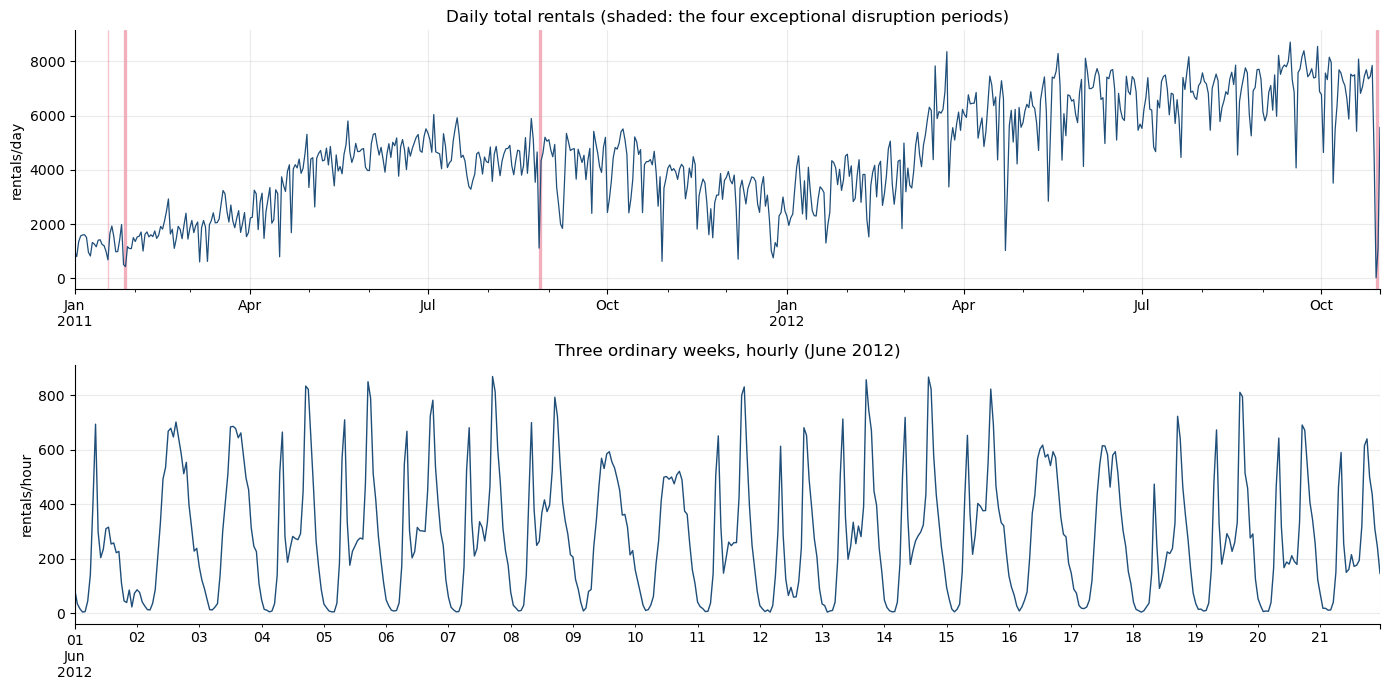

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7))
y.resample("D").sum().plot(ax=axes[0], lw=0.9, color="#1f4e79")
for _, r in runs[runs["kind"] == "disruption"].iterrows():
    axes[0].axvspan(r["start"], r["end"], color="crimson", alpha=0.25)
axes[0].set(title="Daily total rentals (shaded: the four exceptional disruption periods)",
            ylabel="rentals/day", xlabel="")
y.loc["2012-06-01":"2012-06-21"].plot(ax=axes[1], lw=1.0, color="#1f4e79")
axes[1].set(title="Three ordinary weeks, hourly (June 2012)", ylabel="rentals/hour", xlabel="")
plt.tight_layout(); plt.show()

       mean    std    max
year                     
2011  141.9  133.9  651.0
2012  242.3  214.2  977.0

Level ratio 2012/2011:          1.71x
Correlation of hourly profiles: 0.9996
Hour-by-hour ratio: min 1.44, max 1.79, sd 0.10


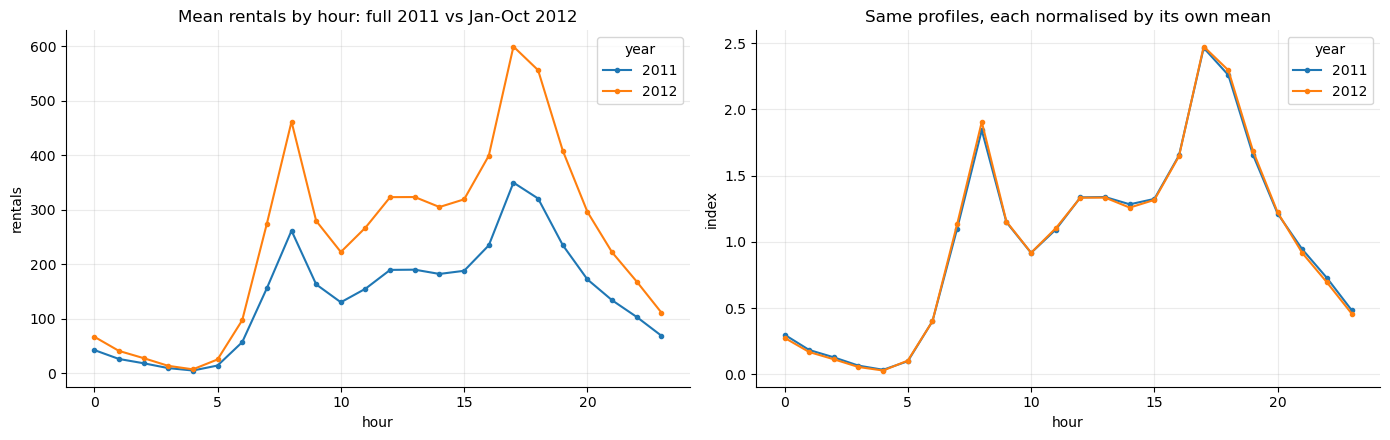

In [10]:
by_year = eda.groupby("year")["y"].agg(["mean", "std", "max"]).round(1)
profile = eda.pivot_table(index="hour", columns="year", values="y")
ratio = profile[2012] / profile[2011]
print(by_year.to_string())
print(f"\nLevel ratio 2012/2011:          {by_year.loc[2012,'mean']/by_year.loc[2011,'mean']:.2f}x")
print(f"Correlation of hourly profiles: {profile[2011].corr(profile[2012]):.4f}")
print(f"Hour-by-hour ratio: min {ratio.min():.2f}, max {ratio.max():.2f}, sd {ratio.std():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
profile.plot(ax=axes[0], marker="o", ms=3)
axes[0].set(title="Mean rentals by hour: full 2011 vs Jan-Oct 2012", xlabel="hour", ylabel="rentals")
(profile / profile.mean()).plot(ax=axes[1], marker="o", ms=3)
axes[1].set(title="Same profiles, each normalised by its own mean", xlabel="hour", ylabel="index")
plt.tight_layout(); plt.show()

The daily-total plot shows substantial changes over the development period, while the hourly view reveals repeated peaks and quiet overnight hours. These suggest that a forecast needs to represent both the rental level and the shape of the daily cycle.

The mean is **141.9 rentals per hour in 2011** and **242.3 in January–October 2012**, a ratio of **1.71**. Because the seasonal coverage differs, I do not interpret that ratio as a season-matched growth estimate or evidence of a discrete regime change.

The normalized hourly profiles nearly overlap, with correlation **0.9996**. Their unnormalized hour-by-hour ratios range from 1.44 to 1.79, so the scaling is approximate rather than exact. The observation motivates a representation in which seasonal amplitude can vary with level.

> **Decision 1.** Offer multiplicative seasonality and a log target as candidates. Their forecasting value will be judged on the tuning origins, rather than inferred from these descriptive profiles alone.

### 2.2 Daily Seasonality and Weekday-Dependent Shapes

STL separates a series into a smooth trend, a repeating seasonal component, and a remainder:

$$
y_t = T_t + S_t + R_t.
$$

I apply it at a 24-hour period to `y_grid`, then at a seven-day period to daily totals. The seasonal-strength statistic compares the remainder variance with the variance remaining after removing the trend; values closer to one indicate a stronger seasonal component in that decomposition.

Daily aggregation can hide differences within a day. I therefore also inspect the 168 hour–weekday means and compare weekday and weekend profiles.

Daily seasonality   F_S = 0.696
Weekly seasonality  F_S = 0.172   (on daily totals)
Trend strength      F_T = 0.832   (on daily totals)


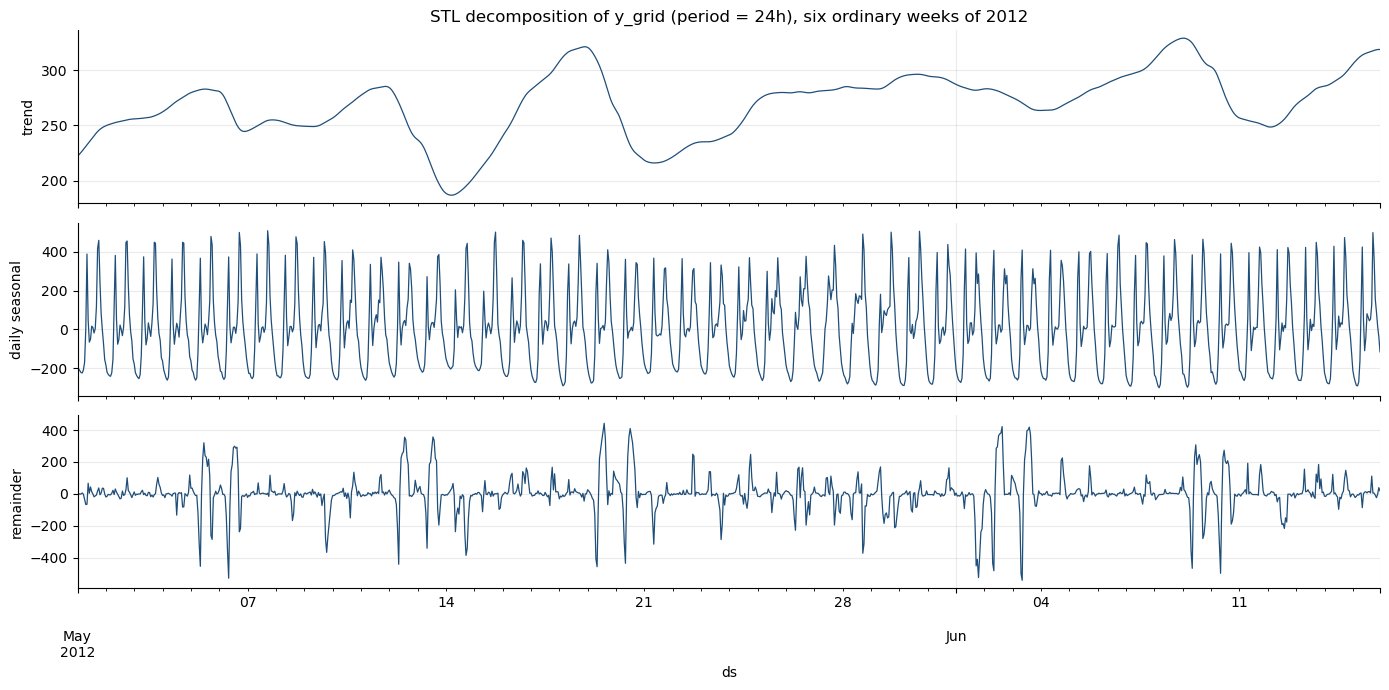

In [11]:
from statsmodels.tsa.seasonal import STL

stl_day = STL(y_grid, period=SEASON, robust=True).fit()
daily_total = y_grid.resample("D").sum()
stl_week = STL(daily_total, period=7, robust=True).fit()

def seasonal_strength(res):
    """Hyndman & Athanasopoulos F_S: 1 - Var(remainder) / Var(seasonal + remainder)."""
    return max(0.0, 1 - res.resid.var() / (res.seasonal + res.resid).var())

def trend_strength(res):
    return max(0.0, 1 - res.resid.var() / (res.trend + res.resid).var())

print(f"Daily seasonality   F_S = {seasonal_strength(stl_day):.3f}")
print(f"Weekly seasonality  F_S = {seasonal_strength(stl_week):.3f}   (on daily totals)")
print(f"Trend strength      F_T = {trend_strength(stl_week):.3f}   (on daily totals)")

fig, axes = plt.subplots(3, 1, figsize=(14, 7), sharex=True)
for ax, comp, name in zip(axes, [stl_day.trend, stl_day.seasonal, stl_day.resid],
                          ["trend", "daily seasonal", "remainder"]):
    comp.loc["2012-05-01":"2012-06-15"].plot(ax=ax, lw=0.9, color="#1f4e79")
    ax.set_ylabel(name)
axes[0].set_title("STL decomposition of y_grid (period = 24h), six ordinary weeks of 2012")
plt.tight_layout(); plt.show()

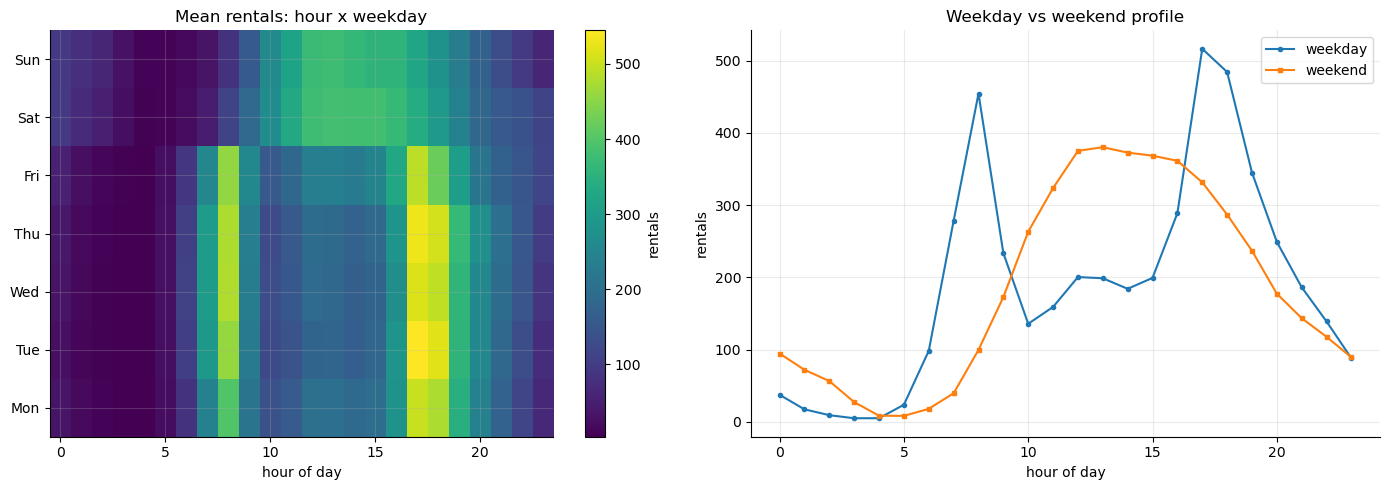

            weekday  weekend   ratio
  08:00       454.3     99.5    4.56x
  12:00       200.3    375.0    0.53x
  17:00       516.2    331.5    1.56x
  22:00       138.9    117.6    1.18x

Additive hour + weekday model on this grid: R^2 = 0.797
Share of grid structure that is pure interaction: 20.3%


In [12]:
hw = eda.pivot_table(index="hour", columns="weekday", values="y")
hw.columns = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
im = axes[0].imshow(hw.T, aspect="auto", cmap="viridis", origin="lower")
axes[0].set(title="Mean rentals: hour x weekday", xlabel="hour of day",
            yticks=range(7), yticklabels=hw.columns)
plt.colorbar(im, ax=axes[0], label="rentals")
hw[["Mon", "Tue", "Wed", "Thu", "Fri"]].mean(axis=1).plot(ax=axes[1], marker="o", ms=3, label="weekday")
hw[["Sat", "Sun"]].mean(axis=1).plot(ax=axes[1], marker="s", ms=3, label="weekend")
axes[1].set(title="Weekday vs weekend profile", xlabel="hour of day", ylabel="rentals")
axes[1].legend()
plt.tight_layout(); plt.show()

wk = hw[["Mon", "Tue", "Wed", "Thu", "Fri"]].mean(axis=1)
we = hw[["Sat", "Sun"]].mean(axis=1)
print("            weekday  weekend   ratio")
for h in [8, 12, 17, 22]:
    print(f"  {h:02d}:00     {wk[h]:7.1f}  {we[h]:7.1f}   {wk[h]/we[h]:5.2f}x")

grid = eda.groupby(["hour", "weekday"])["y"].mean().reset_index()
additive = (grid.groupby("hour")["y"].transform("mean")
            + grid.groupby("weekday")["y"].transform("mean") - grid["y"].mean())
r2 = 1 - ((grid["y"] - additive) ** 2).sum() / ((grid["y"] - grid["y"].mean()) ** 2).sum()
print(f"\nAdditive hour + weekday model on this grid: R^2 = {r2:.3f}")
print(f"Share of grid structure that is pure interaction: {1 - r2:.1%}")

The decomposition reports **daily seasonal strength 0.696**, **weekly strength on daily totals 0.172**, and **trend strength on daily totals 0.832**. These summaries describe different resolutions: weak weekly repetition in daily totals does not imply that weekday is unimportant for hourly forecasts.

The heatmap shows why. At **08:00**, the weekday mean is **4.56 times** the weekend mean; at **12:00**, it is only **0.53 times** the weekend mean. The direction of the weekday–weekend difference changes with the hour. These shapes are compatible with different travel routines, but the aggregate counts do not identify riders' purposes.

An additive hour-plus-weekday representation explains **79.7% of the variation across the 168 mean cells**. The remaining **20.3%** is interaction structure in that grid, not 20.3% of all hourly rental variation.

In an additive linear model, separate hour and weekday terms cannot represent this changing profile without interactions. Adding separate sine/cosine harmonics does not remove that restriction. Nonlinear learners can combine the same inputs through interactions; the limitation belongs to the additive model. The [scikit-learn example](https://scikit-learn.org/stable/auto_examples/applications/plot_cyclical_feature_engineering.html) illustrates these representations.

> **Decision 2.** Represent the hour–weekday interaction explicitly for Ridge, and give the tree models inputs from which they can learn it. This motivates the representations; it does not establish which estimator will forecast better.

> **Decision 3.** Preserve weekday-dependent hourly shapes. A weekly level adjustment alone would miss them, although weekly terms can still contribute to a candidate such as Prophet.

### 2.3 Stationarity and the Case for Seasonal Differencing

A series is weakly stationary when its mean and variance are constant and its autocovariances depend on lag rather than calendar time. This matters for interpreting ARIMA dynamics, but a single test does not settle the representation.

I use two complementary tests:

- **ADF:** the null is a unit root in the tested specification.
- **KPSS:** the null is stationarity around a constant, or around a deterministic linear trend in its separate trend specification.

I compare the raw grid with the 24-hour difference, `y_grid.diff(24)`, alongside their ACF and PACF plots. Seasonal differencing subtracts the same clock position one day earlier:

$$
\Delta_{24}y_t = y_t-y_{t-24}.
$$

ADF        H0: a unit root is present              (reject -> no unit root)
KPSS(level) H0: stationary around a constant        (reject -> not level-stationary)
KPSS(trend) H0: stationary around a linear trend    (reject -> not trend-stationary)



/var/folders/5f/dq45wr613kb8f2bwp4zr0gpc0000gn/T/ipykernel_42824/37221966.py:8: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_c  = kpss(x, regression="c",  nlags="auto")[1]
/var/folders/5f/dq45wr613kb8f2bwp4zr0gpc0000gn/T/ipykernel_42824/37221966.py:9: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_ct = kpss(x, regression="ct", nlags="auto")[1]


raw series                   ADF p= 0.0000   KPSS(level) p= 0.0100   KPSS(trend) p= 0.0100


/var/folders/5f/dq45wr613kb8f2bwp4zr0gpc0000gn/T/ipykernel_42824/37221966.py:8: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_c  = kpss(x, regression="c",  nlags="auto")[1]
/var/folders/5f/dq45wr613kb8f2bwp4zr0gpc0000gn/T/ipykernel_42824/37221966.py:9: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_ct = kpss(x, regression="ct", nlags="auto")[1]


seasonally differenced (24h) ADF p= 0.0000   KPSS(level) p= 0.1000   KPSS(trend) p= 0.1000


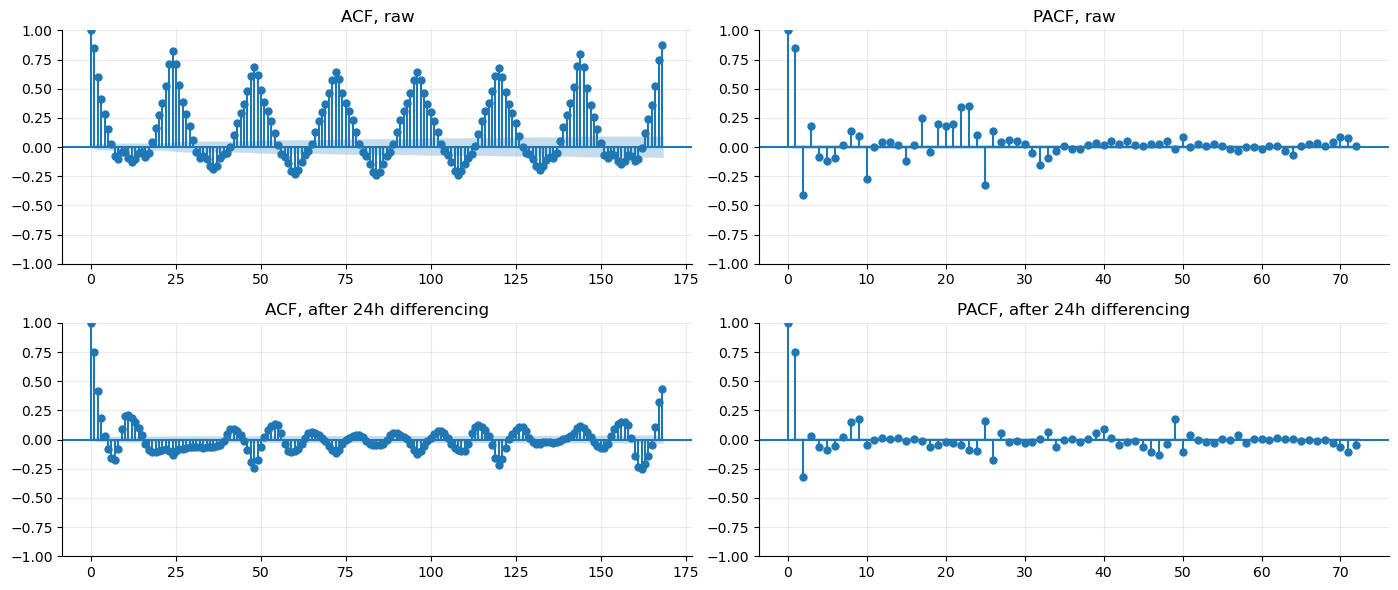

In [13]:
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

def stationarity(x, label):
    adf_p = adfuller(x)[1]
    # KPSS's null depends on its `regression` argument, so run BOTH: "c" tests
    # stationarity around a constant, "ct" around a deterministic trend.
    kpss_c  = kpss(x, regression="c",  nlags="auto")[1]
    kpss_ct = kpss(x, regression="ct", nlags="auto")[1]
    print(f"{label:28s} ADF p={adf_p:7.4f}   KPSS(level) p={kpss_c:7.4f}   KPSS(trend) p={kpss_ct:7.4f}")

print("ADF        H0: a unit root is present              (reject -> no unit root)")
print("KPSS(level) H0: stationary around a constant        (reject -> not level-stationary)")
print("KPSS(trend) H0: stationary around a linear trend    (reject -> not trend-stationary)")
print()
stationarity(y_grid.values, "raw series")
stationarity(y_grid.diff(SEASON).dropna().values, "seasonally differenced (24h)")

fig, axes = plt.subplots(2, 2, figsize=(14, 6))
plot_acf(y_grid, lags=WEEK, ax=axes[0, 0]);  axes[0, 0].set_title("ACF, raw")
plot_pacf(y_grid, lags=72, ax=axes[0, 1], method="ywm"); axes[0, 1].set_title("PACF, raw")
sd = y_grid.diff(SEASON).dropna()
plot_acf(sd, lags=WEEK, ax=axes[1, 0]); axes[1, 0].set_title("ACF, after 24h differencing")
plot_pacf(sd, lags=72, ax=axes[1, 1], method="ywm"); axes[1, 1].set_title("PACF, after 24h differencing")
plt.tight_layout(); plt.show()

For the **raw series**, ADF rejects its unit-root null, while both KPSS specifications reject their stationarity nulls. The tests therefore do not support a simple description such as “a unit root is present” or “the series is stationary around a linear trend.”

After **24-hour differencing**, ADF still rejects, while neither KPSS test rejects at the usual 5% level. This is consistent with the differenced representation being more suitable for these diagnostics, without proving stationarity.

The KPSS warnings explain the printed boundary values: the raw-series p-values are below the table's lower limit of **0.01**, and the differenced-series p-values are above its upper limit of **0.10**. They are bounds, not exact p-values. Likewise, ADF's displayed `0.0000` is rounded.

The ACF shows reduced daily dependence after differencing, although structure remains. These results motivate a candidate specification rather than determine an optimal forecasting model.

> **Decision 4.** Evaluate SARIMA with `d=0, D=1, s=24`. The later experiment evaluates that specified procedure; it does not isolate the benefit of seasonal differencing against an otherwise identical `D=0` model. A trend feature offers another candidate representation of changing levels.

### 2.4 Which Historical Values Are Available Across the Forecast Path?

Strong correlation is useful only if the corresponding observation is available when the forecast is issued. I examine pairwise-complete lag correlations, then check which lags can be used at every step of a 48-hour path. The shaded region in the plot refers to availability at **step 48**, not to every earlier step.

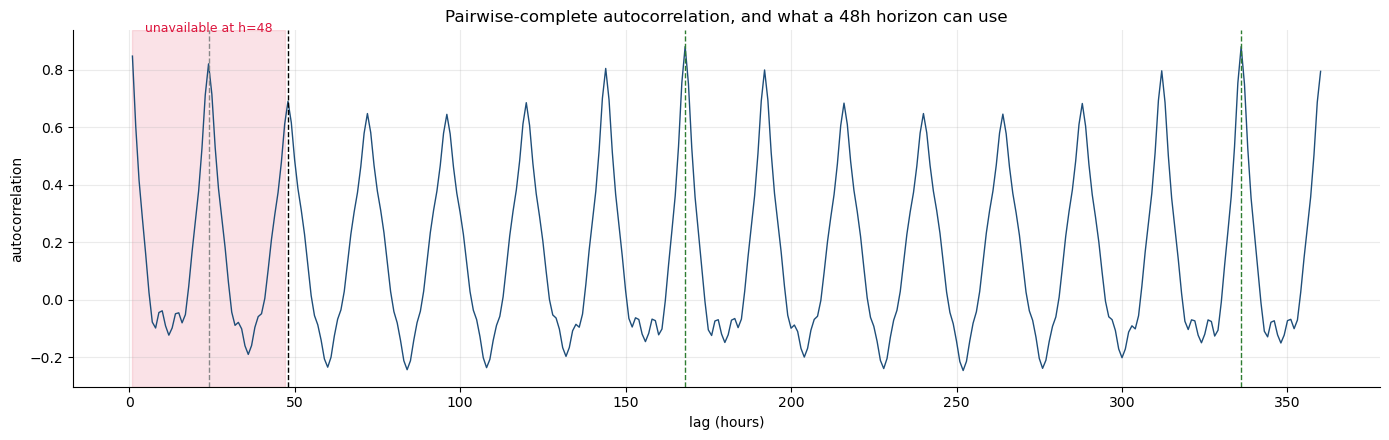

Correlation of y_t with candidate lags (pairwise-complete, no imputation):
  lag   1h  r = 0.8474   n = 16075   NOT usable at h=48
  lag  24h  r = 0.8205   n = 16052   NOT usable at h=48
  lag  48h  r = 0.6900   n = 16028   usable at h=48
  lag  72h  r = 0.6474   n = 16004   usable at h=48
  lag  96h  r = 0.6447   n = 15980   usable at h=48
  lag 120h  r = 0.6852   n = 15956   usable at h=48
  lag 144h  r = 0.8044   n = 15932   usable at h=48
  lag 168h  r = 0.8807   n = 15908   usable at h=48
  lag 336h  r = 0.8803   n = 15740   usable at h=48

Most informative *usable* lag: 168h (r = 0.8807)


In [14]:
# Pairwise-complete on the reconstructed target, which includes inferred zeros.
# Both endpoints must be non-NaN; no additional filling is used for this calculation.
arr = y.to_numpy()
max_lag = 2 * WEEK + 24
ac, n_used = {}, {}
for L in range(1, max_lag + 1):
    b = np.full_like(arr, np.nan); b[L:] = arr[:-L]
    ok = np.isfinite(arr) & np.isfinite(b)
    ac[L] = np.corrcoef(arr[ok], b[ok])[0, 1]; n_used[L] = int(ok.sum())
ac = pd.Series(ac)

fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(ac.index, ac.values, lw=1.0, color="#1f4e79")
ax.axvspan(1, HORIZON - 1, color="crimson", alpha=0.12)
ax.text(HORIZON / 2, 0.93, "unavailable at h=48", ha="center", color="crimson", fontsize=9)
for L, c in [(SEASON, "#888"), (HORIZON, "#000"), (WEEK, "#2e7d32"), (2 * WEEK, "#2e7d32")]:
    ax.axvline(L, color=c, ls="--", lw=1)
ax.set(title="Pairwise-complete autocorrelation, and what a 48h horizon can use",
       xlabel="lag (hours)", ylabel="autocorrelation")
plt.tight_layout(); plt.show()

print("Correlation of y_t with candidate lags (pairwise-complete, no imputation):")
for L in [1, 24, 48, 72, 96, 120, 144, 168, 336]:
    print(f"  lag {L:3d}h  r = {ac[L]:.4f}   n = {n_used[L]:5d}   "
          f"{'usable at h=48' if L >= HORIZON else 'NOT usable at h=48'}")
best = ac[ac.index >= HORIZON].idxmax()
print(f"\nMost informative *usable* lag: {best}h (r = {ac[best]:.4f})")

The strongest correlation among the examined lags usable at step 48 is **0.8807 at 168 hours**, the same hour one week earlier. Lag 336 is similar at **0.8803**, compared with **0.6900 at lag 48**. Weekly alignment is therefore a useful candidate source of information.

Availability depends on indexing. Here, origin `o` is the timestamp of the **first prediction**, and observations must precede it. At step `h`, a target-relative lag `L` reads

$$
o+(h-1)-L.
$$

This precedes the origin when

$$
o+(h-1)-L < o
\quad\Longleftrightarrow\quad L\ge h
$$

for integer hourly steps. Lag 1 is available at step 1, and lag 24 through the first forecast day, but neither is available throughout the path.

I use **one shared lag policy with every lag at least 48 hours** for the feature-based regressors. This makes the same definitions feasible at all 48 steps. It deliberately leaves some recent information unused at earlier steps; it is a modelling choice, not a universal restriction on forecasting.

> **Decision 5.** Include lags 48–72 for recent history, weekly-aligned lags, and hour-of-week summaries. Section 5 specifies the final columns. The printed “most informative” lag means the largest marginal correlation in the examined range, not a measured incremental contribution to a fitted model.

### 2.5 Rental Levels, Variability, and the Error Metric

I examine the count distribution and compare each day's standard deviation with its mean. Their ratio, the **coefficient of variation**, asks whether spread changes approximately in proportion to level. These are descriptive summaries of rentals within days, not yet measurements of forecasting-error variance.

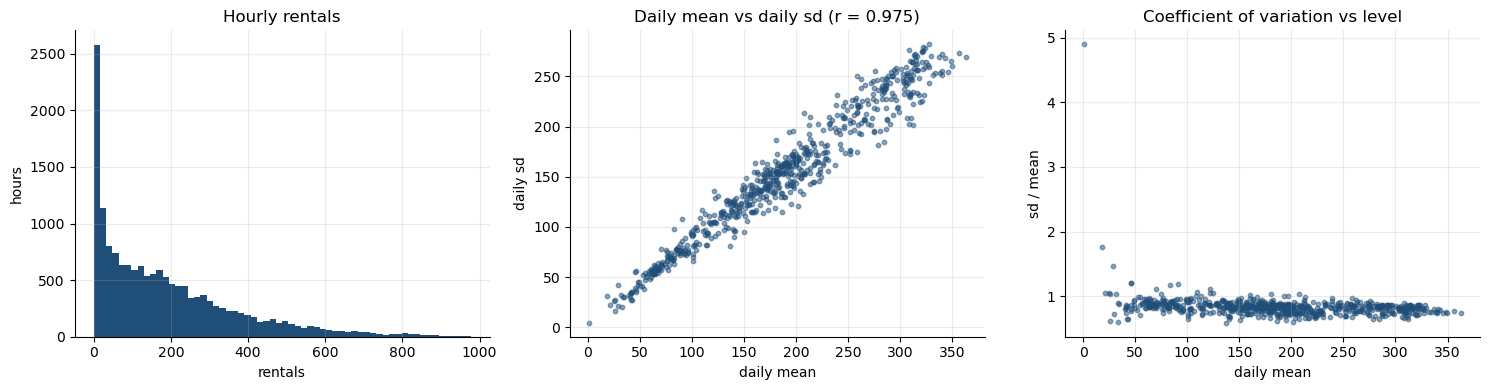

Variance-vs-level correlation:      0.975
Mean CV, quietest quartile of days: 0.908
Mean CV, busiest quartile of days:  0.803
Skewness: 1.30
Hours with y <= 5: 1158 (7.2%)   of which exactly zero: 159


In [15]:
# NB: named daily_stats, not `daily` -- Section 1 binds `daily` to the daily
# calendar table and the calendar reconstruction depends on it.
daily_stats = y.resample("D").agg(["mean", "std"]).dropna()
lvl_corr = daily_stats["mean"].corr(daily_stats["std"])

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(y.dropna(), bins=60, color="#1f4e79")
axes[0].set(title="Hourly rentals", xlabel="rentals", ylabel="hours")
axes[1].scatter(daily_stats["mean"], daily_stats["std"], s=10, alpha=0.5, color="#1f4e79")
axes[1].set(title=f"Daily mean vs daily sd (r = {lvl_corr:.3f})", xlabel="daily mean", ylabel="daily sd")
axes[2].scatter(daily_stats["mean"], daily_stats["std"] / daily_stats["mean"], s=10, alpha=0.5, color="#1f4e79")
axes[2].set(title="Coefficient of variation vs level", xlabel="daily mean", ylabel="sd / mean")
plt.tight_layout(); plt.show()

cv = daily_stats["std"] / daily_stats["mean"]
print(f"Variance-vs-level correlation:      {lvl_corr:.3f}")
print(f"Mean CV, quietest quartile of days: {cv[daily_stats['mean'] < daily_stats['mean'].quantile(.25)].mean():.3f}")
print(f"Mean CV, busiest quartile of days:  {cv[daily_stats['mean'] > daily_stats['mean'].quantile(.75)].mean():.3f}")
print(f"Skewness: {y.skew():.2f}")
print(f"Hours with y <= 5: {int((y <= 5).sum())} ({(y <= 5).mean():.1%})   of which exactly zero: {int((y == 0).sum())}")

Daily mean and standard deviation have correlation **0.975**. The average coefficient of variation is **0.908** in the quietest quartile and **0.803** in the busiest. Absolute spread increases strongly with level, while relative spread is broadly similar across those groups. This supports trying a log scale without establishing that it will improve forecasts.

There are **1,158 positions at five rentals or fewer**, approximately **7.2%** of the development grid, including **159 inferred zeros**. MAPE is undefined at zero and can give disproportionate weight to tiny denominators.

> **Decision 6.** Use **MAE as the primary selection metric**, with RMSE and MASE alongside it. MAE expresses average error in rentals and weights each rental of error equally; RMSE gives larger misses more influence. This is an evaluation choice, not a measured operational cost function. Section 3 defines the training-based denominator used for MASE.

### 2.6 Weather: Associations and Information Availability

Calendar profiles cannot describe every change in rentals. I next inspect marginal associations with temperature, humidity, and wind speed to ask whether weather is worth investigating.

The curves use ten **equal-width bins**, whose observation counts can differ. This is retrospective EDA using the weather-filled development frame from Section 1. Those fills are not automatically suitable for forecasting; Section 5 rebuilds a separate causal weather source for the deployable experiment.

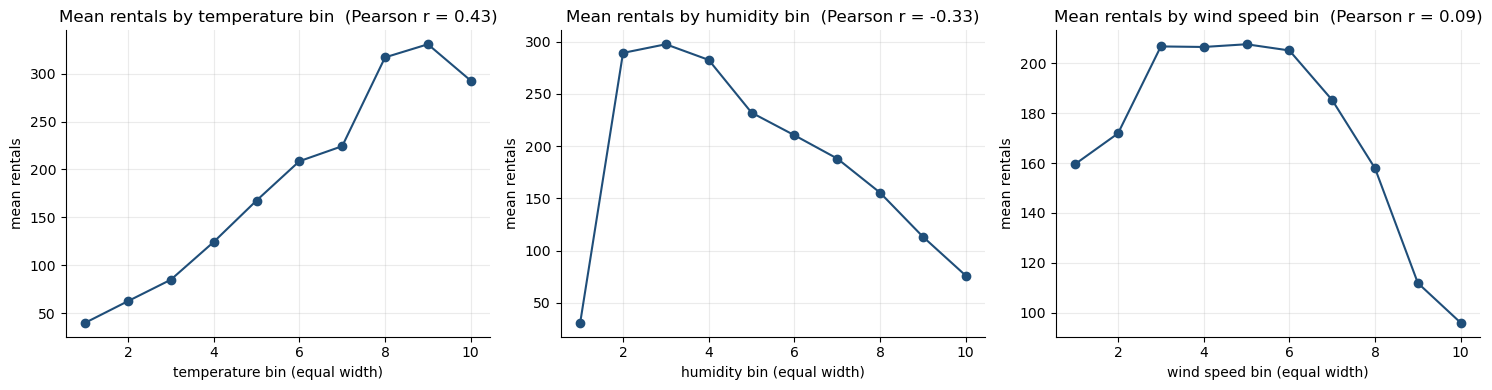

Mean rentals by equal-width temperature bin:
     40     63     85    124    168    209    224    317    331    293
Peak at bin 9/10; top bin falls to 293 from a peak of 331  (-11.5%)

Pearson correlation with demand:
  temp        +0.430
  hum         -0.329
  windspeed   +0.088
  weathersit  -0.154


In [16]:
ex = eda.copy()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for col, ax, name in [("temp", axes[0], "temperature"), ("hum", axes[1], "humidity"),
                      ("windspeed", axes[2], "wind speed")]:
    b = ex.groupby(pd.cut(ex[col], bins=10), observed=True)["y"].mean()
    ax.plot(range(1, len(b) + 1), b.values, marker="o", color="#1f4e79")
    ax.set(title=f"Mean rentals by {name} bin  (Pearson r = {ex[col].corr(ex['y']):.2f})",
           xlabel=f"{name} bin (equal width)", ylabel="mean rentals")
plt.tight_layout(); plt.show()

tb = ex.groupby(pd.cut(ex["temp"], bins=10), observed=True)["y"].mean()
print("Mean rentals by equal-width temperature bin:")
print("  " + "  ".join(f"{v:5.0f}" for v in tb.values))
print(f"Peak at bin {int(np.argmax(tb.values))+1}/10; top bin falls to {tb.values[-1]:.0f} "
      f"from a peak of {tb.max():.0f}  ({tb.values[-1]/tb.max()-1:+.1%})")
print()
print("Pearson correlation with demand:")
for c in ["temp", "hum", "windspeed", "weathersit"]:
    print(f"  {c:11s} {ex[c].corr(ex['y']):+.3f}")

Temperature has correlation **+0.430** with recorded rentals. Its binned means peak in bin 9 and fall **11.5%** in the hottest bin. Humidity has correlation **−0.329**, while wind speed has a weak marginal linear correlation of **+0.088** despite a visibly nonlinear binned profile.

These are associations averaged across seasons, hours, and other conditions. They do not identify causal weather responses or demonstrate that future weather will improve a forecast.

> **Decision 7.** Allow flexible weather relationships in a later feature-based comparison. Tree models can represent nonlinear associations; the marginal curves motivate that flexibility without determining the required shape.

> **Decision 8.** Separate information that is available at issuance from realized weather at the target hour. The main model comparison excludes weather. Section 8 tests lagged observations separately from a clearly labelled oracle-information scenario.

### 2.7 Unusual Observations and Heavy-Tailed Remainders

A large deviation at a busy hour need not be as unusual as the same deviation overnight. I compare STL remainders on the raw and `log1p` scales, then inspect standardized tails against a Gaussian reference.

The additional contiguous-segment check excludes labelled disruptions and DST gaps while retaining ordinary inferred zeros. It asks whether extreme remainders persist outside those labelled episodes.

In [17]:
from scipy import stats

# Section 2.1 motivated multiplicative scaling, so anomalies are measured on the
# log scale. On the raw scale the STL remainder is wildly heteroscedastic and a single
# global threshold would be meaningless -- shown here rather than asserted.
resid_raw = STL(y_grid, period=SEASON, robust=True).fit().resid
resid_log = STL(np.log1p(y_grid), period=SEASON, robust=True).fit().resid
sd_raw = resid_raw.groupby(resid_raw.index.hour).std()
sd_log = resid_log.groupby(resid_log.index.hour).std()
print("Remainder sd at 04:00 vs 17:00 -- the case for working on the log scale")
print(f"  raw scale: {sd_raw[4]:8.2f}  vs {sd_raw[17]:8.2f}   ({sd_raw[17]/sd_raw[4]:.1f}x)")
print(f"  log scale: {sd_log[4]:8.2f}  vs {sd_log[17]:8.2f}   ({sd_log[17]/sd_log[4]:.1f}x)")

# The 83 disruption zeros are extreme by construction, so the tail statistics are
# corroborated on the longest contiguous stretch excluding disruption and DST gaps.
# Ordinary inferred zeros remain. Requiring y.notna() excludes the 2012-03-11 DST
# hour, which is filled only in y_grid.
ok = ((~df["is_disruption"]) & df["y"].notna()).to_numpy()
best, run = (0, 0, 0), 0
for i, v in enumerate(np.append(ok, False)):
    if v: run += 1
    else:
        if run > best[2]: best = (i - run, i, run)
        run = 0
clean = df.index[best[0]:best[1]]
print(f"\nLongest contiguous stretch (no disruption/DST gap; inferred zeros retained):")
print(f"  {clean.min()} -> {clean.max()}  ({len(clean)} h = {len(clean)/24/7:.0f} weeks)")

print()
print(f"  {'series':26s} {'kurtosis':>9s} {'|z|>3':>8s} {'|z|>4':>9s}")
for name, ser in [("primary (all hours)", np.log1p(y_grid)),
                  ("contiguous stretch", np.log1p(y.loc[clean]))]:
    r = STL(ser.asfreq("h"), period=SEASON, robust=True).fit().resid
    z = (r - r.mean()) / r.std()
    o3, o4 = (z.abs() > 3).mean(), (z.abs() > 4).mean()
    print(f"  {name:26s} {stats.kurtosis(r.dropna()):9.2f} "
          f"{o3/(2*(1-stats.norm.cdf(3))):7.0f}x {o4/(2*(1-stats.norm.cdf(4))):8.0f}x")
print(f"\n  (a Gaussian would put {2*(1-stats.norm.cdf(3)):.3%} beyond 3 sd and "
      f"{2*(1-stats.norm.cdf(4)):.4%} beyond 4 sd)")

Remainder sd at 04:00 vs 17:00 -- the case for working on the log scale
  raw scale:     8.49  vs   136.26   (16.0x)
  log scale:     0.42  vs     0.46   (1.1x)

Longest contiguous stretch (no disruption/DST gap; inferred zeros retained):
  2012-03-11 03:00:00 -> 2012-10-29 00:00:00  (5566 h = 33 weeks)

  series                      kurtosis    |z|>3     |z|>4


  primary (all hours)            18.71       9x      104x


  contiguous stretch              6.28      12x      128x

  (a Gaussian would put 0.270% beyond 3 sd and 0.0063% beyond 4 sd)


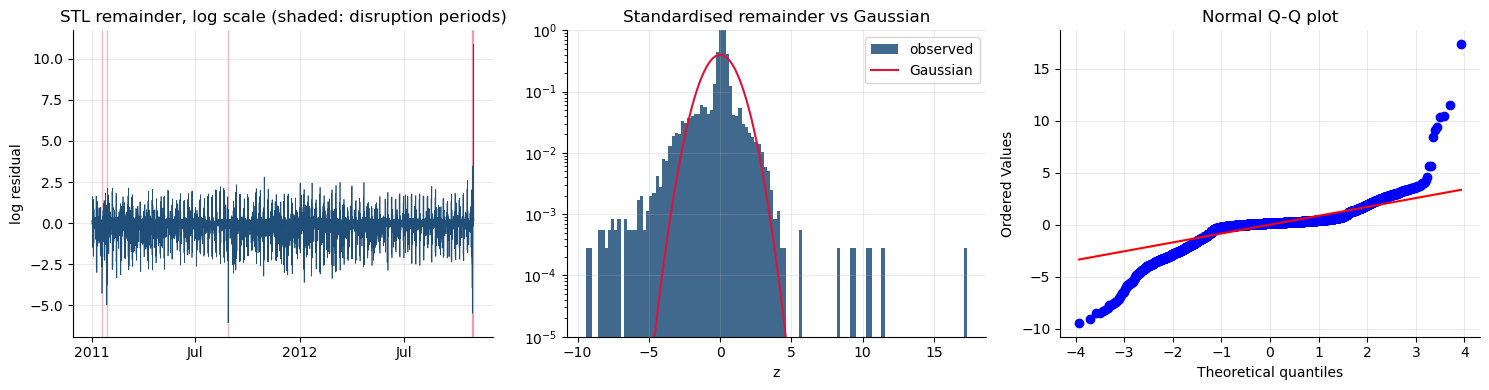

Most anomalous days:
  2012-10-31   max |z| =  17.3   daily total =  5,566   
  2011-08-27   max |z| =   9.4   daily total =  1,115   disruption
  2012-10-29   max |z| =   8.5   daily total =     22   disruption
  2011-08-28   max |z| =   7.7   daily total =  4,334   disruption
  2011-01-26   max |z| =   7.7   daily total =    506   disruption
  2011-01-18   max |z| =   6.6   daily total =    683   disruption


In [18]:
z = (resid_log - resid_log.mean()) / resid_log.std()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(resid_log.index, resid_log.values, lw=0.5, color="#1f4e79")
for _, r in runs[runs["kind"] == "disruption"].iterrows():
    axes[0].axvspan(r["start"], r["end"], color="crimson", alpha=0.3)
axes[0].set(title="STL remainder, log scale (shaded: disruption periods)", ylabel="log residual", xlabel="")
axes[1].hist(z.dropna(), bins=120, density=True, color="#1f4e79", alpha=0.85, label="observed")
xs = np.linspace(-8, 8, 400)
axes[1].plot(xs, stats.norm.pdf(xs), "crimson", lw=1.5, label="Gaussian")
axes[1].set(title="Standardised remainder vs Gaussian", xlabel="z", yscale="log", ylim=(1e-5, 1))
axes[1].legend()
stats.probplot(z.dropna(), dist="norm", plot=axes[2]); axes[2].set_title("Normal Q-Q plot")
from matplotlib.dates import AutoDateLocator, ConciseDateFormatter
_date_locator = AutoDateLocator(minticks=3, maxticks=5)
axes[0].xaxis.set_major_locator(_date_locator)
axes[0].xaxis.set_major_formatter(ConciseDateFormatter(_date_locator))
plt.tight_layout(); plt.show()

worst = z.abs().resample("D").max().nlargest(6)
print("Most anomalous days:")
for d, v in worst.items():
    tot = y.loc[y.index.normalize() == d.normalize()].sum()
    flag = "disruption" if df.loc[df.index.normalize() == d.normalize(), "is_disruption"].any() else ""
    print(f"  {d.date()}   max |z| = {v:5.1f}   daily total = {tot:6,.0f}   {flag}")

On the raw scale, remainder standard deviations are **8.49 at 04:00** and **136.26 at 17:00**, a **16-fold** difference. On the log scale they are **0.42 and 0.46**, a ratio of **1.1**. The log scale therefore makes this particular cross-hour anomaly comparison more comparable; it does not establish constant variance everywhere.

The log-scale remainders have **excess kurtosis 18.71** over the full grid and **6.28** on the 5,566-hour contiguous segment. Three-standard-deviation exceedances occur approximately **9 and 12 times** as often as under a Gaussian reference; four-standard-deviation exceedances occur **104 and 128 times** as often. Each analysis estimates its own scale, and the selected segment also changes the date range, so this is not an isolated intervention removing disruption effects.

The Q–Q plot and these summaries show heavier empirical tails than the Gaussian reference in both populations. The anomaly table also identifies **October 31, 2012** as the largest standardized deviation, although it is not disruption-labelled. The missing-run rule is therefore not a general detector of every unusual rental observation; this retrospective ranking is not used to relabel the target.

These are **STL remainders**, not out-of-sample forecast errors. They motivate evaluating uncertainty empirically rather than predicting a coverage failure in advance.

> **Decision 9.** Retain unusual observations in the primary target and scoring population. The separately disclosed lag-source substitutions remain a feature-policy choice, not target deletion.

> **Decision 10.** Measure interval coverage and width. Compare a Gaussian residual construction, empirical absolute-residual intervals using the conformal calibration rank, and Prophet's native intervals within their stated scopes.

### From Exploration to Forecasting Design

| Decision | Evidence from the development data | Choice to investigate |
|:---|:---|:---|
| 1 | Similar normalized profiles across unequal date ranges | Multiplicative seasonality and log targets |
| 2 | Additive terms leave 20.3% of the 168-cell mean-grid variation unexplained | Explicit hour–weekday interactions |
| 3 | Weak weekly strength in daily totals coexists with changing hourly profiles | Preserve weekly alignment at hourly resolution |
| 4 | Raw and differenced diagnostics favor different descriptions | Evaluate a 24-hour seasonal-difference SARIMA candidate |
| 5 | Lag 168 has the largest examined correlation available at step 48 | Weekly lags and hour-of-week summaries |
| 6 | Many small counts and 159 inferred zeros | MAE primary; RMSE and MASE alongside; omit MAPE |
| 7 | Weather-bin associations are nonlinear | Allow flexible weather relationships |
| 8 | Realized future weather is unavailable at issuance | Separate lagged weather from an oracle scenario |
| 9 | Extreme remainders also occur outside labelled disruptions | Preserve unusual primary targets |
| 10 | Empirical STL remainder tails differ from a Gaussian reference | Assess forecast-interval coverage and width |

These choices were informed by the **full development period**, including the later selection targets. The evaluation is therefore developmental: chronological fitting and early tuning do not make the broader feature-design process independent of those targets.

Sections 3–7 compare calendar/history procedures. Section 8 introduces weather and evaluates uncertainty before the final block is opened.

## Section 3: A Common Chronological Evaluation

The model comparison needs a common forecasting task before it needs another model. I use **92 origins**, issued at midnight every two calendar days, from April 30 through October 29, 2012. Their complete paths cover April 30 through October 30: **4,416 hourly targets per procedure**.

At each origin, the harness passes only earlier rows to the fitting function. It stores one row per forecast hour with the model, origin, horizon step, target, prediction, and training-based MASE scale. Scores, paired comparisons, and later calibration read those stored forecasts.

Primary scoring retains every eligible target inside the paths, including the **36 Sandy hours**. The other 47 disruption-labelled development hours occur earlier in history. The secondary view changes only which stored errors are summarized.

Because paths do not overlap, no target is scored twice within a model. **Nonoverlap does not establish independence:** paths share expanding training histories and can share changing conditions.

### Reading Horizon and Clock-Hour Plots

Every path starts at midnight. Steps 1 and 25 both predict 00:00; steps 18 and 42 both predict 17:00. A horizon-step curve therefore mixes lead time with clock hour and forecast day.

Comparing the two forecast days at the same clock hour removes the clock-hour difference, but date, weekday, weather, and other conditions still change. I retain this distinction when interpreting the plots.

In [19]:
def make_origins(index_end, n_months=6, spacing=HORIZON, first_day=None):
    start = pd.Timestamp((index_end - pd.DateOffset(months=n_months)).date()) if first_day is None else first_day
    origins, t = [], start
    while t + pd.Timedelta(hours=HORIZON - 1) <= index_end:
        origins.append(t); t += pd.Timedelta(hours=spacing)
    return origins

_origins = make_origins(df.index.max())
cv_folds = pd.DataFrame({"fold": range(1, len(_origins) + 1), "val_start": _origins})
cv_folds["val_end"] = cv_folds["val_start"] + pd.Timedelta(hours=HORIZON - 1)
cv_folds["n_train"] = [int((df.index < s).sum()) for s in cv_folds["val_start"]]
cv_folds["disruption_hours"] = [int(df.loc[s:e, "is_disruption"].sum())
                                for s, e in zip(cv_folds["val_start"], cv_folds["val_end"])]

print(f"Rolling origins: {len(cv_folds)}")
print(f"Span: {cv_folds['val_start'].min()} -> {cv_folds['val_end'].max()}")
print(f"Origins whose window overlaps a disruption period: "
      f"{int((cv_folds['disruption_hours'] > 0).sum())}  (retained -- those hours are scored zeros)")
assert cv_folds["val_end"].max() < EVAL_START
assert cv_folds["n_train"].is_monotonic_increasing

Rolling origins: 92
Span: 2012-04-30 00:00:00 -> 2012-10-30 23:00:00
Origins whose window overlaps a disruption period: 1  (retained -- those hours are scored zeros)


### Metrics: Error in Rentals, Large Misses, and a Training-Based Scale

For errors $e_j=y_j-\hat y_j$ across $N$ scored hours,

$$
\operatorname{MAE}=\frac{1}{N}\sum_j |e_j|,
\qquad
\operatorname{RMSE}=\sqrt{\frac{1}{N}\sum_j e_j^2}.
$$

**MAE determines selection.** It remains in rental units and gives equal weight to each unit of absolute error. RMSE emphasizes large misses. The reported RMSE is pooled across hourly errors, rather than averaged across path-specific RMSEs; those operations generally differ.

For each origin $i$, MASE uses the mean absolute 24-hour difference in that origin's training target:

$$
s_i=\operatorname{mean}_{t\in\text{training}_i}|y_t-y_{t-24}|,
\qquad
\operatorname{MASE}=\frac{1}{N}\sum_j\frac{|e_j|}{s_{i(j)}}.
$$

Only pairs with available target values contribute to the scale. Each scored error is divided by its own origin's scale before aggregation.

**MASE below one means error below this in-sample seasonal-difference scale.** It does not establish a win over either seasonal-naive forecast on the 48-hour evaluation paths. Those comparisons require their actual forecast errors.

The next cell's whole-development scale of **63.69 rentals** is an illustration. The harness computes a separate scale using only the history available at each origin.

In [20]:
def mase_scale(train_y, season=SEASON):
    """In-sample one-step seasonal-difference scale on the training slice. NaN-safe."""
    a = np.asarray(train_y, dtype=float)
    return np.nanmean(np.abs(a[season:] - a[:-season]))

def score_frame(g):
    """MAE / RMSE / MASE for one group of stored predictions."""
    err = g["y_true"].to_numpy() - g["y_pred"].to_numpy()
    return pd.Series({
        "MAE": np.mean(np.abs(err)),
        "RMSE": np.sqrt(np.mean(err ** 2)),
        # per-ROW scaling: the fold scale drifts across the expanding window
        "MASE": np.mean(np.abs(err) / g["mase_scale"].to_numpy()),
        "n": len(g),
    })

_s = mase_scale(df["y"].to_numpy())
print(f"MASE scale over the whole development region (m=24): {_s:.2f} rentals")
print(f"  a model with MAE 60 scores MASE {60/_s:.3f} -- against the in-sample one-step scale,")
print(f"  not against a 48h-ahead seasonal-naive forecast.")

MASE scale over the whole development region (m=24): 63.69 rentals
  a model with MAE 60 scores MASE 0.942 -- against the in-sample one-step scale,
  not against a 48h-ahead seasonal-naive forecast.


In [21]:
predictions = []   # every model appends one tidy frame here

def run_model(fit_predict, name, folds=None, verbose=True, store=True):
    """Fit and forecast at every origin; store one row per forecast hour.

    fit_predict(train_df, val_index) -> HORIZON predictions.
    `train_df` is everything strictly before the origin. Column `y` is the primary
    target (NaN only on the two nonexistent DST hours); `y_lagsrc` is the complete
    feature-construction series from Section 1.
    """
    folds = cv_folds if folds is None else folds
    rows, t0 = [], time.time()
    for _, f in folds.iterrows():
        train = df.loc[df.index < f["val_start"]]
        val_index = pd.date_range(f["val_start"], f["val_end"], freq="h")
        pred = np.asarray(fit_predict(train, val_index), dtype=float)
        assert len(pred) == HORIZON, f"{name}: expected {HORIZON} predictions, got {len(pred)}"
        assert np.isfinite(pred).all(), f"{name}: non-finite prediction at {f['val_start']}"
        rows.append(pd.DataFrame({
            "model": name, "fold": int(f["fold"]), "ds": val_index,
            "h": np.arange(1, HORIZON + 1),
            "y_true": df.loc[val_index, "y"].to_numpy(),
            "y_pred": pred,
            "is_disruption": df.loc[val_index, "is_disruption"].to_numpy(),
            "mase_scale": mase_scale(train["y"].to_numpy()),
        }))
    out = pd.concat(rows, ignore_index=True)
    skipped = int(out["y_true"].isna().sum())          # nonexistent DST hours only
    out = out.dropna(subset=["y_true"])
    if store:
        predictions.append(out)
    if verbose:
        s = score_frame(out)
        print(f"{name:34s} MAE {s['MAE']:6.2f}   RMSE {s['RMSE']:6.2f}   MASE {s['MASE']:.3f}"
              f"   [{time.time()-t0:5.1f}s, {len(folds)} origins"
              + (f", {skipped} nonexistent hours skipped]" if skipped else "]"))
    return out

def leaderboard(pred_list=None, normal_ops_only=False):
    allp = pd.concat(pred_list if pred_list is not None else predictions, ignore_index=True)
    if normal_ops_only:
        allp = allp[~allp["is_disruption"]]
    return (allp.groupby("model").apply(score_frame, include_groups=False)
                .sort_values("MAE").assign(n=lambda d: d["n"].astype(int)))

print("Harness ready.")

Harness ready.


## Section 4: Seasonal Baselines Worth Beating

The exploratory analysis suggests three references, each answering a slightly different question:

- **Daily seasonal naive:** repeat the latest daily profile across both forecast days.
- **Weekly seasonal naive:** use the same hours one week earlier.
- **Four-week hour-of-week climatology:** average the matching hours from the previous four weeks.

The climatology preserves the hour–weekday interaction while averaging several observations. Its four-week window is fixed rather than tuned here. It estimates hour-of-week means, so **untuned** is more accurate than “parameter-free.”

All three implementations read the common engineered `y_lagsrc` series. Their names describe the forecasting rules under that disclosed source policy; they are not separate observed-only reconstructions.

The question is whether more elaborate procedures improve on these references over the same paths.

In [22]:
def seasonal_naive(train, val_index, season=SEASON):
    last = train["y_lagsrc"].to_numpy()[-season:]
    return np.tile(last, int(np.ceil(len(val_index) / season)))[:len(val_index)]

def weekly_naive(train, val_index):
    return train["y_lagsrc"].reindex(val_index - pd.Timedelta(hours=WEEK)).to_numpy()

def hour_of_week_climatology(train, val_index, n_weeks=4):
    stack = [train["y_lagsrc"].reindex(val_index - pd.Timedelta(hours=WEEK * k)).to_numpy()
             for k in range(1, n_weeks + 1)]
    return np.nanmean(np.vstack(stack), axis=0)

_ = run_model(seasonal_naive, "Seasonal naive (24h)")
_ = run_model(weekly_naive, "Seasonal naive (168h)")
_ = run_model(hour_of_week_climatology, "Hour-of-week climatology (4w)")
print()
print(leaderboard().round(3).to_string())

Seasonal naive (24h)               MAE 105.82   RMSE 166.24   MASE 1.782   [  0.2s, 92 origins]


Seasonal naive (168h)              MAE  60.07   RMSE 106.54   MASE 1.011   [  0.2s, 92 origins]


Hour-of-week climatology (4w)      MAE  49.86   RMSE  86.77   MASE 0.839   [  0.2s, 92 origins]

                                   MAE     RMSE   MASE     n
model                                                       
Hour-of-week climatology (4w)   49.856   86.774  0.839  4416
Seasonal naive (168h)           60.075  106.537  1.011  4416
Seasonal naive (24h)           105.824  166.237  1.782  4416


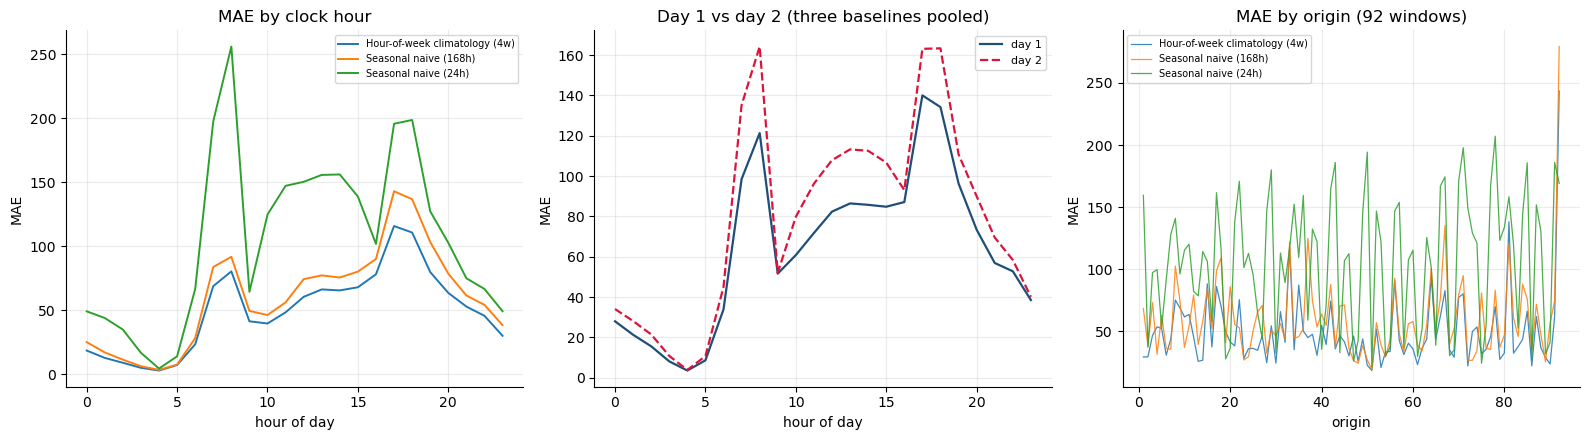

Clock-hour-matched view: day 2 vs day 1 error at the same clock hour
  Hour-of-week climatology (4w)    day1  51.25   day2  48.46     -5.4%
  Seasonal naive (168h)            day1  58.86   day2  61.29     +4.1%
  Seasonal naive (24h)             day1  82.61   day2 129.04    +56.2%

Spread across the 92 origins:
                                 mean    std    min     max   sem
model                                                            
Hour-of-week climatology (4w)   49.86  30.04  18.53  243.48  3.13
Seasonal naive (168h)           60.07  34.34  19.02  279.29  3.58
Seasonal naive (24h)           105.82  52.13  21.62  207.10  5.44


In [23]:
base = pd.concat(predictions, ignore_index=True)
base["clock_hour"] = base["ds"].dt.hour
base["day"] = np.where(base["h"] <= 24, "day 1", "day 2")
base["ae"] = (base["y_true"] - base["y_pred"]).abs()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
base.pivot_table(index="clock_hour", columns="model", values="ae").plot(ax=axes[0], lw=1.4)
axes[0].set(title="MAE by clock hour", xlabel="hour of day", ylabel="MAE"); axes[0].legend(fontsize=7)
base.pivot_table(index="clock_hour", columns="day", values="ae").plot(
    ax=axes[1], lw=1.6, style=["-", "--"], color=["#1f4e79", "crimson"])
axes[1].set(title="Day 1 vs day 2 (three baselines pooled)", xlabel="hour of day", ylabel="MAE")
axes[1].legend(fontsize=8)
per_fold = base.pivot_table(index="fold", columns="model", values="ae")
per_fold.plot(ax=axes[2], lw=0.9, alpha=0.85)
axes[2].set(title=f"MAE by origin ({len(per_fold)} windows)", xlabel="origin", ylabel="MAE"); axes[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

print("Clock-hour-matched view: day 2 vs day 1 error at the same clock hour")
for m, gsub in base.groupby("model"):
    d1 = gsub.loc[gsub["day"] == "day 1", "ae"].mean()
    d2 = gsub.loc[gsub["day"] == "day 2", "ae"].mean()
    print(f"  {m:32s} day1 {d1:6.2f}   day2 {d2:6.2f}   {d2/d1 - 1:+7.1%}")

print()
spread = per_fold.agg(["mean", "std", "min", "max"]).T
spread["sem"] = per_fold.std() / np.sqrt(len(per_fold))
print(f"Spread across the {len(per_fold)} origins:")
print(spread.round(2).to_string())

### What the Baseline Results Show

Weekly alignment matters in this comparison: **weekly naive has MAE 60.075**, versus **105.824 for daily naive**. Averaging four matching weeks is stronger still, at **49.856**.

These results motivate the climatology as the main simple benchmark. Averaging can reduce sensitivity to an individual week's observations, but this experiment does not isolate noise reduction as the cause of its advantage.

The clock-hour plot shows larger absolute errors around busy hours. Its middle panel **pools all three baselines**; the printed model-specific summaries provide the separate day-one/day-two comparisons:

| Procedure | Day 1 MAE | Day 2 MAE | Change |
|:---|---:|---:|---:|
| Daily naive | 82.61 | 129.04 | +56.2% |
| Weekly naive | 58.86 | 61.29 | +4.1% |
| Four-week climatology | 51.25 | 48.46 | −5.4% |

Daily naive repeats the same latest observed day twice, so its second-day source is older relative to the target. The weekly procedures have more similar errors across the two days. These are observed comparisons across matched clock hours, not an isolated estimate of lead-time degradation.

The origin plot also shows substantial variation. The climatology's path-MAE standard deviation is **30.04**, with a maximum of **243.48**. Variation in a single model's errors does not determine uncertainty in a paired model difference; the shared paths will let me examine those differences directly in Section 7.

In [24]:
# Secondary view: identical stored forecasts, re-scored on non-disruption hours only.
print("PRIMARY  (every genuine hour, disruption hours scored as zeros)")
print(leaderboard().round(3).to_string())
print()
n_excl = int(pd.concat(predictions, ignore_index=True).groupby("model")["is_disruption"].sum().iloc[0])
print(f"SECONDARY (same forecasts, re-scored excluding the {n_excl} disruption hours that fall inside a scored window)")
print(leaderboard(normal_ops_only=True).round(3).to_string())

PRIMARY  (every genuine hour, disruption hours scored as zeros)
                                   MAE     RMSE   MASE     n
model                                                       
Hour-of-week climatology (4w)   49.856   86.774  0.839  4416
Seasonal naive (168h)           60.075  106.537  1.011  4416
Seasonal naive (24h)           105.824  166.237  1.782  4416

SECONDARY (same forecasts, re-scored excluding the 36 disruption hours that fall inside a scored window)
                                   MAE     RMSE   MASE     n
model                                                       
Hour-of-week climatology (4w)   48.333   82.447  0.816  4380
Seasonal naive (168h)           58.335  101.678  0.984  4380
Seasonal naive (24h)           105.134  165.379  1.772  4380


### Does Scoring Sandy Determine the Baseline Ranking?

Removing the **36 scored Sandy hours** reduces the population from **4,416 to 4,380** hours. The same forecasts are retained.

Climatology MAE changes from **49.856 to 48.333**, weekly naive from **60.075 to 58.335**, and daily naive from **105.824 to 105.134**. Their ordering is unchanged.

The baseline ranking therefore persists under this particular scoring sensitivity. It does not measure the influence of the 47 earlier disruption-labelled hours on fitting or feature construction. The primary scoring policy remains the one defined before the comparison.

## Section 5: Features That Represent the Observed Patterns

The baselines show the value of weekly alignment. I now ask whether regressors can combine that information with recent history and known calendar fields.

| Block | Columns | Purpose |
|:---|---:|:---|
| Lags 48–72 | 25 | Recent history available across the whole path |
| Lags 167, 168, 169, 336, 504 | 5 | Weekly alignment and neighboring hours |
| Hour-of-week means over 2, 3, and 4 weeks | 3 | Local averages at the matching weekly position |
| Four-week hour-of-week standard deviation | 1 | Variation among matching weekly observations |
| Mean over target-relative lags 48–71 | 1 | A recent-level summary available at every step |
| Calendar fields and cyclical encodings | 9 | Hour, weekday, their joint key, weekend, holiday, and sine/cosine terms |
| Trend | 1 | Time elapsed since the series began |
| **Calendar/history total** | **45** | |

The joint key `hour_of_week=24*weekday+hour` is useful for tree splits. As a numeric column in a linear model it adds no interaction beyond hour and weekday; Ridge will instead one-hot encode its 168 categories.

History features use `y_lagsrc`, while training and scoring use the primary target `y`. Section 7.2 tests the source substitution specifically for Ridge.

The function also supports **five weather columns**, bringing the weather-enabled design to **50**. They remain switched off for the initial model comparison.

In [25]:
# Raw-lag comparator for the Section 7 sensitivity: keep the genuine disruption zeros,
# but apply the SAME past-only DST replacement as y_lagsrc, so the only difference
# between the two sources is the treatment of disruption hours.
Y_RAWLAG = df["y"].copy()
_dst = df["is_nonexistent"]
Y_RAWLAG[_dst] = pd.Series(df["y"].reindex(df.index - pd.Timedelta(hours=WEEK)).to_numpy(),
                           index=df.index)[_dst]
assert Y_RAWLAG.notna().all(), "raw lag source must be complete"
assert (Y_RAWLAG[df["is_disruption"]] == 0).all(), "raw source must keep disruption zeros"
# the isolation claim, asserted directly: identical to y_lagsrc everywhere except
# disruption hours -- including at the DST timestamps, which both replace the same way
_same = ~df["is_disruption"]
assert np.allclose(Y_RAWLAG[_same].to_numpy(), df.loc[_same, "y_lagsrc"].to_numpy()),     "raw and engineered lag sources must differ ONLY on disruption hours"
assert np.allclose(Y_RAWLAG[df["is_nonexistent"]].to_numpy(),
                   df.loc[df["is_nonexistent"], "y_lagsrc"].to_numpy()),     "both lag sources must treat the DST hours identically"

# Weather frames are rebuilt from the UNTOUCHED reindexed observations. Section 1's `df`
# was already filled bidirectionally (interpolate for the continuous columns, ffill+bfill
# for weathersit), so forward-filling *that* frame would be a no-op and would silently
# retain 130 future-borrowing values. Both frames therefore start from `hourly` again.
WEATHER_COLS_X = ["temp", "hum", "windspeed", "weathersit"]
WEATHER_RAW = hourly[WEATHER_COLS_X].reindex(full_index)

# deployable: forward fill only, so no value can come from a later observation
WEATHER_CAUSAL = WEATHER_RAW.ffill()
# oracle-information scenario: non-causal by construction, so bidirectional filling is fine
WEATHER_FORESIGHT = (WEATHER_RAW[["temp", "hum", "windspeed"]].interpolate()
                     .join(WEATHER_RAW["weathersit"].ffill().bfill()))

_absent = WEATHER_RAW["temp"].isna()
assert WEATHER_CAUSAL.notna().all().all(), "causal weather frame must be complete"
assert WEATHER_FORESIGHT.notna().all().all(), "foresight weather frame must be complete"
print(f"Weather frames rebuilt from raw observations: {int(_absent.sum())} absent hours")
print(f"  causal vs foresight differ at {int((WEATHER_CAUSAL['temp'] - WEATHER_FORESIGHT['temp']).abs().gt(1e-12).sum())} hours"
      f"  (these are the future-borrowing values the deployable mode must not use)")

# ---- Held-back calendar covariates: mechanism frozen here, before evaluation ----
# The features need `holiday`/`workingday` for the held-back period too. These are
# public calendar facts knowable years in advance, so they are PREDECLARED here rather
# than read from the held-back table at evaluation time.
EVAL_HOLIDAYS = pd.to_datetime(["2012-11-12",   # Veterans Day (observed)
                                "2012-11-22",   # Thanksgiving
                                "2012-12-25"])  # Christmas Day
def eval_calendar(index):
    # holiday / workingday for arbitrary dates, from the predeclared calendar only
    d = index.normalize()
    holiday = d.isin(EVAL_HOLIDAYS).astype(int)
    workingday = ((index.dayofweek < 5) & ~d.isin(EVAL_HOLIDAYS)).astype(int)
    return pd.DataFrame({"holiday": holiday, "workingday": workingday}, index=index)

# Sanity check the RULE, not the holiday list: on development days that are not
# holidays, `workingday` must be exactly "Monday-Friday". EVAL_HOLIDAYS covers only
# the held-back window, so comparing it against development holidays proves nothing.
_nonhol = (df["holiday"] == 0).to_numpy()
_rule = np.asarray(df.index.dayofweek < 5, dtype=int)[_nonhol]
assert (_rule == df.loc[_nonhol, "workingday"].to_numpy()).all(),     "workingday must equal Mon-Fri on non-holiday days"
print("Calendar rule verified on development data: workingday == Mon-Fri on every non-holiday hour.")
print(f"Held-back holidays predeclared (public calendar, no held-back data read): "
      f"{[str(d.date()) for d in EVAL_HOLIDAYS]}")
_ec = eval_calendar(pd.date_range(EVAL_START, '2012-12-31 23:00', freq='h'))
print(f"  applied to the held-back window: {int(_ec['holiday'].sum())} holiday hours, "
      f"{int(_ec['workingday'].sum())} working hours of {len(_ec)}")

SHORT_LAGS  = list(range(HORIZON, HORIZON + 25))              # 48..72
WEEKLY_LAGS = [WEEK - 1, WEEK, WEEK + 1, 2 * WEEK, 3 * WEEK]  # 167,168,169,336,504
ALL_LAGS    = SHORT_LAGS + WEEKLY_LAGS

def build_features(index, weather_mode="none", lag_source="engineered"):
    """Feature matrix for an arbitrary hourly index.

    weather_mode : "none" | "lagged" (observed >= HORIZON h earlier) | "foresight" (actual
                   weather at the target hour -- NOT deployable; an oracle-information
                   scenario used only in Section 8)
    lag_source   : "engineered" -> y_lagsrc (disruption AND DST hours replaced, Section 1)
                   "raw"        -> disruption zeros kept, DST hours replaced identically, so
                                   the two differ ONLY in how disruption hours are treated
    """
    if weather_mode not in {"none", "lagged", "foresight"}:
        raise ValueError(f"weather_mode must be none/lagged/foresight, got {weather_mode!r}")
    if lag_source not in {"engineered", "raw"}:
        raise ValueError(f"lag_source must be engineered/raw, got {lag_source!r}")
    src = df["y_lagsrc"] if lag_source == "engineered" else Y_RAWLAG
    X = pd.DataFrame(index=index)

    for L in ALL_LAGS:
        X[f"lag_{L}"] = src.reindex(index - pd.Timedelta(hours=L)).to_numpy()

    # During the first 504 training hours some donor windows are entirely before the
    # series starts, so nanmean/nanstd see an all-NaN slice and warn. Those rows are
    # dropped by make_xy before any model is fitted, so the warning is expected and is
    # suppressed only around these three calculations -- not globally.
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", message="Mean of empty slice", category=RuntimeWarning)
        warnings.filterwarnings("ignore", message="Degrees of freedom <= 0", category=RuntimeWarning)
        for k in [2, 3, 4]:                                   # same hour-of-week, k weeks back
            stack = np.vstack([src.reindex(index - pd.Timedelta(hours=WEEK * j)).to_numpy()
                               for j in range(1, k + 1)])
            X[f"how_mean_{k}w"] = np.nanmean(stack, axis=0)
        stack4 = np.vstack([src.reindex(index - pd.Timedelta(hours=WEEK * j)).to_numpy()
                            for j in range(1, 5)])
        X["how_std_4w"] = np.nanstd(stack4, axis=0)
        X["recent_day_mean"] = np.nanmean(                    # last observable day, no leakage
            np.vstack([src.reindex(index - pd.Timedelta(hours=L)).to_numpy()
                       for L in range(HORIZON, HORIZON + 24)]), axis=0)

    hour, weekday = index.hour.to_numpy(), index.dayofweek.to_numpy()
    X["hour"] = hour
    X["weekday"] = weekday
    X["hour_of_week"] = weekday * 24 + hour                   # the interaction, as one integer
    X["is_weekend"] = (weekday >= 5).astype(int)
    X["hour_sin"] = np.sin(2 * np.pi * hour / 24)
    X["hour_cos"] = np.cos(2 * np.pi * hour / 24)
    X["weekday_sin"] = np.sin(2 * np.pi * weekday / 7)
    X["weekday_cos"] = np.cos(2 * np.pi * weekday / 7)
    X["trend"] = (index - df.index.min()).total_seconds().to_numpy() / 3600.0 / WEEK

    # Calendar covariates. `df` stops at the development boundary, so a timestamp beyond
    # it would silently yield NaN. Anything outside `df.index` is filled from the
    # PREDECLARED calendar (defined below), which reads only the DatetimeIndex.
    hol = df["holiday"].reindex(index)
    if hol.isna().any():
        hol = hol.fillna(pd.Series(eval_calendar(index)["holiday"].to_numpy(), index=index))
    X["holiday"] = hol.to_numpy()
    assert not np.isnan(X["holiday"]).any(), "holiday must be defined at every forecast hour"

    if weather_mode != "none":
        # "lagged" is deployable and reads the causally-filled frame; "foresight" is an
        # oracle-information scenario and may use the bidirectionally-filled one.
        shift = HORIZON if weather_mode == "lagged" else 0
        wframe = WEATHER_CAUSAL if weather_mode == "lagged" else WEATHER_FORESIGHT
        wsrc = index - pd.Timedelta(hours=shift)
        for c in ["temp", "hum", "windspeed", "weathersit"]:
            X[f"w_{c}"] = wframe[c].reindex(wsrc).to_numpy()
        X["w_temp_sq"] = X["w_temp"] ** 2                     # the inverted U (Decision 7)
    return X

assert min(ALL_LAGS) >= HORIZON, "every lag must be at least the forecast horizon"

_probe = build_features(pd.date_range("2012-09-01", periods=HORIZON, freq="h"))
print(f"Feature matrix: {_probe.shape[1]} columns")
print(f"  lags: {len(ALL_LAGS)} ({min(SHORT_LAGS)}..{max(SHORT_LAGS)}, then {WEEKLY_LAGS})")
print(f"  smallest lag {min(ALL_LAGS)} >= horizon {HORIZON}: asserted")

Weather frames rebuilt from raw observations: 161 absent hours
  causal vs foresight differ at 130 hours  (these are the future-borrowing values the deployable mode must not use)
Calendar rule verified on development data: workingday == Mon-Fri on every non-holiday hour.
Held-back holidays predeclared (public calendar, no held-back data read): ['2012-11-12', '2012-11-22', '2012-12-25']
  applied to the held-back window: 72 holiday hours, 960 working hours of 1464
Feature matrix: 45 columns
  lags: 30 (48..72, then [167, 168, 169, 336, 504])
  smallest lag 48 >= horizon 48: asserted


### What the Feature Checks Establish

The probe confirms **45 calendar/history columns**, including **30 lags**, with minimum lag **48**. Its timestamps satisfy the shared forecast-path policy.

Weather is rebuilt from the unfilled source observations. **Forward filling** provides the deployable source, while interpolation and backward filling are reserved for the oracle-information frame. The temperature columns differ at **130 positions**: applying forward fill to an already interpolated frame would not undo those future-borrowing values.

The held-back calendar is constructed from a fixed holiday list and timestamp rules, without reading held-back rental outcomes. Its **72 holiday hours** and **960 working hours** describe calendar covariates, not target statistics.

The later matrix checks test completeness across origins. Completeness and information availability are distinct: neither a finite value nor a minimum-lag assertion alone audits the availability of every upstream preprocessing decision. The disruption labels remain retrospective, as disclosed in Section 1.

### Early Tuning Followed by Frozen Hyperparameters

Each fitted family is tuned on **22 early origins**, using original-scale MAE. The subsequent **92 origins** compare the selected configurations without repeating hyperparameter searches at each origin.

The tuning paths end on **April 26, 2012**; the selection paths begin on **April 30**. Training histories expand within each stage. Search budgets differ by family and are reported with the results, so common origins and metrics do not imply equally exhaustive searches.

This separation prevents the later selection errors from choosing the grid hyperparameters. It does not remove the development-wide EDA or other analyst choices that shaped the candidate procedures.

The next cell defines the search and verifies feature completeness across both stages, both lag sources, and all three supported weather modes.

In [26]:
TUNE_START = pd.Timestamp("2012-02-01")
tune_origins = make_origins(cv_folds["val_start"].min() - pd.Timedelta(hours=1),
                            first_day=TUNE_START, spacing=HORIZON * 2)
tune_folds = pd.DataFrame({"fold": range(1, len(tune_origins) + 1), "val_start": tune_origins})
tune_folds["val_end"] = tune_folds["val_start"] + pd.Timedelta(hours=HORIZON - 1)

print(f"Tuning origins:    {len(tune_folds):3d}   {tune_folds['val_start'].min()} -> {tune_folds['val_end'].max()}")
print(f"Selection origins: {len(cv_folds):3d}   {cv_folds['val_start'].min()} -> {cv_folds['val_end'].max()}")
print(f"Held back:              {EVAL_START} onward -- not retained or analyzed")

assert tune_folds["val_end"].max() < cv_folds["val_start"].min(), "tuning must end before selection begins"
assert cv_folds["val_end"].max() < EVAL_START, "selection must end before the held-back block"

def tune(candidates, make_fn, label):
    """Score every candidate on the tuning origins; return the best by MAE."""
    rows = []
    for params in candidates:
        out = run_model(make_fn(params), f"__tune__{label}", folds=tune_folds, verbose=False, store=False)
        rows.append({**params, "MAE": (out["y_true"] - out["y_pred"]).abs().mean()})
    tbl = pd.DataFrame(rows).sort_values("MAE").reset_index(drop=True)
    print(f"--- {label}: {len(candidates)} candidates x {len(tune_folds)} tuning origins")
    print(tbl.head(5).round(4).to_string(index=False))
    best = {k: v for k, v in tbl.iloc[0].items() if k != "MAE"}
    print(f"    selected: {best}")
    return best, tbl

# Feature completeness across EVERY fold that will be forecast, not just one probe.
_bad = 0
for _f in pd.concat([tune_folds[["val_start", "val_end"]], cv_folds[["val_start", "val_end"]]]).itertuples():
    _idx = pd.date_range(_f.val_start, _f.val_end, freq="h")
    for _src in ["engineered", "raw"]:
        for _wm in ["none", "lagged", "foresight"]:
            _bad += int(build_features(_idx, weather_mode=_wm, lag_source=_src).isna().sum().sum())
print(f"NaN feature values across all {len(tune_folds)} tuning + {len(cv_folds)} selection folds, "
      f"both lag sources x all three weather modes: {_bad}")
assert _bad == 0, "forecast features must be complete at every origin"

print("\nTuning protocol ready.")

Tuning origins:     22   2012-02-01 00:00:00 -> 2012-04-26 23:00:00
Selection origins:  92   2012-04-30 00:00:00 -> 2012-10-30 23:00:00
Held back:              2012-11-01 00:00:00 onward -- not retained or analyzed


NaN feature values across all 22 tuning + 92 selection folds, both lag sources x all three weather modes: 0

Tuning protocol ready.


The saved checks confirm **22 tuning origins**, **92 later selection origins**, and **zero missing forecast-feature values** across the tested combinations. The stage boundaries precede the November final block.

These checks establish the intended split arithmetic and matrix completeness. Training rows without all required features are dropped by `make_xy`; forecast rows must be complete. The weather-source timing check in Section 8 separately verifies that deployable weather timestamps precede each origin.

## Section 6: Comparing Fitted Forecasting Procedures

I compare Ridge, XGBoost, LightGBM, Prophet, and SARIMA with the three baselines. Nonseasonal smoothing methods are outside this bounded roster because they do not explicitly represent the pronounced daily cycle. This is a scope choice, not a claim that they must perform poorly.

The initial comparison uses **calendar and rental history without weather**. All procedures forecast the same target paths, although their training representations and history lengths differ.

### Target Scale and Fitting Loss

The feature-based regressors can fit either `y` or `log1p(y)`. Their predictions are returned to the rental scale and clipped at zero before evaluation.

At the population level, squared-error fitting on the log scale targets $E[\log(1+Y)\mid X]$. Applying `expm1` gives a geometric-mean-type summary, generally different from the original-scale mean and not automatically its median. Absolute loss targets a conditional median; a strictly increasing transformation maps medians between scales.

These population results do not determine the accuracy of finite, regularized fits. Raw-scale absolute loss aligns directly with MAE, but a squared-error model can still forecast better after estimation and tuning. Both boosting grids therefore offer squared- and absolute-error objectives on both target scales.

Every candidate is selected using **MAE after returning predictions to the original scale**. The saved tuning tables reveal which choices actually helped.

In [27]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from xgboost import XGBRegressor
import lightgbm as lgb

def make_xy(train, val_index, weather_mode="none", lag_source="engineered"):
    """Training matrix (burn-in and unscoreable rows dropped) and the forecast matrix."""
    X_tr = build_features(train.index, weather_mode, lag_source)
    y_tr = df["y"].reindex(train.index)
    keep = X_tr.notna().all(axis=1) & y_tr.notna()
    X_va = build_features(val_index, weather_mode, lag_source)
    assert X_va.notna().all().all(), "forecast features must be complete"
    return X_tr[keep], y_tr[keep], X_va

def _fit_predict(model, X_tr, y_tr, X_va, log_target):
    """Fit and forecast, optionally on the log scale. Predictions clipped at zero."""
    yt = np.log1p(y_tr) if log_target else y_tr
    model.fit(X_tr, yt)
    p = model.predict(X_va)
    if log_target:
        p = np.expm1(p)
    return np.clip(p, 0, None)

print("Model utilities ready.")

Model utilities ready.


### 6.1 Ridge Regression: A Regularized Linear Reference

Ridge fits a linear combination of predictors while penalizing large coefficients:

$$
\min_{\beta,b}\sum_j\bigl(y_j-b-X_j^\top\beta\bigr)^2
+\alpha\sum_k\beta_k^2.
$$

The penalty can stabilize a design with correlated lags and related calendar inputs. It does not remove coefficients in the way an L1 coefficient penalty can.

I one-hot encode `hour_of_week` into **168 categories**, allowing Ridge to represent a distinct baseline for each weekday–hour combination. The other columns are standardized within each training fit. This gives the linear reference the interaction identified in Section 2 rather than leaving it with only separate additive hour and weekday terms.

The grid compares three penalty strengths on each of the two target scales.

In [28]:
HOW_COL = "hour_of_week"

def ridge_pipeline(alpha):
    """168-level one-hot on hour_of_week; everything else standardised."""
    return Pipeline([
        ("prep", ColumnTransformer(
            [("how_onehot", OneHotEncoder(categories=[np.arange(168)], handle_unknown="ignore",
                                          sparse_output=False), [HOW_COL])],
            remainder=StandardScaler())),
        ("ridge", Ridge(alpha=alpha)),
    ])

# Verify the encoder does what the text claims, before any tuning runs.
_probe_idx = pd.date_range("2012-09-01", periods=HORIZON, freq="h")
_Xp = build_features(_probe_idx)
_prep = ridge_pipeline(1.0).named_steps["prep"].fit(_Xp)
_n_out = _prep.transform(_Xp).shape[1]
_ohe = _prep.named_transformers_["how_onehot"]
print(f"hour_of_week encoding: {len(_ohe.categories_[0])} one-hot levels")
print(f"design matrix widens from {_Xp.shape[1]} raw columns to {_n_out} after encoding")
assert len(_ohe.categories_[0]) == 168, "hour_of_week must be encoded at 168 levels for Ridge"
assert _n_out == _Xp.shape[1] - 1 + 168

def make_ridge(params):
    def f(train, val_index):
        X_tr, y_tr, X_va = make_xy(train, val_index)
        return _fit_predict(ridge_pipeline(params["alpha"]), X_tr, y_tr, X_va, params["log_target"])
    return f

ridge_grid = [{"alpha": a, "log_target": lt} for a in [1.0, 10.0, 100.0] for lt in [False, True]]
ridge_best, ridge_tbl = tune(ridge_grid, make_ridge, "Ridge")

hour_of_week encoding: 168 one-hot levels
design matrix widens from 45 raw columns to 212 after encoding


--- Ridge: 6 candidates x 22 tuning origins
 alpha  log_target     MAE
   1.0       False 49.8561
  10.0       False 50.0202
 100.0       False 50.5316
   1.0        True 69.2988
  10.0        True 78.4588
    selected: {'alpha': 1.0, 'log_target': False}


In [29]:
_ = run_model(make_ridge(ridge_best), "Ridge")

Ridge                              MAE  51.97   RMSE  85.74   MASE 0.875   [  9.2s, 92 origins]


The encoding check expands **45 raw columns to 212 design columns**: 168 hour-of-week indicators replace one numeric column.

Among six tuning candidates, **`alpha=1` on the raw target** has the lowest tuning MAE, **49.8561**. The best displayed log-target candidate is worse, so the descriptive case for multiplicative scaling does not translate into a tuning benefit for this Ridge design.

With those choices frozen, selection MAE is **51.965**, compared with **49.856** for the climatology on the same selection paths. Ridge therefore does not improve the primary metric over that benchmark here. Its lower pooled RMSE, **85.739 versus 86.774**, will be revisited as a separate metric comparison.

### 6.2 Gradient Boosting: XGBoost and LightGBM

Boosting builds a prediction through successive trees, each helping improve the chosen fitting objective. Tree partitions can represent nonlinear responses and interactions without specifying every product term in advance.

The implementations provide related but distinct candidates. In these configurations, XGBoost uses its default depth-wise growth with a depth limit; LightGBM grows leaves according to loss improvement, with a leaf-count limit. The [XGBoost parameter documentation](https://xgboost.readthedocs.io/en/release_3.0.0/parameter.html) and [LightGBM growth guide](https://lightgbm.readthedocs.io/en/stable/Parameters-Tuning.html) describe these controls. Their results compare those specified procedures, not the libraries' full capabilities.

I vary tree size, target scale, and squared- versus absolute-error loss on the early tuning paths. The number of trees, learning rate, and sampling settings remain fixed. Agreement between the libraries would be useful descriptive evidence, but not independent confirmation of a general boosting advantage.

In [30]:
def make_xgb(params):
    def f(train, val_index):
        X_tr, y_tr, X_va = make_xy(train, val_index)
        m = XGBRegressor(objective=params["objective"], random_state=42, n_jobs=4,
                         n_estimators=400, learning_rate=0.05, max_depth=params["max_depth"],
                         subsample=0.8, colsample_bytree=0.8)
        return _fit_predict(m, X_tr, y_tr, X_va, params["log_target"])
    return f

xgb_grid = [{"objective": o, "max_depth": d, "log_target": lt}
            for o in ["reg:squarederror", "reg:absoluteerror"] for d in [4, 6] for lt in [False, True]]
xgb_best, xgb_tbl = tune(xgb_grid, make_xgb, "XGBoost")

--- XGBoost: 8 candidates x 22 tuning origins
        objective  max_depth  log_target     MAE
reg:absoluteerror          6       False 50.4209
reg:absoluteerror          4       False 50.6764
 reg:squarederror          6       False 51.6693
reg:absoluteerror          4        True 52.5749
reg:absoluteerror          6        True 53.1044
    selected: {'objective': 'reg:absoluteerror', 'max_depth': 6, 'log_target': False}


In [31]:
_ = run_model(make_xgb(xgb_best), "XGBoost")

XGBoost                            MAE  50.26   RMSE  87.51   MASE 0.847   [209.1s, 92 origins]


XGBoost selects **absolute-error loss, depth 6, and the raw target**, with tuning MAE **50.4209**. The best displayed squared-error configuration has tuning MAE **51.6693**. This supports the selected combination on these tuning paths; it does not isolate one universal effect of changing the loss.

The frozen procedure achieves selection MAE **50.255**, close to the climatology's **49.856**. Nonlinear flexibility has not yet produced an observed improvement over that benchmark.

In [32]:
def make_lgb(params):
    def f(train, val_index):
        X_tr, y_tr, X_va = make_xy(train, val_index)
        m = lgb.LGBMRegressor(objective=params["objective"], random_state=42, n_jobs=4, verbose=-1,
                              n_estimators=400, learning_rate=0.05, num_leaves=params["num_leaves"],
                              subsample=0.8, subsample_freq=1, colsample_bytree=0.8)
        return _fit_predict(m, X_tr, y_tr, X_va, params["log_target"])
    return f

lgb_grid = [{"objective": o, "num_leaves": nl, "log_target": lt}
            for o in ["regression", "regression_l1"] for nl in [31, 63] for lt in [False, True]]
lgb_best, lgb_tbl = tune(lgb_grid, make_lgb, "LightGBM")

--- LightGBM: 8 candidates x 22 tuning origins
    objective  num_leaves  log_target     MAE
regression_l1          63       False 51.0048
regression_l1          31       False 51.0531
regression_l1          63        True 51.7380
regression_l1          31        True 52.2034
   regression          31       False 54.3080
    selected: {'objective': 'regression_l1', 'num_leaves': 63, 'log_target': False}


In [33]:
_ = run_model(make_lgb(lgb_best), "LightGBM")
print()
print(leaderboard().round(3).to_string())

LightGBM                           MAE  49.02   RMSE  86.23   MASE 0.826   [248.0s, 92 origins]

                                   MAE     RMSE   MASE     n
model                                                       
LightGBM                        49.025   86.227  0.826  4416
Hour-of-week climatology (4w)   49.856   86.774  0.839  4416
XGBoost                         50.255   87.514  0.847  4416
Ridge                           51.965   85.739  0.875  4416
Seasonal naive (168h)           60.075  106.537  1.011  4416
Seasonal naive (24h)           105.824  166.237  1.782  4416


LightGBM also selects the **raw target and absolute-error objective**, with **63 leaves**. Tuning MAE is **51.0048**; selection MAE is **49.025**.

It now leads the observed no-weather MAE ranking, but by only **0.831 rentals** over the climatology. XGBoost had the lower tuning MAE and LightGBM has the lower selection MAE, illustrating why the tuning table alone is not the final comparison.

The small selection gap motivates examining paired path losses rather than interpreting first place as established superiority. Prophet and SARIMA complete the roster before that assessment.

### 6.3 Prophet: Trend and Seasonal Components

Prophet represents the series through a changing trend, seasonal functions, and optional holiday effects. I compare additive seasonality with a multiplicative form in which seasonal amplitude scales with the estimated trend.

Daily and weekly seasonalities are enabled. Holiday inclusion is a tuning option, giving Prophet access to the same kind of known calendar information offered to the regressors. **Annual seasonality is fixed off** to limit complexity with less than two annual cycles available; its exclusion is not the result of a tested annual-seasonality comparison.

Prophet fits the primary target, including disruption zeros, while excluding the two nonexistent DST positions. Eligible training histories still differ across families: regressors need lag warm-up, and SARIMA below uses a shorter window.

For point forecasts, this experiment uses Prophet's default MAP fitting. Its later simulated intervals should not be read as full posterior parameter uncertainty.

In [34]:
import logging
from prophet import Prophet
from cmdstanpy.utils import get_logger as _get_cmdstan_logger

# Initialise CmdStanPy first: its first logger call can otherwise reset the level.
_get_cmdstan_logger().setLevel(logging.WARNING)
logging.getLogger("prophet").setLevel(logging.WARNING)

# Prophet's own holiday format, built from the calendar-corrected column (Section 1).
# Built from the daily table rather than a forward-filled hourly column, which had
# injected two spurious holiday dates.
_hol_dates = pd.DatetimeIndex(sorted({d for d in df.index[df["holiday"] == 1].normalize()}))
PROPHET_HOLIDAYS = pd.DataFrame({"holiday": "us_holiday", "ds": _hol_dates,
                                 "lower_window": 0, "upper_window": 0})
print(f"Holidays passed to Prophet: {len(PROPHET_HOLIDAYS)} dates "
      f"({PROPHET_HOLIDAYS['ds'].min().date()} .. {PROPHET_HOLIDAYS['ds'].max().date()})")

def make_prophet(params):
    def f(train, val_index):
        # every genuine hour, matching the primary target. Only the nonexistent DST
        # timestamps are withheld -- there is no such clock hour to fit.
        pdf = train.loc[train["y"].notna(), ["y"]].reset_index()
        pdf.columns = ["ds", "y"]
        m = Prophet(seasonality_mode=params["seasonality_mode"],
                    changepoint_prior_scale=0.05,
                    yearly_seasonality=params["yearly_seasonality"],
                    weekly_seasonality=True, daily_seasonality=True,
                    holidays=PROPHET_HOLIDAYS if params["use_holidays"] else None)
        m.fit(pdf)
        return np.clip(m.predict(pd.DataFrame({"ds": val_index}))["yhat"].to_numpy(), 0, None)
    return f

YEARLY_SEASONALITY = False   # fixed: < 2 annual cycles available (see above), not searched
prophet_grid = [{"seasonality_mode": sm, "yearly_seasonality": YEARLY_SEASONALITY, "use_holidays": uh}
                for sm in ["additive", "multiplicative"] for uh in [False, True]]
prophet_best, prophet_tbl = tune(prophet_grid, make_prophet, "Prophet")

Holidays passed to Prophet: 18 dates (2011-01-17 .. 2012-10-08)


--- Prophet: 4 candidates x 22 tuning origins
seasonality_mode  yearly_seasonality  use_holidays     MAE
  multiplicative               False         False 79.2938
  multiplicative               False          True 79.3959
        additive               False         False 89.2930
        additive               False          True 89.3022
    selected: {'seasonality_mode': 'multiplicative', 'yearly_seasonality': False, 'use_holidays': False}


In [35]:
_ = run_model(make_prophet(prophet_best), "Prophet")

Prophet                            MAE 100.45   RMSE 138.19   MASE 1.690   [171.4s, 92 origins]


The four-candidate search selects **multiplicative seasonality without holidays**, with tuning MAE **79.2938**. The additive/no-holiday candidate scores **89.2930**. Multiplicative seasonality helps within this tested setup, while adding holidays does not improve its tuning score.

The selected Prophet procedure has selection MAE **100.451**, substantially above the climatology and feature-based regressors. The result concerns this seasonal specification and tuning budget; it does not establish why Prophet misses or that holidays are generally uninformative.

### 6.4 SARIMA: Seasonal Differences and Error Dynamics

SARIMA models dependence through autoregressive terms, moving-average terms, and their seasonal counterparts. **AR terms** relate the current differenced series to earlier values; **MA terms** use earlier innovations, rather than averaging observed rental counts.

The fixed seasonal specification is `(P,D,Q,s)=(1,1,1,24)`. The `D=1` difference subtracts the value 24 positions earlier, while seasonal AR and MA terms represent dependence at that seasonal lag. The grid compares nonseasonal orders `(p,q)=(1,1),(2,1),(2,2)` with `d=0`.

I fit a **trailing six-week window** to bound computation and offer a recent-history representation. The window is fixed here, not demonstrated optimal by the earlier level comparison. The state-space implementation handles the DST target NaNs as missing observations.

The next cells report both forecasting error and optimizer convergence. A convergence flag is a useful diagnostic, not a certificate of a global optimum.

In [36]:
import statsmodels.api as sm
SARIMA_WINDOW = 24 * 7 * 6          # trailing six weeks
# One record per fit: stage, candidate order, origin, and whether MLE converged.
sarima_fits = []

def make_sarima(params, stage="selection"):
    def f(train, val_index):
        y_tr = train["y"].to_numpy()[-SARIMA_WINDOW:]   # NaN at DST hours: SARIMAX treats
        fitted = sm.tsa.statespace.SARIMAX(             # them as missing in the Kalman filter
            y_tr, order=(params["p"], 0, params["q"]), seasonal_order=(1, 1, 1, SEASON),
            enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
        sarima_fits.append({"stage": stage, "p": params["p"], "q": params["q"],
                            "origin": val_index[0],
                            "converged": bool(fitted.mle_retvals.get("converged", False))})
        return np.clip(np.asarray(fitted.get_forecast(steps=len(val_index)).predicted_mean), 0, None)
    return f

sarima_grid = [{"p": p, "q": q} for p, q in [(1, 1), (2, 1), (2, 2)]]
sarima_best, sarima_tbl = tune(sarima_grid, lambda pr: make_sarima(pr, "tuning"), "SARIMA")

fits = pd.DataFrame(sarima_fits)
print("\nConvergence during tuning, by candidate order:")
print(fits[fits["stage"] == "tuning"].groupby(["p", "q"])["converged"]
      .agg(fits="size", converged="sum").assign(failed=lambda d: d["fits"] - d["converged"]).to_string())

/opt/miniconda3/envs/handson-env/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/opt/miniconda3/envs/handson-env/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/opt/miniconda3/envs/handson-env/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/opt/miniconda3/envs/handson-env/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/opt/miniconda3/envs/handson-env/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/opt/miniconda3/envs/handson-env/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


... (3 outputs left out)

/opt/miniconda3/envs/handson-env/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/opt/miniconda3/envs/handson-env/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/opt/miniconda3/envs/handson-env/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


--- SARIMA: 3 candidates x 22 tuning origins
 p  q     MAE
 2  1 71.5020
 1  1 71.6690
 2  2 73.2474
    selected: {'p': 2.0, 'q': 1.0}

Convergence during tuning, by candidate order:
     fits  converged  failed
p q                         
1 1    22         22       0
2 1    22         22       0
  2    22         10      12


In [37]:
_ = run_model(make_sarima(sarima_best), "SARIMA")

fits = pd.DataFrame(sarima_fits)
sel = fits[fits["stage"] == "selection"]
print(f"Selected order (p,q) = ({sarima_best['p']:.0f},{sarima_best['q']:.0f}) on "
      f"{len(sel)} selection origins: {int(sel['converged'].sum())} converged, "
      f"{int((~sel['converged']).sum())} failed")
if (~sel["converged"]).any():
    bad = sel.loc[~sel["converged"], "origin"]
    print(f"  non-converged origins: {[str(d.date()) for d in bad[:8]]}"
          f"{' ...' if len(bad) > 8 else ''}")
    print("  These forecasts are RETAINED and scored. Dropping them would select the origins")
    print("  on which SARIMA happened to behave, which is not a fair comparison -- but they")
    print("  are numerically unreliable and the SARIMA row should be read with that in view.")
print()
print(leaderboard().round(3).to_string())

SARIMA                             MAE  85.61   RMSE 124.53   MASE 1.440   [744.7s, 92 origins]
Selected order (p,q) = (2,1) on 92 selection origins: 92 converged, 0 failed

                                   MAE     RMSE   MASE     n
model                                                       
LightGBM                        49.025   86.227  0.826  4416
Hour-of-week climatology (4w)   49.856   86.774  0.839  4416
XGBoost                         50.255   87.514  0.847  4416
Ridge                           51.965   85.739  0.875  4416
Seasonal naive (168h)           60.075  106.537  1.011  4416
SARIMA                          85.606  124.529  1.440  4416
Prophet                        100.451  138.193  1.690  4416
Seasonal naive (24h)           105.824  166.237  1.782  4416


The selected specification is **SARIMA(2,0,1)(1,1,1)[24]**, with tuning MAE **71.5020**. Its fits converge at all **22 tuning origins** and all **92 selection origins**. Selection MAE is **85.606**, above the weekly naive and climatology references.

The unselected `(p,q)=(2,2)` candidate has **12 nonconverged fits out of 22**. Those fits are reported rather than silently discarded. Their presence cautions against treating that candidate's aggregate score as a precisely optimized result.

**Numerical replay record.** This unselected candidate scored 72.8447 in the earlier saved run and **73.2474 in the verified replay**, with 12 nonconvergences in both. Both runs selected `(2,1)`. The cause of the numerical difference was not isolated, and no retuning followed it.

The roster is now complete. LightGBM has the lowest no-weather MAE, while the climatology remains close enough to require a paired assessment.

## Section 7: How Much Evidence Supports the No-Weather Ranking?

The eight-model leaderboard orders observed errors. I next compare **mean absolute loss per forecast path**, giving 92 paired occasions for each model pair.

For models $A$ and $B$, let

$$
d_i=\operatorname{MAE}_{i,A}-\operatorname{MAE}_{i,B}.
$$

A negative mean difference favors $A$. Pairing compares procedures under the same target conditions, although consecutive path losses can remain dependent.

I report paired t-tests under an IID reference and a **lag-4 Bartlett HAC sensitivity**, which estimates the variance of the mean difference allowing specified serial dependence. Holm adjustment covers **all 28 pairs** among eight models. It controls multiplicity within that family under valid underlying tests; it does not account for the full adaptive research history.

The [Diebold–Mariano framework](https://users.ssc.wisc.edu/~behansen/718/DieboldMariano1995.pdf) motivates evaluating mean loss differences with their long-run variance. Here the sequence is **origin-level path losses**: four origin lags are not four hourly lags.

This section concerns the **no-weather candidates**. Section 8.4 recomputes the comparison for the carried weather-enabled pipeline. Both remain developmental because EDA and family selection used these periods.

In [38]:
P = pd.concat(predictions, ignore_index=True)
P["ae"] = (P["y_true"] - P["y_pred"]).abs()
P["se"] = (P["y_true"] - P["y_pred"]) ** 2

# 92 origin-level mean absolute errors per model: the paired units
origin_mae = P.pivot_table(index="fold", columns="model", values="ae")
order = origin_mae.mean().sort_values().index.tolist()
origin_mae = origin_mae[order]

summary = pd.DataFrame({
    "MAE": origin_mae.mean().round(3),
    "sd_across_origins": origin_mae.std().round(2),
    "sem_unpaired": (origin_mae.std() / np.sqrt(len(origin_mae))).round(3),
})
print(f"Across {len(origin_mae)} origins:")
print(summary.to_string())

Across 92 origins:
                                   MAE  sd_across_origins  sem_unpaired
model                                                                  
LightGBM                        49.025              30.91         3.223
Hour-of-week climatology (4w)   49.856              30.04         3.132
XGBoost                         50.255              30.06         3.134
Ridge                           51.965              30.16         3.145
Seasonal naive (168h)           60.075              34.34         3.580
SARIMA                          85.606              31.28         3.262
Prophet                        100.451              24.79         2.585
Seasonal naive (24h)           105.824              52.13         5.435


In [39]:
from scipy import stats
from itertools import combinations

# Holm is applied across ALL pairs among the eight predeclared models, not only the
# seven involving the observed leader. Choosing the reference from the results and
# then correcting within that family would leave the selection bias in place.
pairs = []
for a, b in combinations(order, 2):
    d = (origin_mae[a] - origin_mae[b]).to_numpy()
    t, p = stats.ttest_rel(origin_mae[a], origin_mae[b])
    pairs.append({"model_a": a, "model_b": b, "diff_a_minus_b": d.mean(),
                  "sem_paired": d.std(ddof=1) / np.sqrt(len(d)), "p_raw": p})
pairs = pd.DataFrame(pairs)

def holm(pvals):
    k = len(pvals); o = np.argsort(pvals); adj = np.empty(k); run = 0.0
    for rank, idx in enumerate(o):
        run = max(run, (k - rank) * pvals[idx]); adj[idx] = min(1.0, run)
    return adj

pairs["p_holm"] = holm(pairs["p_raw"].to_numpy())

def fmt_p(v):
    return "  <0.0001" if 0 <= v < 1e-4 else f"{v:9.4f}"
print(f"Holm correction applied across all {len(pairs)} pairwise comparisons "
      f"among {len(order)} predeclared models.")

ref = order[0]                      # the observed leader, shown for readability only
sub = pairs[(pairs.model_a == ref) | (pairs.model_b == ref)].copy()
sub["challenger"] = np.where(sub.model_a == ref, sub.model_b, sub.model_a)
sub["diff_vs_leader"] = np.where(sub.model_a == ref, -sub.diff_a_minus_b, sub.diff_a_minus_b)
sub["origins_better_than_leader"] = [
    float(((origin_mae[c] - origin_mae[ref]) < 0).mean()) for c in sub["challenger"]]
print()
print(f"Comparisons involving the observed leader ({ref}); positive diff = worse than leader")
print(f"p_holm reflects the full {len(pairs)}-comparison family.\n")
print(sub[["challenger", "diff_vs_leader", "sem_paired", "p_raw", "p_holm",
           "origins_better_than_leader"]]
      .sort_values("diff_vs_leader")
      .to_string(index=False, float_format=fmt_p))

Holm correction applied across all 28 pairwise comparisons among 8 predeclared models.

Comparisons involving the observed leader (LightGBM); positive diff = worse than leader
p_holm reflects the full 28-comparison family.

                   challenger  diff_vs_leader  sem_paired     p_raw    p_holm  origins_better_than_leader
Hour-of-week climatology (4w)          0.8309      1.1653    0.4776    0.9553                      0.5000
                      XGBoost          1.2307      0.5734    0.0345    0.1726                      0.4022
                        Ridge          2.9404      0.9821    0.0035    0.0248                      0.3261
        Seasonal naive (168h)         11.0501      1.7589   <0.0001   <0.0001                      0.1957
                       SARIMA         36.5816      2.5556   <0.0001   <0.0001                      0.0435
                      Prophet         51.4260      2.0073   <0.0001   <0.0001                      0.0109
         Seasonal naive (24h)     

In [40]:
def hac_sem(d, max_lag=4):
    """Newey-West standard error of the mean of a serially correlated sequence.

    Consecutive origins are 48h apart and share training data, so the per-origin
    differences need not be independent. This is a DEPENDENCE SENSITIVITY on the
    paired comparison above, using the origin-level mean-loss-difference sequence.
    """
    n = len(d); dbar = d.mean()
    g0 = np.sum((d - dbar) ** 2) / n
    lrv = g0
    for k in range(1, max_lag + 1):
        gk = np.sum((d[k:] - dbar) * (d[:-k] - dbar)) / n
        lrv += 2 * (1 - k / (max_lag + 1)) * gk   # Bartlett weights: nonnegative under
    return np.sqrt(max(lrv, 1e-12) / n)          # this convention

print("Serial dependence of the per-origin differences, and its effect on the standard error.")
print("The p-values here are DIAGNOSTIC ONLY: unadjusted, shown to gauge how much the")
print("standard error moves once dependence is allowed for. The fully adjusted HAC family")
print("over all 28 comparisons follows in the next cell, and that is what carries any")
print("inferential weight.\n")
print(f"  {'model':32s} {'lag-1 ac':>9s} {'lag-2 ac':>9s} {'sem iid':>8s} {'sem HAC':>8s} {'p HAC':>8s}")
for m in order[1:]:
    d = (origin_mae[m] - origin_mae[ref]).to_numpy()
    ac1 = np.corrcoef(d[1:], d[:-1])[0, 1]
    ac2 = np.corrcoef(d[2:], d[:-2])[0, 1]
    s_iid = d.std(ddof=1) / np.sqrt(len(d))
    s_hac = hac_sem(d)
    p_hac = 2 * (1 - stats.norm.cdf(abs(d.mean() / s_hac)))
    print(f"  {m:32s} {ac1:9.3f} {ac2:9.3f} {s_iid:8.3f} {s_hac:8.3f} {p_hac:8.4f}")

Serial dependence of the per-origin differences, and its effect on the standard error.
The p-values here are DIAGNOSTIC ONLY: unadjusted, shown to gauge how much the
standard error moves once dependence is allowed for. The fully adjusted HAC family
over all 28 comparisons follows in the next cell, and that is what carries any
inferential weight.

  model                             lag-1 ac  lag-2 ac  sem iid  sem HAC    p HAC
  Hour-of-week climatology (4w)        0.115    -0.096    1.165    1.181   0.4817
  XGBoost                             -0.089    -0.024    0.573    0.552   0.0258
  Ridge                                0.216    -0.023    0.982    1.142   0.0100
  Seasonal naive (168h)               -0.006    -0.042    1.759    1.667   0.0000
  SARIMA                              -0.206    -0.035    2.556    2.388   0.0000
  Prophet                             -0.105     0.265    2.007    2.221   0.0000
  Seasonal naive (24h)                -0.090    -0.307    5.092    4.130   0.

In [41]:
# The Holm family above uses IID paired t-tests. Because several comparisons show
# non-trivial serial dependence, the SAME 28-comparison family is recomputed with
# HAC standard errors as a SENSITIVITY. This does not remove assumptions -- it swaps
# IID for weak dependence, a chosen bandwidth (lag 4, Bartlett) and asymptotic
# normality. A conclusion holding under both survives THIS specified sensitivity;
# it is not thereby assumption-free.
hac_rows = []
for a, b in combinations(order, 2):
    d = (origin_mae[a] - origin_mae[b]).to_numpy()
    se = hac_sem(d)
    z = d.mean() / se
    hac_rows.append({"model_a": a, "model_b": b, "diff_a_minus_b": d.mean(),
                     "sem_hac": se, "p_raw_hac": 2 * (1 - stats.norm.cdf(abs(z)))})
hac_pairs = pd.DataFrame(hac_rows)
hac_pairs["p_holm_hac"] = holm(hac_pairs["p_raw_hac"].to_numpy())

merged = pairs.merge(hac_pairs[["model_a", "model_b", "sem_hac", "p_raw_hac", "p_holm_hac"]],
                     on=["model_a", "model_b"])
lead = merged[(merged.model_a == ref) | (merged.model_b == ref)].copy()
lead["challenger"] = np.where(lead.model_a == ref, lead.model_b, lead.model_a)
lead["diff_vs_leader"] = np.where(lead.model_a == ref, -lead.diff_a_minus_b, lead.diff_a_minus_b)

print(f"Same {len(merged)}-comparison Holm family, IID vs HAC standard errors.")
print("Comparisons involving the observed leader:")
print()
print(lead.sort_values("diff_vs_leader")[["challenger", "diff_vs_leader", "sem_paired",
                                          "p_holm", "sem_hac", "p_holm_hac"]]
      .to_string(index=False, float_format=fmt_p))
print()
n_flip = int(((merged.p_holm < 0.05) != (merged.p_holm_hac < 0.05)).sum())
print(f"Comparisons whose resolution at the 0.05 level changes between IID and HAC: "
      f"{n_flip} of {len(merged)}")

Same 28-comparison Holm family, IID vs HAC standard errors.
Comparisons involving the observed leader:

                   challenger  diff_vs_leader  sem_paired    p_holm   sem_hac  p_holm_hac
Hour-of-week climatology (4w)          0.8309      1.1653    0.9553    1.1810      0.9634
                      XGBoost          1.2307      0.5734    0.1726    0.5520      0.1290
                        Ridge          2.9404      0.9821    0.0248    1.1418      0.0701
        Seasonal naive (168h)         11.0501      1.7589   <0.0001    1.6668     <0.0001
                       SARIMA         36.5816      2.5556   <0.0001    2.3883     <0.0001
                      Prophet         51.4260      2.0073   <0.0001    2.2209     <0.0001
         Seasonal naive (24h)         56.7988      5.0922   <0.0001    4.1298     <0.0001

Comparisons whose resolution at the 0.05 level changes between IID and HAC: 1 of 28


### Reading the Paired Comparison

No-weather LightGBM leads the climatology by **0.8309 MAE**, against a paired IID standard error of **1.1653**. The climatology has lower loss on exactly **half the paths**. Their Holm-adjusted p-values are **0.9553 under IID** and **0.9634 under HAC**.

The data therefore do not resolve a mean-loss difference at the stated 5% criterion. That is uncertainty about the contrast, not evidence of equivalence.

The XGBoost contrast also remains unresolved after full-family adjustment. The Ridge contrast is sensitive to the variance specification: **0.0248 under IID versus 0.0701 under HAC**. The mean gap remains **2.9404 MAE**; changing the standard error changes its threshold-based interpretation.

The contrasts with both naive baselines, SARIMA, and Prophet remain below the adjusted 5% threshold under both specifications. These conclusions retain the dependence, asymptotic, and developmental qualifications described above.

The next resampling diagnostic asks a different question: how often each model leads when the observed path losses are resampled.

How often each model has the lowest mean MAE in 5000 resamples of the 92 origins.
This is a SELECTION FREQUENCY under resampling, not a probability that a model
is truly best -- it ignores analyst-selection, tuning and feature-design uncertainty.

                                 iid  block3  block6  block12
LightGBM                       0.756   0.834   0.854    0.878
Hour-of-week climatology (4w)  0.236   0.161   0.137    0.112
XGBoost                        0.008   0.005   0.008    0.010
Ridge                          0.000   0.000   0.000    0.000
Seasonal naive (168h)          0.000   0.000   0.000    0.000
SARIMA                         0.000   0.000   0.000    0.000
Prophet                        0.000   0.000   0.000    0.000
Seasonal naive (24h)           0.000   0.000   0.000    0.000


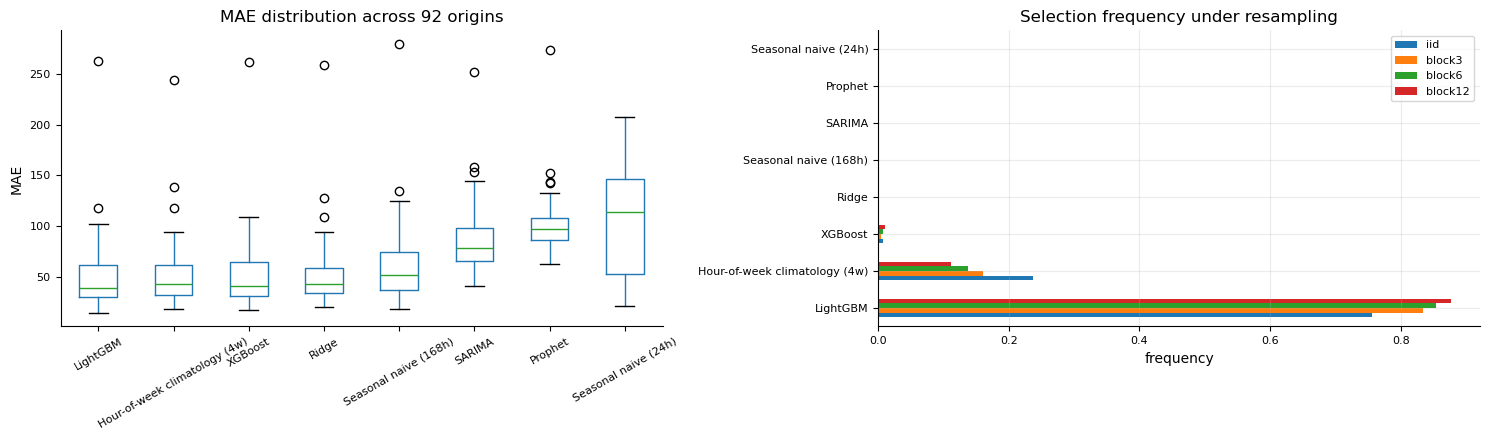

In [42]:
rng = np.random.default_rng(42)
B = 5000
names = list(origin_mae.columns)

# (a) IID bootstrap over origins
wins_iid = {m: 0 for m in names}
for _ in range(B):
    idx = rng.integers(0, len(origin_mae), len(origin_mae))
    wins_iid[origin_mae.iloc[idx].mean().idxmin()] += 1

# (b) moving-block bootstrap at several block lengths, to show whether the answer
#     depends on the choice of block
cols = {"iid": pd.Series(wins_iid) / B}
for BLOCK in [3, 6, 12]:
    n_blocks = int(np.ceil(len(origin_mae) / BLOCK))
    wins_block = {m: 0 for m in names}
    for _ in range(B):
        starts = rng.integers(0, len(origin_mae) - BLOCK + 1, n_blocks)
        idx = np.concatenate([np.arange(st, st + BLOCK) for st in starts])[:len(origin_mae)]
        wins_block[origin_mae.iloc[idx].mean().idxmin()] += 1
    cols[f"block{BLOCK}"] = pd.Series(wins_block) / B
boot = pd.DataFrame(cols).loc[order]
print(f"How often each model has the lowest mean MAE in {B} resamples of the 92 origins.")
print("This is a SELECTION FREQUENCY under resampling, not a probability that a model")
print("is truly best -- it ignores analyst-selection, tuning and feature-design uncertainty.\n")
print(boot.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
origin_mae.boxplot(ax=axes[0], rot=30, grid=False)
axes[0].set(title=f"MAE distribution across {len(origin_mae)} origins", ylabel="MAE")
axes[0].tick_params(labelsize=8)
boot.plot(kind="barh", ax=axes[1])
axes[1].set(title="Selection frequency under resampling", xlabel="frequency")
axes[1].tick_params(labelsize=8); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### Ranking Sensitivity Under Resampling

LightGBM ranks first in **75.6% of IID resamples**, rising to **87.8% with 12-origin blocks**. The climatology takes most of the remaining first places.

The moving blocks preserve local runs of losses; they do not reproduce every source of temporal change or repeat feature design and tuning. These are **selection frequencies conditional on the observed loss table**, not probabilities that a model is truly best.

A model can lead most resamples while its paired mean-loss difference remains unresolved. Ranking frequency and an adjusted hypothesis test summarize different properties of the same evidence.

In [43]:
# RMSE is a SEPARATE question and must keep the leaderboard's estimand. The headline
# RMSE is POOLED -- sqrt(mean of every squared hourly error) -- which is NOT the mean
# of per-origin RMSEs. So inference is done on the 92 paired origin-level MSE values,
# and pooled RMSE is recovered as sqrt(mean(origin MSE)).
origin_mse = P.pivot_table(index="fold", columns="model", values="se")
pooled_rmse = np.sqrt(origin_mse.mean())
mean_fold_rmse = origin_mse.pow(0.5).mean()

cmp = pd.DataFrame({"MAE": origin_mae.mean(), "MAE_rank": origin_mae.mean().rank().astype(int),
                    "pooled_RMSE": pooled_rmse, "pooled_RMSE_rank": pooled_rmse.rank().astype(int),
                    "mean_fold_RMSE": mean_fold_rmse})
print("Primary metric (MAE) against pooled RMSE\n")
print(cmp.sort_values("MAE").round(3).to_string())
print()
print(f"Spearman rank correlation (MAE vs pooled RMSE): "
      f"{stats.spearmanr(cmp['MAE'], cmp['pooled_RMSE']).statistic:.3f}")
flips = [m for m in cmp.index if cmp.loc[m, 'MAE_rank'] != cmp.loc[m, 'pooled_RMSE_rank']]
print(f"Models changing rank with the metric: {len(flips)} of {len(cmp)}")
print()
print(f"(mean-of-fold RMSE is shown only to demonstrate it differs from the pooled value;")
print(f" it is not the leaderboard estimand and is not used for inference)")

Primary metric (MAE) against pooled RMSE

                                   MAE  MAE_rank  pooled_RMSE  pooled_RMSE_rank  mean_fold_RMSE
model                                                                                          
LightGBM                        49.025         1       86.227                 2          73.908
Hour-of-week climatology (4w)   49.856         2       86.774                 3          75.511
XGBoost                         50.255         3       87.514                 4          76.241
Ridge                           51.965         4       85.739                 1          75.197
Seasonal naive (168h)           60.075         5      106.537                 5          93.721
SARIMA                          85.606         6      124.529                 6         117.932
Prophet                        100.451         7      138.193                 7         134.982
Seasonal naive (24h)           105.824         8      166.237                 8         151.36

In [44]:
# DESCRIPTIVE ONLY. The ordering and point differences in pooled RMSE are reported;
# no significance claim is attached to them, for two reasons that apply here exactly
# as they did to the MAE comparison before it was corrected:
#   (1) the reference below is the OBSERVED RMSE leader, chosen from these same
#       results, so any interval family built around it is selected, not predeclared;
#   (2) resampling origins independently ignores the serial dependence measured above.
# RMSE is a secondary metric in this notebook, so rather than build a second
# simultaneous-inference apparatus, the intervals are simply labelled descriptive.
rmse_leader = pooled_rmse.idxmin()
rng2 = np.random.default_rng(7)

print(f"Pooled RMSE, point differences against the observed leader ({rmse_leader}).")
print("Percentile intervals below are DESCRIPTIVE and UNADJUSTED: the reference was")
print("chosen from these results and origins are resampled independently, so they do")
print("NOT support significance claims. MAE, the primary metric, carries the inference.")
print()
print(f"  {'model':32s} {'diff':>8s} {'2.5%':>8s} {'97.5%':>8s}")
for m in [c for c in pooled_rmse.sort_values().index if c != rmse_leader]:
    a = origin_mse[m].to_numpy(); b = origin_mse[rmse_leader].to_numpy()
    obs = np.sqrt(a.mean()) - np.sqrt(b.mean())
    draws = np.empty(B)
    for i in range(B):
        idx = rng2.integers(0, len(a), len(a))
        draws[i] = np.sqrt(a[idx].mean()) - np.sqrt(b[idx].mean())
    lo, hi = np.percentile(draws, [2.5, 97.5])
    print(f"  {m:32s} {obs:8.3f} {lo:8.3f} {hi:8.3f}")

Pooled RMSE, point differences against the observed leader (Ridge).
Percentile intervals below are DESCRIPTIVE and UNADJUSTED: the reference was
chosen from these results and origins are resampled independently, so they do
NOT support significance claims. MAE, the primary metric, carries the inference.

  model                                diff     2.5%    97.5%
  LightGBM                            0.487   -2.494    3.035
  Hour-of-week climatology (4w)       1.035   -1.450    3.565


  XGBoost                             1.775   -1.026    4.549
  Seasonal naive (168h)              20.798   14.757   27.294


  SARIMA                             38.789   29.549   47.883
  Prophet                            52.453   44.460   60.321
  Seasonal naive (24h)               80.498   64.447   95.472


### A Different Metric Changes the Observed Leader

Ridge has the lowest **pooled RMSE, 85.739**, compared with **86.227** for no-weather LightGBM, despite ranking fourth by MAE. Four of eight ranks change, and the rank correlation is **0.857**.

Squared errors give large misses more influence, so there is no requirement that the two metrics select the same procedure. The printed mean of path-specific RMSEs is a different aggregation again; the leaderboard retains pooled RMSE.

The bootstrap difference ranges are **descriptive and unadjusted**, with an observed-data-selected reference and IID origin resampling. I do not attach superiority claims to them. MAE remains the selection metric.

### 7.1 Would a Shorter Training History Help Ridge?

The climatology uses four recent matching weeks, while Ridge uses an expanding target history. I compare expanding, 26-week, 12-week, and 8-week Ridge fits at the same origins, keeping its chosen penalty, target scale, and feature definitions fixed.

This changes the rows used to fit Ridge; lagged predictors can still refer to earlier source history. It is a retrospective sensitivity for **Ridge only**, not a search that replaces the selected configuration or establishes an optimal history length for other families.

In [45]:
def ridge_window(weeks):
    def f(train, val_index):
        tr = train if weeks is None else train.iloc[-24 * 7 * weeks:]
        X, y_, Xv = make_xy(tr, val_index)
        return _fit_predict(ridge_pipeline(ridge_best["alpha"]), X, y_, Xv, ridge_best["log_target"])
    return f

window_rows = []
for label, wk in [("expanding (as used)", None), ("trailing 26w", 26), ("trailing 12w", 12), ("trailing 8w", 8)]:
    out = run_model(ridge_window(wk), f"__win__{label}", verbose=False, store=False)
    window_rows.append({"training window": label, "MAE": (out["y_true"] - out["y_pred"]).abs().mean()})
win = pd.DataFrame(window_rows)
win["vs expanding"] = win["MAE"] - win["MAE"].iloc[0]
print("Ridge under different training-window lengths, same 92 origins:")
print(win.round(3).to_string(index=False))

Ridge under different training-window lengths, same 92 origins:
    training window    MAE  vs expanding
expanding (as used) 51.965         0.000
       trailing 26w 51.905        -0.060
       trailing 12w 52.525         0.560
        trailing 8w 54.893         2.927


The 26-week Ridge fit reduces MAE from **51.965 to 51.905**, an observed gain of **0.060**. The 12- and 8-week alternatives are worse, at **52.525** and **54.893**.

None shows a large observed gain over expanding Ridge in this comparison. No uncertainty analysis of the differences was performed, and the result does not establish that shorter histories would be unhelpful for LightGBM, XGBoost, or Prophet.

### 7.2 Does the Lag-Source Substitution Help Ridge?

Replacing disruption zeros in `y_lagsrc` was motivated by the possibility that a transient collapse could propagate into later lag predictors. That is a feature-policy hypothesis, not an established bias mechanism.

I compare the engineered source with one that retains the disruption zeros. Both use the same DST replacements, so the sources differ only at the 83 disruption positions. The target and scored paths remain unchanged.

As in Section 7.1, the check uses the **frozen Ridge procedure** and does not reopen selection.

In [46]:
def ridge_lagsource(src):
    def f(train, val_index):
        X, y_, Xv = make_xy(train, val_index, lag_source=src)
        return _fit_predict(ridge_pipeline(ridge_best["alpha"]), X, y_, Xv, ridge_best["log_target"])
    return f

lag_rows = []
for src in ["engineered", "raw"]:
    out = run_model(ridge_lagsource(src), f"__lag__{src}", verbose=False, store=False)
    lag_rows.append({"lag source": src, "MAE": (out["y_true"] - out["y_pred"]).abs().mean(),
                     "RMSE": np.sqrt(((out["y_true"] - out["y_pred"]) ** 2).mean())})
lagcmp = pd.DataFrame(lag_rows)
print("Ridge with disruption zeros replaced vs kept, same 92 origins:")
print(lagcmp.round(3).to_string(index=False))
print(f"\ndifference: {lagcmp['MAE'].iloc[1] - lagcmp['MAE'].iloc[0]:+.3f} MAE "
      f"({abs(lagcmp['MAE'].iloc[1] - lagcmp['MAE'].iloc[0]) / lagcmp['MAE'].iloc[0]:.2%})")

Ridge with disruption zeros replaced vs kept, same 92 origins:
lag source    MAE   RMSE
engineered 51.965 85.739
       raw 51.942 85.736

difference: -0.024 MAE (0.05%)


Keeping the disruption zeros gives Ridge MAE **51.942**, versus **51.965** with the substitutions: a displayed difference of **−0.024**, or **0.05%**. RMSE is also nearly unchanged.

The source policy has a small observed effect for this Ridge fit and these paths. This comparison does not establish a benefit from substitution, equivalence between policies, or its effect on the other model families. No uncertainty analysis was performed.

### 7.3 Does Excluding Sandy Change the Full Ranking?

I now apply the same secondary re-scoring used for the baselines to all eight no-weather procedures. It removes the **36 scored Sandy hours**, leaving **4,380 targets per model**. Predictions, training policies, and selected settings remain unchanged.

In [47]:
print("PRIMARY  (every genuine hour)")
print(leaderboard().round(3).to_string())
print()
n_excl = int(P.groupby("model")["is_disruption"].sum().iloc[0])
print(f"SECONDARY (same forecasts, excluding the {n_excl} disruption hours inside scored windows)")
print(leaderboard(normal_ops_only=True).round(3).to_string())

a = leaderboard()["MAE"]; b = leaderboard(normal_ops_only=True)["MAE"]
print()
print("Ordering identical under both scorings:", list(a.index) == list(b.index))

PRIMARY  (every genuine hour)
                                   MAE     RMSE   MASE     n
model                                                       
LightGBM                        49.025   86.227  0.826  4416
Hour-of-week climatology (4w)   49.856   86.774  0.839  4416
XGBoost                         50.255   87.514  0.847  4416
Ridge                           51.965   85.739  0.875  4416
Seasonal naive (168h)           60.075  106.537  1.011  4416
SARIMA                          85.606  124.529  1.440  4416
Prophet                        100.451  138.193  1.690  4416
Seasonal naive (24h)           105.824  166.237  1.782  4416

SECONDARY (same forecasts, excluding the 36 disruption hours inside scored windows)
                                   MAE     RMSE   MASE     n
model                                                       
LightGBM                        47.341   80.836  0.800  4380
Hour-of-week climatology (4w)   48.333   82.447  0.816  4380
XGBoost                        


Ordering identical under both scorings: True


All eight procedures have lower MAE after removing those 36 hours, and **their ordering is unchanged**. LightGBM changes from **49.025 to 47.341** and the climatology from **49.856 to 48.333**.

The observed ranking therefore persists under this scoring restriction. It does not justify choosing the target policy after seeing the results, and it does not measure how earlier disruption observations influenced training or features. Those inputs are left as they were; eligible training histories differ across procedures.

### 7.4 Does Relative Standing Persist Across Periods?

Raw tuning and selection errors describe different target periods. To compare standing within each period, I divide each procedure's MAE by the climatology's MAE **on the same origins**, and report ranks alongside those ratios.

This normalization provides a common within-period reference; it does not remove every difference in target difficulty. The fitted models' tuning scores also have selection optimism because those origins chose their hyperparameters. The baselines have no grid parameters tuned on those origins, although the broader investigation remains adaptive.

In [48]:
tune_scores = {}
for name, maker, best in [("Ridge", make_ridge, ridge_best), ("XGBoost", make_xgb, xgb_best),
                          ("LightGBM", make_lgb, lgb_best), ("Prophet", make_prophet, prophet_best),
                          ("SARIMA", lambda pr: make_sarima(pr, "stability"), sarima_best)]:
    out = run_model(maker(best), f"__stab__{name}", folds=tune_folds, verbose=False, store=False)
    tune_scores[name] = (out["y_true"] - out["y_pred"]).abs().mean()
for name, fn in [("Hour-of-week climatology (4w)", hour_of_week_climatology),
                 ("Seasonal naive (168h)", weekly_naive), ("Seasonal naive (24h)", seasonal_naive)]:
    out = run_model(fn, f"__stab__{name}", folds=tune_folds, verbose=False, store=False)
    tune_scores[name] = (out["y_true"] - out["y_pred"]).abs().mean()

BENCH = "Hour-of-week climatology (4w)"
sel_scores = leaderboard()["MAE"]
stab = pd.DataFrame({"tuning_MAE": pd.Series(tune_scores), "selection_MAE": sel_scores})
stab["tune_rel"] = stab["tuning_MAE"] / stab.loc[BENCH, "tuning_MAE"]
stab["sel_rel"] = stab["selection_MAE"] / stab.loc[BENCH, "selection_MAE"]
stab["tune_rank"] = stab["tuning_MAE"].rank().astype(int)
stab["sel_rank"] = stab["selection_MAE"].rank().astype(int)
stab["rel_shift"] = stab["sel_rel"] - stab["tune_rel"]
stab["tuned"] = [n in {"Ridge", "XGBoost", "LightGBM", "Prophet", "SARIMA"} for n in stab.index]

print(f"Relative standing in each period (MAE / {BENCH} MAE in the SAME period).")
print("tuned=True means that period's hyperparameters were chosen on the tuning origins,")
print("so its tuning column is optimistically biased.\n")
print(stab.sort_values("sel_rel")[["tuning_MAE", "selection_MAE", "tune_rel", "sel_rel",
                                   "tune_rank", "sel_rank", "rel_shift", "tuned"]]
      .round(3).to_string())
print()
print(f"Rank changes between periods: "
      f"{int((stab['tune_rank'] != stab['sel_rank']).sum())} of {len(stab)} models")

Relative standing in each period (MAE / Hour-of-week climatology (4w) MAE in the SAME period).
tuned=True means that period's hyperparameters were chosen on the tuning origins,
so its tuning column is optimistically biased.

                               tuning_MAE  selection_MAE  tune_rel  sel_rel  tune_rank  sel_rank  rel_shift  tuned
LightGBM                           51.005         49.025     1.007    0.983          4         1     -0.023   True
Hour-of-week climatology (4w)      50.674         49.856     1.000    1.000          3         2      0.000  False
XGBoost                            50.421         50.255     0.995    1.008          2         3      0.013   True
Ridge                              49.856         51.965     0.984    1.042          1         4      0.058   True
Seasonal naive (168h)              54.016         60.075     1.066    1.205          5         5      0.139  False
SARIMA                             71.502         85.606     1.411    1.717          

The leading order changes: **Ridge ranks first during tuning and fourth during selection**, while **LightGBM moves from fourth to first**. Four of eight models change rank.

Prophet and SARIMA also become worse relative to the climatology: their ratios rise from **1.565 to 2.015** and **1.411 to 1.717**, respectively. The ratios document changing relative performance; they do not identify whether tuning optimism, seasonal composition, changing conditions, or another factor caused it.

The close ordering of the leading candidates reinforces the need to distinguish an observed selection from a stable population ranking.

## Section 8: Adding Weather and Evaluating Uncertainty

The no-weather comparison leaves a small leading cluster rather than a decisive separation from climatology. I now investigate weather using the selected LightGBM configuration, then ask whether its intervals represent the observed forecast errors adequately.

There are two separate decisions:

1. Choose between **no weather and lagged observed weather**, using the earlier tuning paths.
2. Assess uncertainty around the resulting carried forecasts, with calibration preceding assessment.

The oracle scenario is computed only after the deployable choice is bound. It is an information contrast, not another candidate eligible for final evaluation.

Hyperparameters remain those selected without weather. These experiments evaluate the added inputs for that frozen configuration rather than compare independently optimized weather models.

### 8.1 Selecting a Deployable Weather Mode

The implemented rule carries lagged weather only when

$$
\operatorname{MAE}_{\mathrm{none}}-
\operatorname{MAE}_{\mathrm{lagged}}>0.25
$$

on the **22 tuning origins**. Otherwise it carries the simpler no-weather mode, including at equality. The 0.25-rental tolerance is a chosen complexity threshold, not an estimated operating-cost cutoff.

Lagged weather uses the target timestamp minus **48 hours**. Across a path, its source positions range from 48 hours before the first prediction to one hour before it. Combined with causal forward filling, these weather values precede issuance.

Weather-mode selection avoids using the later interval-assessment outcomes for that additional decision. Model-family selection still uses all 92 selection paths, including those assessment paths, so the complete pipeline assessment remains developmental.

In [49]:
# THE RULE, BOUND BEFORE ANY WEATHER RESULT EXISTS.
SELECTION_TOLERANCE = 0.25        # rentals/hour; below this, prefer the simpler configuration
SELECTION_ORIGINS = "tuning"      # the 22 tuning origins, never the 92 selection origins
DEPLOYABLE_MODES = ["none", "lagged"]
print(f"Selection rule fixed: carry the deployable mode with lower MAE on the {SELECTION_ORIGINS}")
print(f"origins; gaps below {SELECTION_TOLERANCE} rentals/hour resolve to the simpler configuration.")
print(f"Deployable candidates: {DEPLOYABLE_MODES}   (the oracle is not a candidate)")

Selection rule fixed: carry the deployable mode with lower MAE on the tuning
origins; gaps below 0.25 rentals/hour resolve to the simpler configuration.
Deployable candidates: ['none', 'lagged']   (the oracle is not a candidate)


In [50]:
# Every deployable weather source must precede its forecast origin -- checked at ALL origins.
_bad = 0
for _o in pd.concat([tune_folds["val_start"], cv_folds["val_start"]]):
    _src = pd.date_range(_o, periods=HORIZON, freq="h") - pd.Timedelta(hours=HORIZON)
    _bad += int((_src >= _o).sum())
assert _bad == 0, "a deployable weather source did not precede its origin"
print(f"Deployable weather timing verified at all {len(tune_folds) + len(cv_folds)} origins: "
      f"{_bad} violations.")

def make_lgb_weather(mode):
    def f(train, val_index):
        X_tr, y_tr, X_va = make_xy(train, val_index, weather_mode=mode)
        m = lgb.LGBMRegressor(objective=lgb_best["objective"], random_state=42, n_jobs=4, verbose=-1,
                              n_estimators=400, learning_rate=0.05, num_leaves=lgb_best["num_leaves"],
                              subsample=0.8, subsample_freq=1, colsample_bytree=0.8)
        return _fit_predict(m, X_tr, y_tr, X_va, lgb_best["log_target"])
    return f

# ---- deployable candidates, scored on the TUNING origins only ---------------
tune_mae = {}
for mode in DEPLOYABLE_MODES:
    out = run_model(make_lgb_weather(mode), f"__wtune__{mode}", folds=tune_folds,
                    verbose=False, store=False)
    tune_mae[mode] = (out["y_true"] - out["y_pred"]).abs().mean()
print()
print(f"Deployable candidates on the {len(tune_folds)} tuning origins:")
for m, v in tune_mae.items():
    print(f"  weather={m:8s} MAE {v:7.3f}")

Deployable weather timing verified at all 114 origins: 0 violations.



Deployable candidates on the 22 tuning origins:
  weather=none     MAE  51.005
  weather=lagged   MAE  49.435


In [51]:
# Apply the rule bound above.
_gap = tune_mae["none"] - tune_mae["lagged"]
if _gap > SELECTION_TOLERANCE:
    CARRIED_WEATHER_MODE = "lagged"
    _why = f"deployable weather is better by {_gap:.3f} MAE on the tuning origins (> {SELECTION_TOLERANCE})"
else:
    CARRIED_WEATHER_MODE = "none"
    _why = (f"deployable weather does not improve tuning MAE by more than {SELECTION_TOLERANCE} "
            f"(gap {_gap:+.3f}); the simpler configuration is carried")
CARRIED_NAME = f"LightGBM (weather={CARRIED_WEATHER_MODE})"
print(f"CARRIED PIPELINE: {CARRIED_NAME}")
print(f"  {_why}")

# Generate forecasts over all 92 selection origins. They did not choose the weather
# mode above, but their scores did inform the earlier model-family selection.
CARRIED_PRED = run_model(make_lgb_weather(CARRIED_WEATHER_MODE),
                         f"__carried__{CARRIED_WEATHER_MODE}", verbose=False, store=False)
print(f"  selection-origin forecasts generated: {len(CARRIED_PRED)} rows over "
      f"{CARRIED_PRED['fold'].nunique()} origins")
print(f"  selection-origin MAE: {(CARRIED_PRED['y_true'] - CARRIED_PRED['y_pred']).abs().mean():.3f}")
print()
print("Predeclared benchmarks reported alongside it in the final block:")
for b in ["Hour-of-week climatology (4w)", "Seasonal naive (168h)", "Seasonal naive (24h)"]:
    print(f"  - {b}")

CARRIED PIPELINE: LightGBM (weather=lagged)
  deployable weather is better by 1.570 MAE on the tuning origins (> 0.25)


  selection-origin forecasts generated: 4416 rows over 92 origins
  selection-origin MAE: 48.590

Predeclared benchmarks reported alongside it in the final block:
  - Hour-of-week climatology (4w)
  - Seasonal naive (168h)
  - Seasonal naive (24h)


### Applying the Weather Rule

The saved timing check reports **zero violations across 114 tuning and selection origins**. On the tuning paths, lagged weather reduces MAE from **51.005 to 49.435**, an improvement of **1.570**, exceeding the 0.25 threshold.

The carried pipeline is therefore **LightGBM with lagged weather**, retaining the raw-target absolute-error objective and 63-leaf setting selected earlier.

Its selection MAE is **48.590**, versus **49.025** for no-weather LightGBM. That **0.435** observed reduction concerns a different period from the tuning gain and has no separate uncertainty analysis. Section 8.4 evaluates the carried pipeline against the full comparator family.

### 8.2 What Changes When Actual Future Weather Is Supplied?

To investigate the information gap, I give the same frozen LightGBM configuration realized weather at each target hour. Those measurements would be unavailable when issuing the path, so this is an **oracle-information scenario**.

The deployable choice is already fixed. This contrast cannot enter the implemented weather-selection rule or replace the carried pipeline.

In [52]:
# Only now, with the carried pipeline bound above, does the oracle run.
assert "CARRIED_WEATHER_MODE" in dir(), "the carried mode must be fixed before the oracle"
oracle = run_model(make_lgb_weather("foresight"), "__w__oracle", verbose=False, store=False)
oracle_mae = (oracle["y_true"] - oracle["y_pred"]).abs().mean()

_carried_sel_mae = (CARRIED_PRED["y_true"] - CARRIED_PRED["y_pred"]).abs().mean()
summary_w = pd.DataFrame([
    {"scenario": f"carried: weather={CARRIED_WEATHER_MODE}", "deployable": True, "MAE": _carried_sel_mae},
    {"scenario": "ORACLE: actual weather at the target hour", "deployable": False, "MAE": oracle_mae},
])
summary_w["vs carried"] = summary_w["MAE"] - _carried_sel_mae
print(summary_w.round(3).to_string(index=False))
print()
print(f"The oracle configuration's OBSERVED MAE was {_carried_sel_mae - oracle_mae:.2f} lower "
      f"({(_carried_sel_mae - oracle_mae)/_carried_sel_mae:.1%}) on these 92 origins.")
print(f"This is an ORACLE-INFORMATION SCENARIO, not a mathematical upper")
print(f"bound: it is this frozen configuration given information it cannot have. A model")
print(f"re-tuned with weather, or given a real weather forecast, could land either side")
print(f"of it. It plays no part in selecting {CARRIED_NAME}, which was fixed above.")

                                 scenario  deployable    MAE  vs carried
                  carried: weather=lagged        True 48.590        0.00
ORACLE: actual weather at the target hour       False 38.909       -9.68

The oracle configuration's OBSERVED MAE was 9.68 lower (19.9%) on these 92 origins.
This is an ORACLE-INFORMATION SCENARIO, not a mathematical upper
bound: it is this frozen configuration given information it cannot have. A model
re-tuned with weather, or given a real weather forecast, could land either side
of it. It plays no part in selecting LightGBM (weather=lagged), which was fixed above.


Oracle MAE is **38.909**, compared with **48.590** for the carried pipeline: **9.68 rentals lower**, or **19.9%**.

This is an observed difference under a changed information set, not a guaranteed improvement available from operational weather forecasts. Nor is it a mathematical accuracy bound: the finite model and its hyperparameters are fixed, and actual weather forecasts would contain errors.

The result motivates a future test using archived weather forecasts available at each issue time. It does not justify substituting realized future weather into this evaluation.

### 8.3 Prediction Intervals: Calibration Before Assessment

A favorable point-error ranking does not describe how often an interval misses. I compare **nominal 80% pointwise intervals** using the earlier **55 selection paths for calibration** and the later **37 for assessment**.

The constructions are:

- **Gaussian residual intervals:** the carried point forecast plus or minus a normal quantile times the calibration residual standard deviation, pooled or estimated separately by horizon. Centering them on the forecast imposes a zero-bias approximation.
- **Absolute-residual intervals using a conformal calibration rank:** pooled or separately by horizon, around the same carried forecasts.
- **Prophet's native intervals:** simulated by its own fitted model. These use different point forecasts and therefore compare whole forecasting pipelines, rather than alternative interval methods around one predictor.

For absolute calibration errors $a_1,\ldots,a_n$, the empirical construction takes the $k$th smallest score:

$$
k=\left\lceil(n+1)(1-\alpha)\right\rceil,
\qquad
[\max(0,\hat y-q),\ \hat y+q].
$$

Here $\alpha=0.2$. When $k>n$, the code returns infinity rather than substituting an unsupported finite rank. A per-horizon construction uses that horizon's errors; pooling uses errors across all steps.

The [conformal reference](https://arxiv.org/abs/2107.07511) explains the rank and its validity assumptions. **Using the rank does not establish exchangeability** for temporally dependent errors from repeatedly refitted models. I assess coverage empirically without claiming a distribution-free guarantee.

Calibration is chronologically separate from assessment, but the later paths contributed to choosing the model family. This is a developmental uncertainty assessment, not an independent evaluation of the full selected pipeline.

Widths are measured after clipping bounds at zero. Coverage here concerns individual hourly outcomes; **no simultaneous 48-hour path-coverage claim is evaluated**.

In [53]:
import math
from scipy import stats as _st

def conformal_quantile(scores, alpha):
    """Split-conformal quantile via the exact order statistic.

    k = ceil((n+1)(1-alpha)); qhat is the k-th smallest score, or infinity if k > n.
    A generic quantile call is NOT equivalent: its indexing convention can land on a
    neighbouring order statistic, verified to differ in every case tested here.
    """
    s = np.sort(np.asarray(scores, dtype=float))
    n = s.size
    assert n > 0, "conformal calibration set is empty"
    assert np.isfinite(s).all(), "conformal calibration scores must all be finite"
    k = math.ceil((n + 1) * (1 - alpha))
    return np.inf if k > n else s[k - 1]

ALPHA = 0.2          # 80% target coverage
CAL_FRAC = 0.6

folds_sorted = cv_folds.sort_values("val_start").reset_index(drop=True)
n_cal = int(round(CAL_FRAC * len(folds_sorted)))
cal_folds, asm_folds = folds_sorted.iloc[:n_cal], folds_sorted.iloc[n_cal:]
assert asm_folds["val_start"].min() > cal_folds["val_end"].max(), \
    "every assessment origin must fall strictly after the last calibration origin"
print(f"Calibration: {len(cal_folds)} origins  {cal_folds['val_start'].min()} -> {cal_folds['val_end'].max()}")
print(f"Assessment:  {len(asm_folds)} origins  {asm_folds['val_start'].min()} -> {asm_folds['val_end'].max()}")
print(f"Target coverage: {1-ALPHA:.0%}  (the NOMINAL quantity; half-widths below are calibration-derived)")

Calibration: 55 origins  2012-04-30 00:00:00 -> 2012-08-17 23:00:00
Assessment:  37 origins  2012-08-18 00:00:00 -> 2012-10-30 23:00:00
Target coverage: 80%  (the NOMINAL quantity; half-widths below are calibration-derived)


In [54]:
# All intervals are built from the CARRIED pipeline's forecasts, not the Section 6 run.
cal = CARRIED_PRED[CARRIED_PRED["fold"].isin(cal_folds["fold"])]
asm = CARRIED_PRED[CARRIED_PRED["fold"].isin(asm_folds["fold"])].copy()
print(f"Intervals calibrated on the carried pipeline: {CARRIED_NAME}")
print(f"  calibration hours {len(cal)}, assessment hours {len(asm)}")

signed_cal = cal["y_true"] - cal["y_pred"]
resid_cal = signed_cal.abs()
z = _st.norm.ppf(1 - ALPHA / 2)

# The Gaussian comparator centres on the point forecast, i.e. assumes zero-mean residuals.
print(f"Calibration residual mean: {signed_cal.mean():+.2f} rentals against sd {signed_cal.std():.2f}")
print(f"  -> small OBSERVED average bias ({signed_cal.mean()/signed_cal.std():.1%} of sd). A"
      f" descriptive fact, not evidence that the zero-mean assumption holds.")
print(f"Calibration residual skew: {signed_cal.skew():+.2f}, excess kurtosis {signed_cal.kurtosis():+.2f}")

half = {
    "gaussian_pooled": float(z * (cal["y_true"] - cal["y_pred"]).std()),
    "conformal_pooled": conformal_quantile(resid_cal, ALPHA),
}
gauss_by_h = cal.groupby("h").apply(lambda g: z * (g["y_true"] - g["y_pred"]).std(), include_groups=False)
conf_by_h = cal.groupby("h").apply(lambda g: conformal_quantile((g["y_true"] - g["y_pred"]).abs(), ALPHA),
                                   include_groups=False)

asm["half_gaussian_pooled"] = half["gaussian_pooled"]
asm["half_conformal_pooled"] = half["conformal_pooled"]
asm["half_gaussian_per_h"] = asm["h"].map(gauss_by_h)
asm["half_conformal_per_h"] = asm["h"].map(conf_by_h)

print()
print("Calibration-derived half-widths (rentals):")
print(f"  gaussian  pooled {half['gaussian_pooled']:7.1f}   per-step {gauss_by_h.min():.1f} .. {gauss_by_h.max():.1f}")
print(f"  conformal pooled {half['conformal_pooled']:7.1f}   per-step {conf_by_h.min():.1f} .. {conf_by_h.max():.1f}")

Intervals calibrated on the carried pipeline: LightGBM (weather=lagged)
  calibration hours 2640, assessment hours 1776
Calibration residual mean: +1.74 rentals against sd 76.78
  -> small OBSERVED average bias (2.3% of sd). A descriptive fact, not evidence that the zero-mean assumption holds.
Calibration residual skew: -0.92, excess kurtosis +7.98

Calibration-derived half-widths (rentals):
  gaussian  pooled    98.4   per-step 6.0 .. 185.4
  conformal pooled    76.1   per-step 5.7 .. 182.7


In [55]:
# Lower bounds clipped at zero; widths computed AFTER clipping.
rows = []
for nm in ["gaussian_pooled", "gaussian_per_h", "conformal_pooled", "conformal_per_h"]:
    # "gaussian" = zero-mean Gaussian residual comparator (see above)
    hw = asm[f"half_{nm}"].to_numpy()
    lo = np.clip(asm["y_pred"].to_numpy() - hw, 0, None)
    hi = asm["y_pred"].to_numpy() + hw
    cov = ((asm["y_true"].to_numpy() >= lo) & (asm["y_true"].to_numpy() <= hi))
    asm[f"cov_{nm}"] = cov.astype(int)
    rows.append({"interval": nm, "coverage": cov.mean(),
                 "mean width (after clipping)": (hi - lo).mean(),
                 "lower bounds clipped": int((asm["y_pred"].to_numpy() - hw < 0).sum())})
itab = pd.DataFrame(rows)
print(f"TIME-ORDERED EMPIRICAL COVERAGE on {asm['fold'].nunique()} assessment origins "
      f"({len(asm)} hours), target {1-ALPHA:.0%}")
print()
print(itab.round(3).to_string(index=False))
print()
print("This is time-ordered empirical coverage, NOT a finite-sample guarantee. The")
print("conformal guarantee requires exchangeability, which chronologically ordered demand")
print("residuals plausibly violate. The exact order statistic removes an off-by-one error")
print("in the quantile; it does not supply the assumption.")

TIME-ORDERED EMPIRICAL COVERAGE on 37 assessment origins (1776 hours), target 80%

        interval  coverage  mean width (after clipping)  lower bounds clipped
 gaussian_pooled     0.869                      179.208                   458
  gaussian_per_h     0.843                      167.669                   219
conformal_pooled     0.816                      140.119                   422
 conformal_per_h     0.819                      149.814                   181

This is time-ordered empirical coverage, NOT a finite-sample guarantee. The
conformal guarantee requires exchangeability, which chronologically ordered demand
residuals plausibly violate. The exact order statistic removes an off-by-one error
in the quantile; it does not supply the assumption.


### What Calibration and Coverage Show

The calibration set contains **2,640 errors**, followed by **1,776 assessment hours**. Its signed forecast errors have mean **+1.74**, standard deviation **76.78**, skew **−0.92**, and excess kurtosis **7.98**. Unlike the earlier STL diagnostics, these summarize actual carried-pipeline forecast errors. A small mean relative to the standard deviation does not establish symmetry or tail adequacy.

| Construction | Displayed coverage | Mean width after clipping |
|:---|---:|---:|
| Gaussian, pooled | 86.9% | 179.208 |
| Gaussian, per horizon | 84.3% | 167.669 |
| Empirical conformal-rank, pooled | 81.6% | 140.119 |
| Empirical conformal-rank, per horizon | 81.9% | 149.814 |

Both empirical constructions are closer to the **80% target** and narrower than their Gaussian counterparts on these assessment paths. This does not identify why the Gaussian intervals are wider or establish general superiority. Coverage should be read with width; no proper interval-score comparison is reported here.

The pooled empirical interval is narrower on average, while the per-horizon version can vary with the pronounced daily error profile. Their similar aggregate coverage does not establish equally good coverage at every hour.

In [56]:
# Prophet's native interval is evaluated here; SARIMA also has native interval support.
def prophet_native(train, val_index, seed):
    # Prophet's default intervals come from stochastic predictive simulation, not full
    # posterior sampling -- the default fit is MAP. The seed is set per origin so the
    # reported coverage is reproducible.
    np.random.seed(seed)
    pdf = train.loc[train["y"].notna(), ["y"]].reset_index(); pdf.columns = ["ds", "y"]
    m = Prophet(seasonality_mode=prophet_best["seasonality_mode"], changepoint_prior_scale=0.05,
                yearly_seasonality=prophet_best["yearly_seasonality"],
                weekly_seasonality=True, daily_seasonality=True,
                holidays=PROPHET_HOLIDAYS if prophet_best["use_holidays"] else None,
                interval_width=1 - ALPHA)
    m.fit(pdf)
    f = m.predict(pd.DataFrame({"ds": val_index}))
    return f[["yhat", "yhat_lower", "yhat_upper"]].to_numpy()

rows = []
for _, f in asm_folds.iterrows():
    tr = df.loc[df.index < f["val_start"]]
    vi = pd.date_range(f["val_start"], f["val_end"], freq="h")
    yh = prophet_native(tr, vi, seed=int(f["fold"]))
    # clip BOTH bounds at zero: an interval lying entirely below zero would otherwise keep
    # a negative upper bound and report a nonsensical width after one-sided clipping
    lo = np.clip(yh[:, 1], 0, None)
    hi = np.clip(yh[:, 2], 0, None)
    assert np.isfinite(lo).all() and np.isfinite(hi).all(), "Prophet bound not finite"
    assert (hi >= lo).all(), "Prophet upper bound below lower bound after clipping"
    rows.append(pd.DataFrame({"ds": vi, "y_true": df.loc[vi, "y"].to_numpy(), "lo": lo, "hi": hi}))
pn = pd.concat(rows, ignore_index=True).dropna(subset=["y_true"])
pn_cov = ((pn["y_true"] >= pn["lo"]) & (pn["y_true"] <= pn["hi"])).mean()
print(f"Prophet native interval on the same {len(asm_folds)} assessment origins:")
print(f"  coverage {pn_cov:.1%} against a {1-ALPHA:.0%} target, "
      f"mean width (after clipping) {(pn['hi'] - pn['lo']).mean():.1f}")
print()
print("Prophet's interval is genuinely native -- produced by its own stochastic predictive")
print("simulation rather than a bolt-on --")
print("and is shown because the carried pipeline has none. It is NOT a like-for-like")
print("comparison: it wraps a different model's point forecasts, so its coverage and width")
print("describe the whole Prophet pipeline rather than an alternative interval for the")
print("carried one. Both bounds are clipped at zero and reproducibility is seeded per origin.")

Prophet native interval on the same 37 assessment origins:
  coverage 67.9% against a 80% target, mean width (after clipping) 230.4

Prophet's interval is genuinely native -- produced by its own stochastic predictive
simulation rather than a bolt-on --
and is shown because the carried pipeline has none. It is NOT a like-for-like
comparison: it wraps a different model's point forecasts, so its coverage and width
describe the whole Prophet pipeline rather than an alternative interval for the
carried one. Both bounds are clipped at zero and reproducibility is seeded per origin.


Prophet's native interval covers **67.9%** of assessment hours, with mean clipped width **230.4**, despite its nominal 80% setting.

This describes the tested Prophet pipeline, including its different point forecasts and simulated uncertainty. It does not isolate interval construction as the reason for the difference from the carried model. The simulations are seeded per origin and use default MAP fitting rather than full posterior sampling.

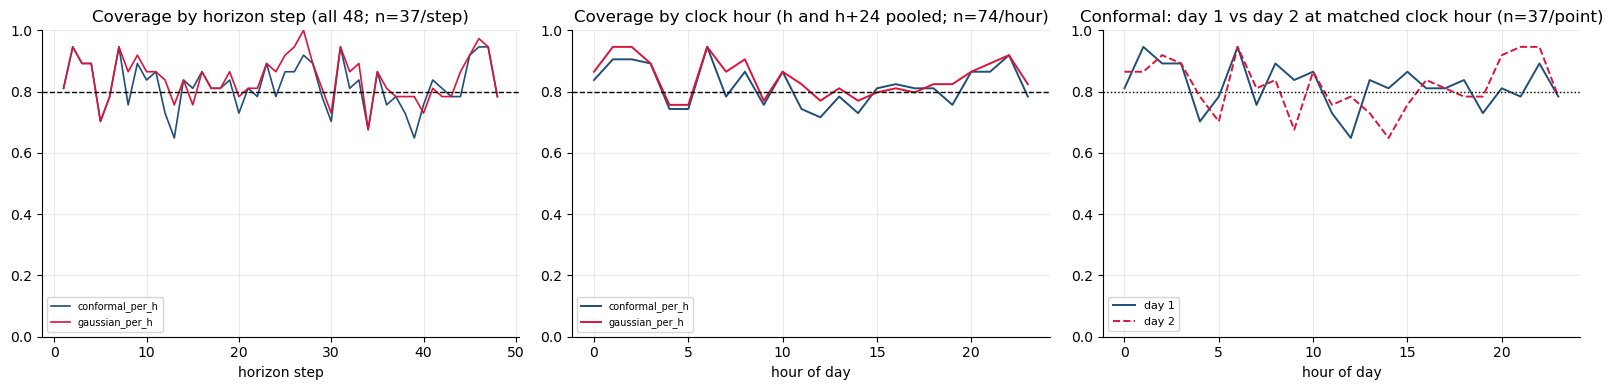

Observation counts: 37 hours per horizon step, 74 per pooled clock hour, 1776 total.

Conformal (per-step) OBSERVED coverage by forecast day at matched clock hours, target 80%:
  day 1: 82.0%   mean half-width 71.2
  day 2: 81.9%   mean half-width 79.5

Lowest observed coverage:  {12: 0.716, 14: 0.73, 4: 0.743}
Highest observed coverage: {6: 0.946, 22: 0.919, 1: 0.905}
  DESCRIPTIVE ranking only: at 74 observations per pooled clock hour, one observation is 1.35 percentage points, so these orderings are not assessed for statistical differences here.


In [57]:
# Coverage three ways: horizon step is 2-to-1 confounded with clock hour.
asm2 = asm.assign(clock_hour=asm["ds"].dt.hour, day=np.where(asm["h"] <= 24, "day 1", "day 2"))
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for nm, c in [("conformal_per_h", "#1f4e79"), ("gaussian_per_h", "crimson")]:
    axes[0].plot(asm2.groupby("h")[f"cov_{nm}"].mean(), lw=1.2, color=c, label=nm)
    axes[1].plot(asm2.groupby("clock_hour")[f"cov_{nm}"].mean(), lw=1.4, color=c, label=nm)
_n_per_step = asm2.groupby("h").size().median()
_n_per_hour = asm2.groupby("clock_hour").size().median()
for ax, t, x in [(axes[0], f"Coverage by horizon step (all 48; n={_n_per_step:.0f}/step)", "horizon step"),
                 (axes[1], f"Coverage by clock hour (h and h+24 pooled; n={_n_per_hour:.0f}/hour)", "hour of day")]:
    ax.axhline(1 - ALPHA, color="black", ls="--", lw=1); ax.set(title=t, xlabel=x, ylim=(0, 1))
    ax.legend(fontsize=7)
asm2.pivot_table(index="clock_hour", columns="day", values="cov_conformal_per_h").plot(
    ax=axes[2], lw=1.4, style=["-", "--"], color=["#1f4e79", "crimson"])
axes[2].axhline(1 - ALPHA, color="black", ls=":", lw=1)
axes[2].set(title=f"Conformal: day 1 vs day 2 at matched clock hour (n={_n_per_step:.0f}/point)",
            xlabel="hour of day", ylim=(0, 1))
axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"Observation counts: {_n_per_step:.0f} hours per horizon step, "
      f"{_n_per_hour:.0f} per pooled clock hour, {len(asm2)} total.")
print()
print(f"Conformal (per-step) OBSERVED coverage by forecast day at matched clock hours, "
      f"target {1-ALPHA:.0%}:")
for d, g in asm2.groupby("day"):
    print(f"  {d}: {g['cov_conformal_per_h'].mean():.1%}   mean half-width {g['half_conformal_per_h'].mean():.1f}")
by_c = asm2.groupby("clock_hour")["cov_conformal_per_h"].mean()
print()
print(f"Lowest observed coverage:  {by_c.nsmallest(3).round(3).to_dict()}")
print(f"Highest observed coverage: {by_c.nlargest(3).round(3).to_dict()}")
print(f"  DESCRIPTIVE ranking only: at {_n_per_hour:.0f} observations per pooled clock hour,"
      f" one observation is {100/_n_per_hour:.2f} percentage points, so these orderings are"
      f" not assessed for statistical differences here.")

### Aggregate Coverage Can Hide Hourly Differences

Per-horizon empirical coverage averages **82.0% on day one** and **81.9% on day two**. These similar aggregates conceal differences across clock hours: pooled clock-hour coverage is **71.6% at noon**, while it reaches **94.6% at 06:00**.

Each horizon has **37 outcomes**; pooling its two corresponding steps gives **74 per clock hour**. One outcome changes that pooled rate by about **1.35 percentage points**. These counts are not effective independent sample sizes, and no test of the hourly ordering was performed.

The figures reveal where coverage varied in this development assessment. Because all paths start at midnight, they cannot isolate a pure lead-time effect from clock hour and forecast day.

### 8.4 Recomputing the Comparison for the Carried Pipeline

Section 7 evaluated **no-weather LightGBM**. The carried forecasts differ, so their paired loss differences, standard errors, and adjusted comparisons must be computed from the carried prediction table.

The eight-model family now substitutes **LightGBM with lagged weather** for its no-weather version, retaining the other seven comparators. The no-weather version is not an additional ninth competitor in this table.

The next checks require all eight models to forecast the same **92 × 48 timestamps**, with identical targets and no missing or duplicate entries. I then repeat the 28-pair Holm comparisons under IID and lag-4 HAC references, and the ranking-resampling diagnostic.

Weather mode was chosen on the earlier tuning paths, but LightGBM's family selection used these 92 paths. This remains the authoritative **developmental comparison** for the carried configuration, not an independent confirmation of its selection.

In [58]:
# Eight-model family: the carried pipeline plus the seven original comparators.
_others = [p for p in predictions if p["model"].iloc[0] != "LightGBM"]
_carried = CARRIED_PRED.copy()
_carried["model"] = CARRIED_NAME
P8 = pd.concat(_others + [_carried], ignore_index=True)
P8["ae"] = (P8["y_true"] - P8["y_pred"]).abs()
P8["se"] = (P8["y_true"] - P8["y_pred"]) ** 2

assert P8["model"].nunique() == 8, "the final family must contain exactly eight models"
assert "LightGBM" not in set(P8["model"]), "the no-weather variant must not appear as a ninth candidate"

# Eight names is not the same as eight models forecasting the SAME observations. The
# paired inference below is only valid if every model covers every one of the 92 x 48
# hours and agrees on the truth at each, so that is checked rather than assumed.
assert not P8.duplicated(["model", "fold", "ds"]).any(),     "duplicate (model, fold, ds) rows -- a row count can look right while a timestamp is absent"
assert (P8.groupby(["model", "fold"]).size() == HORIZON).all(),     "every model must produce exactly HORIZON forecasts at every origin"
assert P8.groupby("model")["fold"].nunique().eq(len(cv_folds)).all(),     "every model must cover every origin"

_truth = P8.pivot_table(index=["fold", "ds"], columns="model", values="y_true")
# Shape and completeness FIRST: nunique(axis=1) skips NaN, so a model missing at some
# timestamp would leave a NaN there and the surviving seven would still "agree".
assert _truth.shape == (len(cv_folds) * HORIZON, 8),     f"expected {len(cv_folds) * HORIZON} x 8 truth grid, got {_truth.shape}"
assert _truth.notna().all().all(), "some model is absent at some timestamp"
assert _truth.nunique(axis=1).eq(1).all(),     "models disagree on the observed value at some hour -- the comparison is not paired"
print(f"Pairing verified: 8 models x {len(cv_folds)} origins x {HORIZON} hours "
      f"= {_truth.shape[0]} timestamps, no duplicates, none missing, identical truth at each.")
print(f"Final eight-model family ({P8['model'].nunique()} models, {len(P8)} rows):")
for m in sorted(P8["model"].unique()):
    print(f"  - {m}")

omae8 = P8.pivot_table(index="fold", columns="model", values="ae")
assert not omae8.isna().any().any(), "origin-level MAE matrix has gaps"
order8 = omae8.mean().sort_values().index.tolist()
omae8 = omae8[order8]
print()
print(pd.DataFrame({"MAE": omae8.mean().round(3),
                    "sd_across_origins": omae8.std().round(2),
                    "sem_unpaired": (omae8.std()/np.sqrt(len(omae8))).round(3)}).to_string())

Pairing verified: 8 models x 92 origins x 48 hours = 4416 timestamps, no duplicates, none missing, identical truth at each.
Final eight-model family (8 models, 35328 rows):
  - Hour-of-week climatology (4w)
  - LightGBM (weather=lagged)
  - Prophet
  - Ridge
  - SARIMA
  - Seasonal naive (168h)
  - Seasonal naive (24h)
  - XGBoost

                                   MAE  sd_across_origins  sem_unpaired
model                                                                  
LightGBM (weather=lagged)       48.590              30.26         3.155
Hour-of-week climatology (4w)   49.856              30.04         3.132
XGBoost                         50.255              30.06         3.134
Ridge                           51.965              30.16         3.145
Seasonal naive (168h)           60.075              34.34         3.580
SARIMA                          85.606              31.28         3.262
Prophet                        100.451              24.79         2.585
Seasonal naive (24

In [59]:
# Holm across ALL 28 pairs, under IID and under the lag-4 Bartlett HAC sensitivity.
pairs8 = []
for a, b in combinations(order8, 2):
    d = (omae8[a] - omae8[b]).to_numpy()
    _, p_iid = stats.ttest_rel(omae8[a], omae8[b])
    se_h = hac_sem(d)
    p_hac = 2 * (1 - stats.norm.cdf(abs(d.mean() / se_h)))
    pairs8.append({"model_a": a, "model_b": b, "diff_a_minus_b": d.mean(),
                   "sem_paired": d.std(ddof=1)/np.sqrt(len(d)), "p_raw": p_iid,
                   "sem_hac": se_h, "p_raw_hac": p_hac})
pairs8 = pd.DataFrame(pairs8)
pairs8["p_holm"] = holm(pairs8["p_raw"].to_numpy())
pairs8["p_holm_hac"] = holm(pairs8["p_raw_hac"].to_numpy())

ref8 = order8[0]
lead8 = pairs8[(pairs8.model_a == ref8) | (pairs8.model_b == ref8)].copy()
lead8["challenger"] = np.where(lead8.model_a == ref8, lead8.model_b, lead8.model_a)
lead8["diff_vs_leader"] = np.where(lead8.model_a == ref8, -lead8.diff_a_minus_b, lead8.diff_a_minus_b)
lead8["origins_better"] = [float(((omae8[c] - omae8[ref8]) < 0).mean()) for c in lead8["challenger"]]

print(f"Holm across all {len(pairs8)} pairs. Comparisons involving the observed leader ({ref8}):")
print("positive diff = worse than the leader")
print()
print(lead8.sort_values("diff_vs_leader")[["challenger", "diff_vs_leader", "sem_paired",
                                          "p_holm", "sem_hac", "p_holm_hac", "origins_better"]]
      .to_string(index=False, float_format=fmt_p))
print()
print(f"Comparisons changing resolution at 0.05 between IID and HAC: "
      f"{int(((pairs8.p_holm < 0.05) != (pairs8.p_holm_hac < 0.05)).sum())} of {len(pairs8)}")

Holm across all 28 pairs. Comparisons involving the observed leader (LightGBM (weather=lagged)):
positive diff = worse than the leader

                   challenger  diff_vs_leader  sem_paired    p_holm   sem_hac  p_holm_hac  origins_better
Hour-of-week climatology (4w)          1.2662      1.0872    0.7416    1.0304      0.4626          0.4891
                      XGBoost          1.6659      0.6575    0.0780    0.6462      0.0596          0.3696
                        Ridge          3.3757      0.9646    0.0051    1.0942      0.0142          0.2826
        Seasonal naive (168h)         11.4854      1.7773   <0.0001    1.7196     <0.0001          0.2174
                       SARIMA         37.0169      2.5293   <0.0001    2.3424     <0.0001          0.0217
                      Prophet         51.8613      1.9689   <0.0001    2.1542     <0.0001          0.0109
         Seasonal naive (24h)         57.2340      5.0942   <0.0001    4.1369     <0.0001          0.1196

Comparisons cha

In [60]:
# Bootstrap selection frequencies for the final family.
rng8 = np.random.default_rng(42)
B8 = 5000
cols8 = {}
w = {m: 0 for m in order8}
for _ in range(B8):
    idx = rng8.integers(0, len(omae8), len(omae8))
    w[omae8.iloc[idx].mean().idxmin()] += 1
cols8["iid"] = pd.Series(w) / B8
for BLOCK in [3, 6, 12]:
    w = {m: 0 for m in order8}
    nb_ = int(np.ceil(len(omae8)/BLOCK))
    for _ in range(B8):
        st = rng8.integers(0, len(omae8)-BLOCK+1, nb_)
        idx = np.concatenate([np.arange(s0, s0+BLOCK) for s0 in st])[:len(omae8)]
        w[omae8.iloc[idx].mean().idxmin()] += 1
    cols8[f"block{BLOCK}"] = pd.Series(w) / B8
print(f"Selection frequency over {B8} resamples of the {len(omae8)} origins.")
print("This is a SELECTION FREQUENCY under resampling. It is not a probability of being")
print("truly best, and it ignores tuning, feature-design and analyst-selection uncertainty.")
print()
print(pd.DataFrame(cols8).loc[order8].round(3).to_string())

Selection frequency over 5000 resamples of the 92 origins.
This is a SELECTION FREQUENCY under resampling. It is not a probability of being
truly best, and it ignores tuning, feature-design and analyst-selection uncertainty.

                                 iid  block3  block6  block12
LightGBM (weather=lagged)      0.872   0.933   0.952    0.964
Hour-of-week climatology (4w)  0.123   0.061   0.043    0.034
XGBoost                        0.005   0.006   0.005    0.002
Ridge                          0.000   0.000   0.000    0.000
Seasonal naive (168h)          0.000   0.000   0.000    0.000
SARIMA                         0.000   0.000   0.000    0.000
Prophet                        0.000   0.000   0.000    0.000
Seasonal naive (24h)           0.000   0.000   0.000    0.000


In [61]:
# Pooled RMSE and the disruption re-scoring, for the final family.
omse8 = P8.pivot_table(index="fold", columns="model", values="se")
pooled8 = np.sqrt(omse8.mean())
cmp8 = pd.DataFrame({"MAE": omae8.mean(), "MAE_rank": omae8.mean().rank().astype(int),
                     "pooled_RMSE": pooled8, "pooled_RMSE_rank": pooled8.rank().astype(int)})
print("Primary metric (MAE) against pooled RMSE, final family:")
print(cmp8.sort_values("MAE").round(3).to_string())
print(f"Spearman rank correlation: {stats.spearmanr(cmp8['MAE'], cmp8['pooled_RMSE']).statistic:.3f}")
print(f"Models changing rank with the metric: "
      f"{int((cmp8['MAE_rank'] != cmp8['pooled_RMSE_rank']).sum())} of {len(cmp8)}")

print()
def lb8(mask=None):
    sub = P8 if mask is None else P8[mask]
    return (sub.groupby("model").apply(score_frame, include_groups=False)
               .sort_values("MAE")[["MAE", "RMSE", "MASE"]])
print("PRIMARY (every genuine hour):")
print(lb8().round(3).to_string())
print()
n_ex = int(P8.groupby("model")["is_disruption"].sum().iloc[0])
print(f"SECONDARY (same forecasts, excluding the {n_ex} disruption hours in scored windows):")
print(lb8(~P8["is_disruption"]).round(3).to_string())
print()
print("Ordering identical under both scorings:",
      list(lb8().index) == list(lb8(~P8["is_disruption"]).index))

Primary metric (MAE) against pooled RMSE, final family:
                                   MAE  MAE_rank  pooled_RMSE  pooled_RMSE_rank
model                                                                          
LightGBM (weather=lagged)       48.590         1       85.188                 1
Hour-of-week climatology (4w)   49.856         2       86.774                 3
XGBoost                         50.255         3       87.514                 4
Ridge                           51.965         4       85.739                 2
Seasonal naive (168h)           60.075         5      106.537                 5
SARIMA                          85.606         6      124.529                 6
Prophet                        100.451         7      138.193                 7
Seasonal naive (24h)           105.824         8      166.237                 8
Spearman rank correlation: 0.929
Models changing rank with the metric: 3 of 8

PRIMARY (every genuine hour):
                                   

### What the Carried-Pipeline Comparison Supports

The pairing checks pass for **eight models and 4,416 common target timestamps**. The carried pipeline has the lowest observed **MAE, 48.590**, and **pooled RMSE, 85.188**.

Its mean MAE advantage over the climatology is **1.2662**, with Holm-adjusted p-values **0.7416 under IID** and **0.4626 under HAC**. The XGBoost contrast also remains unresolved at 5%, with adjusted values **0.0780** and **0.0596**. These are unresolved differences, not equivalence findings.

Contrasts with **Ridge, both naive baselines, SARIMA, and Prophet** fall below the adjusted 5% threshold under both references. None of the 28 threshold decisions changes between the specified IID and HAC analyses in this family. That agreement does not remove their assumptions or the adaptive-development limitation.

The carried model ranks first in **87.2% of IID resamples** and **96.4% with 12-origin blocks**. As before, these conditional ranking frequencies are not probabilities of true superiority.

The secondary re-scoring leaves the eight-model MAE ordering unchanged. The pooled-RMSE ranking and its correlation with MAE (**0.929**) are descriptive; no RMSE inference was performed for this family.

I carry the pipeline because it follows the development selection rule, while preserving the unresolved comparison with the strong climatology benchmark.

## Section 9: Understanding the Carried Forecasts

A selected model still needs interpretation. I examine which inputs the fitted trees use, how predictions respond to scrambling feature groups, where errors concentrate, and what dependence remains in those errors.

All diagnostics use **development data**, and none changes the carried pipeline. The full-development inspection fit is separate from the origin-specific forecasts used for scoring.

These analyses answer different questions. Split counts and gain describe fitted trees; permutation measures sensitivity to a specified input perturbation; forecast-error diagnostics describe failures. None by itself measures a causal contribution or explains a model's advantage on a later period.

### 9.1 Which Feature Groups Do the Fitted Trees Use?

I first check that the inspection estimator reproduces the carried configuration at one stored origin, then refit that configuration on the full development design for inspection.

**Split count** records how often a feature is used in tree partitions. **Gain** sums the fitting-objective improvements attributed to those splits. Neither is a percentage of real-world causation or an out-of-sample contribution.

Grouping related columns makes it easier to see whether the fitted model uses weather, weekly history, and calendar information.

In [62]:
# The carried configuration, refitted once on the whole development region purely to be
# inspected. This model produces no forecast and enters no score anywhere in the notebook.
def carried_estimator():
    return lgb.LGBMRegressor(objective=lgb_best["objective"], random_state=42, n_jobs=4,
                             verbose=-1, n_estimators=400, learning_rate=0.05,
                             num_leaves=lgb_best["num_leaves"], subsample=0.8,
                             subsample_freq=1, colsample_bytree=0.8)

# Verify this really is the carried configuration rather than a lookalike: reproduce one
# origin and require an exact match against the forecasts Section 8 actually scored.
_f = cv_folds.iloc[0]
_vi = pd.date_range(_f["val_start"], _f["val_end"], freq="h")
_Xtr, _ytr, _Xva = make_xy(df.loc[df.index < _f["val_start"]], _vi,
                           weather_mode=CARRIED_WEATHER_MODE)
_chk = _fit_predict(carried_estimator(), _Xtr, _ytr, _Xva, lgb_best["log_target"])
_ref = CARRIED_PRED.loc[CARRIED_PRED["fold"] == int(_f["fold"])].sort_values("ds")
# Agreement within tolerance, not bitwise equality: rtol=0 makes this a pure
# absolute-difference check rather than the relative one np.allclose uses by default.
assert np.allclose(_chk[:len(_ref)], _ref["y_pred"].to_numpy(), rtol=0, atol=1e-9), \
    "the inspection estimator does not reproduce the carried forecasts"
print(f"Inspection estimator agrees with the carried forecasts at origin "
      f"{int(_f['fold'])} within 1e-9 absolute (max diff "
      f"{np.abs(_chk[:len(_ref)] - _ref['y_pred'].to_numpy()).max():.2e}).")
print("  This establishes identity of the fitted CONFIGURATION, within tolerance.")

X_diag, y_diag, _ = make_xy(df, df.index[-HORIZON:], weather_mode=CARRIED_WEATHER_MODE)
diag_model = carried_estimator()
diag_model.fit(X_diag, np.log1p(y_diag) if lgb_best["log_target"] else y_diag)
print(f"Refitted on {len(X_diag):,} development rows, {X_diag.shape[1]} features.")

FEATURE_GROUPS = {
    "weather":            [c for c in X_diag.columns if c.startswith("w_")],
    "weekly lags":        [f"lag_{L}" for L in WEEKLY_LAGS],
    "short lags":         [f"lag_{L}" for L in SHORT_LAGS],
    "hour-of-week means": [c for c in X_diag.columns if c.startswith("how_")],
    "recent level":       ["recent_day_mean"],
    "calendar":           ["hour", "weekday", "hour_of_week", "is_weekend", "holiday",
                           "hour_sin", "hour_cos", "weekday_sin", "weekday_cos"],
    "trend":              ["trend"],
}
_flat = [c for cols in FEATURE_GROUPS.values() for c in cols]
assert len(_flat) == len(set(_flat)), "feature groups must not overlap"
assert set(_flat) == set(X_diag.columns), "feature groups must cover every column exactly once"

imp = pd.DataFrame({"split": diag_model.booster_.feature_importance("split"),
                    "gain":  diag_model.booster_.feature_importance("gain")},
                   index=X_diag.columns)
grp = pd.DataFrame({g: imp.loc[cols].sum() for g, cols in FEATURE_GROUPS.items()}).T
grp["n_features"] = [len(c) for c in FEATURE_GROUPS.values()]
grp["split_share"] = grp["split"] / grp["split"].sum()
grp["gain_share"]  = grp["gain"] / grp["gain"].sum()
print()
print(grp.sort_values("gain_share", ascending=False)[
    ["n_features", "split", "split_share", "gain_share"]].round(4).to_string())

if FEATURE_GROUPS["weather"]:
    print()
    print("Within the weather block:")
    print(imp.loc[FEATURE_GROUPS["weather"]].sort_values("gain", ascending=False)
          .assign(gain_share=lambda d: d["gain"] / imp["gain"].sum()).round(4).to_string())
    _w = grp.loc["weather"]
    print()
    print(f"Weather columns are referenced in {int(_w['split']):,} splits "
          f"({_w['split_share']:.1%} of all splits) and carry {_w['gain_share']:.1%} of total gain.")
    print("That establishes USE. It does not measure how much the forecasts depend on them.")

Inspection estimator agrees with the carried forecasts at origin 1 within 1e-9 absolute (max diff 0.00e+00).
  This establishes identity of the fitted CONFIGURATION, within tolerance.


Refitted on 15,574 development rows, 50 features.

                    n_features    split  split_share  gain_share
hour-of-week means           4   2634.0       0.1062      0.5837
short lags                  25  11799.0       0.4758      0.2022
weekly lags                  5   3233.0       0.1304      0.0639
trend                        1   2111.0       0.0851      0.0507
weather                      5   2349.0       0.0947      0.0421
calendar                     9   1734.0       0.0699      0.0393
recent level                 1    940.0       0.0379      0.0180

Within the weather block:
              split       gain  gain_share
w_temp          801  7561.8806      0.0150
w_hum           804  7218.9973      0.0144
w_windspeed     471  3894.0046      0.0077
w_weathersit    157  1389.3794      0.0028
w_temp_sq       116  1087.5415      0.0022

Weather columns are referenced in 2,349 splits (9.5% of all splits) and carry 4.2% of total gain.
That establishes USE. It does not measure how

The origin check matches its stored forecasts within the specified tolerance, and the separate inspection fit uses **15,574 rows and 50 features**.

Four hour-of-week summaries account for **58.4% of total gain**. Weather accounts for **2,349 splits**, or **9.5% of splits**, and **4.2% of gain**. Temperature and humidity contribute most of the weather group's gain in this fit.

These numbers establish feature use in the inspection fit, not the same allocation at every backtest origin. Gain shares also depend on the available, correlated representations. To assess prediction sensitivity, I next perturb each group without refitting the model.

### 9.2 How Sensitive Are Forecasts to Each Feature Group?

At every third selection origin, I shuffle a group's rows within the forecast matrix and re-score the **unchanged fitted model**, using three repeats. Columns inside a group move together, but their alignment with time, targets, and other groups is disrupted.

An MAE increase indicates reliance under this perturbation. It is not a retrained feature-ablation effect: correlated groups may substitute for one another, and shuffling can create unrealistic combinations. A small change therefore does not establish that the information is useless.

In [63]:
PERM_ORIGINS = cv_folds.iloc[::3]          # every third origin, to keep the cost reasonable
PERM_REPEATS = 3
rng_p = np.random.default_rng(42)

base_err, group_err = [], {g: [] for g in FEATURE_GROUPS}
_t0 = time.time()
for _, f in PERM_ORIGINS.iterrows():
    vi = pd.date_range(f["val_start"], f["val_end"], freq="h")
    X_tr, y_tr, X_va = make_xy(df.loc[df.index < f["val_start"]], vi,
                               weather_mode=CARRIED_WEATHER_MODE)
    m = carried_estimator()
    m.fit(X_tr, np.log1p(y_tr) if lgb_best["log_target"] else y_tr)

    def _pred(Xv):
        p = m.predict(Xv)
        return np.clip(np.expm1(p) if lgb_best["log_target"] else p, 0, None)

    truth = df.loc[vi, "y"].to_numpy()
    ok = ~np.isnan(truth)                              # drop the nonexistent DST hours
    base_err.append(np.abs(truth[ok] - _pred(X_va)[ok]).mean())
    for gname, cols in FEATURE_GROUPS.items():
        errs = []
        for _ in range(PERM_REPEATS):
            Xp = X_va.copy()
            Xp[cols] = rng_p.permutation(Xp[cols].to_numpy())
            errs.append(np.abs(truth[ok] - _pred(Xp)[ok]).mean())
        group_err[gname].append(np.mean(errs))

perm = pd.DataFrame({"MAE when permuted": {g: np.mean(v) for g, v in group_err.items()}})
perm["baseline MAE"] = np.mean(base_err)
perm["degradation"] = perm["MAE when permuted"] - perm["baseline MAE"]
perm["n_features"] = [len(FEATURE_GROUPS[g]) for g in perm.index]
print(f"Grouped permutation over {len(PERM_ORIGINS)} origins x {PERM_REPEATS} repeats "
      f"[{time.time()-_t0:.0f}s]")
print(f"Baseline MAE on these origins: {np.mean(base_err):.3f}")
print()
print(perm.sort_values("degradation", ascending=False)[
    ["n_features", "MAE when permuted", "degradation"]].round(3).to_string())

Grouped permutation over 31 origins x 3 repeats [75s]
Baseline MAE on these origins: 45.265

                    n_features  MAE when permuted  degradation
hour-of-week means           4            209.529      164.264
weekly lags                  5             56.812       11.547
short lags                  25             51.443        6.178
calendar                     9             48.318        3.052
weather                      5             45.522        0.257
recent level                 1             45.296        0.030
trend                        1             45.265        0.000


The baseline MAE on these **31 origins** is **45.265**. Scrambling the four hour-of-week summaries raises it to **209.529**, an increase of **164.264**. Weekly lags and short lags increase it by **11.547** and **6.178**, respectively.

Together with the inspection gains, this indicates strong reliance on **climatology-like summaries**. It does not establish that the model is equivalent to the explicit climatology or explain their final-period difference. Permutation degradations are not additive shares of predictive value.

Weather permutation increases MAE by **0.257**. The earlier **1.570** weather-mode gain came from refitting with or without weather on **22 different tuning origins**. Different interventions and periods make those magnitudes unsuitable as interchangeable estimates of “weather's contribution.”

Trend has **zero displayed degradation** despite appearing in 2,111 inspection splits. At each forecast origin, all future trend values lie beyond the training range, so they follow the same side of trend thresholds. Shuffling those future values cannot reveal the feature's role during training. This is an example of why split counts, gain, and permutation need to be interpreted together.

### 9.3 Where Do the Forecast Errors Concentrate?

I compare absolute error with average rentals at each clock hour, then inspect losses by origin. The ratio **hourly MAE / hourly mean rentals** provides a descriptive relative scale. It is a ratio of averages, not MAPE or a per-observation percentage accuracy.

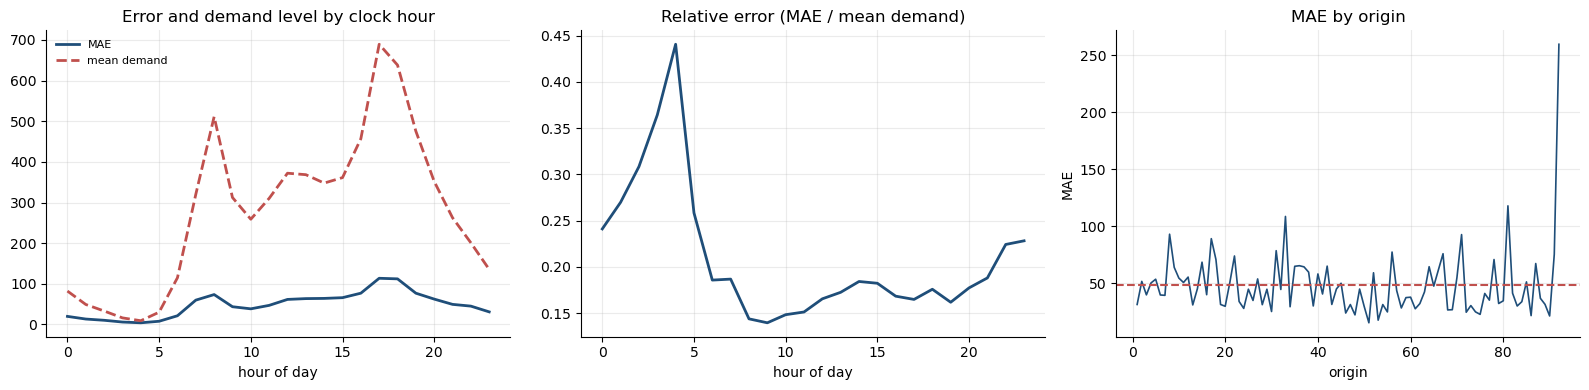

MAE and relative error by clock hour (selected hours):
  04:00   mean demand    9.1   MAE    4.0   relative  44.1%
  08:00   mean demand  511.2   MAE   73.5   relative  14.4%
  12:00   mean demand  372.1   MAE   61.5   relative  16.5%
  17:00   mean demand  689.4   MAE  113.6   relative  16.5%
  22:00   mean demand  200.9   MAE   45.0   relative  22.4%

Spearman rho across the 24 clock hours, vs mean demand:
  absolute MAE     +0.977
  relative error   -0.772
  relative error range: 13.9% (at 09:00) .. 44.1% (at 04:00)

Worst five origins:
  origin  92  starting 2012-10-29   MAE  259.6   [36 disruption hours]
  origin  81  starting 2012-10-07   MAE  117.9
  origin  33  starting 2012-07-03   MAE  108.6
  origin   8  starting 2012-05-14   MAE   93.0
  origin  71  starting 2012-09-17   MAE   92.7


In [64]:
cp = CARRIED_PRED.copy()
cp["resid"] = cp["y_true"] - cp["y_pred"]
cp["ae"] = cp["resid"].abs()
cp["clock_hour"] = cp["ds"].dt.hour

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
by_hour = cp.groupby("clock_hour").agg(mae=("ae", "mean"), level=("y_true", "mean"))
axes[0].plot(by_hour.index, by_hour["mae"], lw=2, color="#1f4e79", label="MAE")
axes[0].plot(by_hour.index, by_hour["level"], lw=2, color="#c0504d", ls="--", label="mean demand")
axes[0].set(title="Error and demand level by clock hour", xlabel="hour of day")
axes[0].legend(fontsize=8, frameon=False)

axes[1].plot(by_hour.index, by_hour["mae"] / by_hour["level"], lw=2, color="#1f4e79")
axes[1].set(title="Relative error (MAE / mean demand)", xlabel="hour of day")

fold_mae = cp.groupby("fold")["ae"].mean()
axes[2].plot(fold_mae.index, fold_mae.values, lw=1.2, color="#1f4e79")
axes[2].axhline(fold_mae.mean(), color="#c0504d", ls="--", lw=1.5)
axes[2].set(title="MAE by origin", xlabel="origin", ylabel="MAE")
plt.tight_layout(); plt.show()

# Measured, not asserted: rank correlations of each error scale against demand level
# across the 24 clock hours. The interpretation is written from these numbers.
by_hour["relative"] = by_hour["mae"] / by_hour["level"]
_rho_abs = by_hour["mae"].corr(by_hour["level"], method="spearman")
_rho_rel = by_hour["relative"].corr(by_hour["level"], method="spearman")
print("MAE and relative error by clock hour (selected hours):")
for h in [4, 8, 12, 17, 22]:
    r = by_hour.loc[h]
    print(f"  {h:02d}:00   mean demand {r['level']:6.1f}   MAE {r['mae']:6.1f}   "
          f"relative {r['relative']:6.1%}")
print()
print(f"Spearman rho across the 24 clock hours, vs mean demand:")
print(f"  absolute MAE     {_rho_abs:+.3f}")
print(f"  relative error   {_rho_rel:+.3f}")
print(f"  relative error range: {by_hour['relative'].min():.1%} "
      f"(at {int(by_hour['relative'].idxmin()):02d}:00) .. "
      f"{by_hour['relative'].max():.1%} (at {int(by_hour['relative'].idxmax()):02d}:00)")
print()
print("Worst five origins:")
for f_, v in fold_mae.nlargest(5).items():
    d = cv_folds.loc[cv_folds["fold"] == f_, "val_start"].iloc[0]
    dis = int(cp.loc[cp["fold"] == f_, "is_disruption"].sum())
    print(f"  origin {f_:3d}  starting {d.date()}   MAE {v:6.1f}"
          + (f"   [{dis} disruption hours]" if dis else ""))

Busy hours have larger absolute errors: the Spearman correlation between clock-hour mean rentals and MAE is **+0.977**. At **17:00**, mean rentals are **689.4** and MAE is **113.6**.

The relative scale reverses the pattern, with correlation **−0.772**. At **04:00**, MAE is only **4.0**, but the mean is **9.1**, giving a ratio of **44.1%**. The minimum displayed ratio is **13.9% at 09:00**. These summaries show why a small absolute overnight error and a large busy-hour error can deserve different interpretations without changing the primary metric.

The worst path starts on **October 29**, during Sandy, with MAE **259.6** and **36 disruption-labelled inferred-zero targets**. The next worst path has MAE **117.9**. Retaining Sandy exposes a substantial failure under the declared target rather than concealing it through scoring exclusions.

The pipeline has no explicit storm-warning or service-status feature. That provides context for a future investigation, not a demonstrated explanation for the observed errors. These system-wide results also do not establish station-level rebalancing requirements.

### 9.4 What Dependence Remains in the Forecast Errors?

The 92 scored paths form a contiguous hourly sequence, allowing a pooled residual ACF. I define residuals as **actual minus forecast**, so negative values indicate overprediction.

This sequence combines 48 forecast steps and repeatedly refitted models under changing conditions. I therefore read the ACF and Ljung–Box outputs as descriptive diagnostics, rather than assume their usual reference distributions provide calibrated inference here. The nominal ACF bands are also reference bands, not simultaneous evidence across all inspected lags.

Pooled residual series: 4416 hours, 0 breaks in hourly spacing (the nonexistent DST hours).


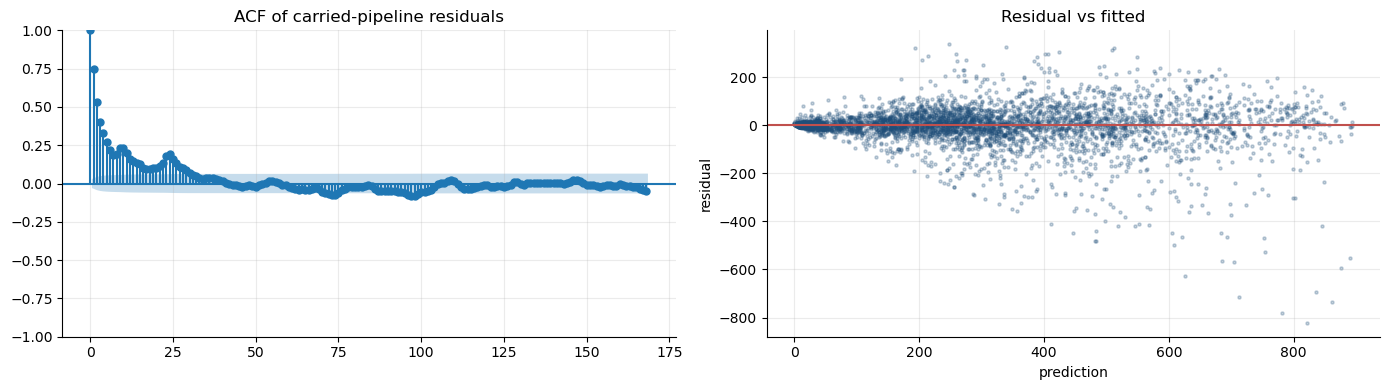


Ljung-Box on the pooled residuals (DESCRIPTIVE -- see the note below):
       lb_stat  lb_pvalue
24   7452.6517        0.0
48   7857.6078        0.0
168  8440.1334        0.0

mean -3.44   sd 85.12   skew -2.12   excess kurtosis +13.97




ACF summary: 95% band +/-0.0295 at n=4416
  lags outside the band: 79 of 168
  largest |ACF|: 0.750 at lag 1
  ACF at notable lags: 1h +0.750, 2h +0.532, 3h +0.405, 12h +0.163, 24h +0.192, 48h -0.011, 168h -0.052

These are measurements. The supported interpretation is written in the markdown
cell below, from these outputs -- not printed here as a foregone conclusion.


In [65]:
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox

cps = cp.sort_values("ds")
_gaps = cps["ds"].diff().dropna()
print(f"Pooled residual series: {len(cps)} hours, "
      f"{int((_gaps != pd.Timedelta(hours=1)).sum())} breaks in hourly spacing "
      f"(the nonexistent DST hours).")
res = cps["resid"].to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(res, lags=WEEK, ax=axes[0], alpha=0.05)
axes[0].set_title("ACF of carried-pipeline residuals")
axes[1].scatter(cps["y_pred"], res, s=5, alpha=0.25, color="#1f4e79")
axes[1].axhline(0, color="#c0504d", lw=1.5)
axes[1].set(title="Residual vs fitted", xlabel="prediction", ylabel="residual")
plt.tight_layout(); plt.show()

print()
print("Ljung-Box on the pooled residuals (DESCRIPTIVE -- see the note below):")
print(acorr_ljungbox(res, lags=[24, 48, WEEK], return_df=True).round(4).to_string())
print()
print(f"mean {res.mean():+.2f}   sd {res.std():.2f}   "
      f"skew {pd.Series(res).skew():+.2f}   excess kurtosis {pd.Series(res).kurtosis():+.2f}")
print()
# Report the ACF numerically so the interpretation below rests on measurements
# rather than on what a plot appears to show.
from statsmodels.tsa.stattools import acf as _acf_fn
_a = _acf_fn(res, nlags=WEEK, fft=True)[1:]
_band = 1.96 / np.sqrt(len(res))
print()
print(f"ACF summary: 95% band +/-{_band:.4f} at n={len(res)}")
print(f"  lags outside the band: {int((np.abs(_a) > _band).sum())} of {len(_a)}")
print(f"  largest |ACF|: {np.abs(_a).max():.3f} at lag {int(np.abs(_a).argmax()) + 1}")
print("  ACF at notable lags: "
      + ", ".join(f"{L}h {_a[L-1]:+.3f}" for L in [1, 2, 3, 12, 24, 48, WEEK]))
print()
print("These are measurements. The supported interpretation is written in the markdown")
print("cell below, from these outputs -- not printed here as a foregone conclusion.")

The pooled sequence contains **4,416 residuals and no hourly-spacing breaks**. Autocorrelation is strongest at short lags: **0.750 at one hour**, **0.532 at two**, and **0.405 at three**. It falls to **0.192 at 24 hours**, **−0.011 at 48**, and **−0.052 at 168**.

The Ljung–Box statistics are large and their p-values display as zero; 79 of 168 ACF values exceed the simple nominal reference band. These summaries show substantial structure in the observed pooled errors. They do not establish that every flagged lag is significant under the appropriate dependence model, or that remaining structure can be exploited at issuance.

Once a path is issued, its realized errors are unavailable for updating later steps within that path. More recent observations are available before issuance, but the common lag policy deliberately omits some of them for early steps. This diagnostic neither measures their value nor proves that all useful weekly information has been captured.

Mean residual is **−3.44** against standard deviation **85.12**, indicating modest average overprediction in rental units. Skew **−2.12** and excess kurtosis **13.97** describe an asymmetric, heavy-tailed sample with severe negative errors. They do not determine the number or cause of directional misses.

These are reasons to assess interval behavior empirically. Section 8 reported development coverage; the final block below evaluates the frozen construction in a later period.

## The final-evaluation protocol

This summarizes the historical specification recorded before final model-performance evaluation. The pre-revision protocol text is retained in this cell's metadata. This editorial condensation does not change the design; Section 0 records the limited prior outcome exposure, and Section 10.5 records the later withdrawal of the supplementary window.

| Element | Frozen specification |
|:---|:---|
| Carried model | `LightGBM (weather=lagged)` |
| Hyperparameters | `objective="regression_l1"`, `num_leaves=63`, `n_estimators=400`, `learning_rate=0.05`, `subsample=0.8`, `subsample_freq=1`, `colsample_bytree=0.8`, `random_state=42`, `n_jobs=4` |
| Target and predictions | Raw recorded-rental target; predictions clipped at zero |
| Feature policy | Unchanged calendar/history features from Section 5; causal weather at target time minus 48 hours; engineered `y_lagsrc` |
| Updating | Expanding training history strictly before each origin; refit without retuning |
| Benchmarks | Four-week hour-of-week climatology, weekly seasonal naive, daily seasonal naive |
| Primary score | MAE; pooled RMSE and per-origin-training-scaled MASE alongside |
| Primary intervals | Absolute-residual conformal order statistic separately at each of 48 horizon steps, nominal 80%; pooled conformal is secondary |
| Final calibration | Frozen thresholds estimated from all 92 development forecast paths; no final residuals used |
| Scored population | Every genuine grid position in 30 complete paths, inferred zeros included |

**How the pipeline was chosen.** LightGBM led mean MAE across the 92 development selection origins. Its hyperparameters were chosen on 22 earlier tuning origins without weather. The weather-mode rule used those same earlier origins: add deployable weather only when it improves MAE by more than 0.25 rentals/hour. Its observed tuning improvement was 1.570. Neither the oracle scenario nor the Section 9 diagnostics changed the carried pipeline.

**Window arithmetic.** November 1-December 31 contains 1,464 hourly grid positions: 30 complete 48-step paths plus 24 trailing positions. Origins run from November 1 through December 29 at midnight, scoring November 1 through December 30 at 23:00. The original supplementary plan for December 31 was withdrawn for the configuration error described in Section 10.5; those 24 positions remain unscored.

**Availability.** Later origins can use earlier final-block actuals once observed. Held-back holidays come only from the predeclared November 12, November 22, and December 25 list; the supplied flags are checked but do not provide the features. The four previously known absent timestamps were November 8 at 03:00, November 29 at 03:00, December 24 at 04:00, and December 25 at 03:00; all receive inferred zero targets under the fixed policy.

**Interpretation.** Section 8.4 did not resolve the carried model's developmental MAE differences from the climatology or XGBoost under full-family Holm adjustment using either IID or lag-4 Bartlett HAC standard errors. This final section reports the selected pipeline and predeclared benchmarks without reopening selection. It performs no new inferential tests. Coverage is empirical pointwise coverage; exchangeability is unestablished, and horizon step remains confounded with clock hour and forecast day. Seasonal shift, dependence, finite calibration size, and misspecification are possible explanations for a coverage shortfall, not identified causes.

## Section 10: Final Historical Evaluation

The carried configuration, three benchmarks, scoring population, and interval rule are fixed in the protocol above. I now report their saved evaluation on the November–December block.

At each origin, models are refitted using observations available by then. Earlier final-period actuals can enter later training histories, but hyperparameters, weather mode, and calibration thresholds remain frozen.

This is the retained historical evaluation with Section 0's limited prior exposure. An editorial revision or numerical replay does not turn it into a new prospective test.

### 10.1 Opening and Reconstructing the Final Block

The implementation extends the development frame rather than reconstructing it. It retains the development reference profiles and thresholds for classifying absent runs, then applies the same inferred-zero target policy.

The classification still reads realized daily totals, so its labels remain retrospective. They do not determine which final prediction errors count.

Calendar features come from the **predeclared holiday list and calendar rule**. The supplied final-period holiday flags are used to check agreement, not to correct the features. Deployable weather is extended separately from raw observations using causal forward filling.

In [66]:
# The final block's specification, declared rather than derived. A preflight may define
# PREFLIGHT_SPEC beforehand to aim this same machinery at a development surrogate; the real
# evaluation asserts the literal held-back values below, so derived arithmetic can never
# silently accept an incomplete block.
BLOCK_SPEC = globals().get("PREFLIGHT_SPEC", {
    "label": "held-back block",
    "start": pd.Timestamp("2012-11-01 00:00"),
    "end":   pd.Timestamp("2012-12-31 23:00"),
    "hours": 1464, "n_complete": 30, "tail_hours": 24,
    "calendar": eval_calendar,          # the PREDECLARED held-back calendar
})
IS_PREFLIGHT = "PREFLIGHT_SPEC" in globals()
if not IS_PREFLIGHT:
    assert BLOCK_SPEC["start"] == pd.Timestamp("2012-11-01 00:00")
    assert BLOCK_SPEC["end"]   == pd.Timestamp("2012-12-31 23:00")
    assert BLOCK_SPEC["hours"] == 1464
    assert BLOCK_SPEC["n_complete"] == 30
    assert BLOCK_SPEC["tail_hours"] == 24
    assert BLOCK_SPEC["calendar"] is eval_calendar,         "the final evaluation must use the predeclared held-back calendar"
    print("FINAL EVALUATION: held-back block, predeclared calendar.")
else:
    print(f"*** PREFLIGHT on {BLOCK_SPEC['label']} -- machinery test, NOT a result ***")

EVAL_START, EVAL_END = BLOCK_SPEC["start"], BLOCK_SPEC["end"]
CALENDAR_PROVIDER = BLOCK_SPEC["calendar"]

DF_DEV = df.copy()                      # the frozen development frame, kept for verification
_WC_DEV = WEATHER_CAUSAL.copy()         # and the frozen development weather frame
DEV_END = DF_DEV.index.max()
assert DEV_END < EVAL_START,     "the development frame must end strictly before the block being evaluated"

_ha = pd.read_csv(DATA_DIR + "hour.csv")
_da = pd.read_csv(DATA_DIR + "day.csv")
_ha["ds"] = pd.to_datetime(_ha["dteday"]) + pd.to_timedelta(_ha["hr"], unit="h")
_da["dteday"] = pd.to_datetime(_da["dteday"])
hourly_ev = _ha[(_ha["ds"] >= EVAL_START) & (_ha["ds"] <= EVAL_END)].set_index("ds").sort_index()
daily_ev  = _da[(_da["dteday"] >= EVAL_START) & (_da["dteday"] <= EVAL_END)].set_index("dteday")
del _ha, _da

index_ev = pd.date_range(EVAL_START, EVAL_END, freq="h")
absent_ev = index_ev.difference(hourly_ev.index)
print(f"Block opened [{BLOCK_SPEC['label']}]: {EVAL_START} -> {EVAL_END}  ({len(index_ev)} hours)")
print(f"  rows present {len(hourly_ev)}, absent {len(absent_ev)}")

# Classify absent runs with the rule FROZEN on development data.
runs_ev = []
for _, g in itertools.groupby(enumerate(absent_ev), lambda t: t[1] - pd.Timedelta(hours=t[0])):
    g = [x[1] for x in g]
    runs_ev.append({"start": g[0], "end": g[-1], "hours": len(g)})
runs_ev = pd.DataFrame(runs_ev)

if len(runs_ev):
    def _ev_evidence(r):
        idx = pd.date_range(r["start"], r["end"], freq="h")
        typical = how_median.reindex(idx.dayofweek * 24 + idx.hour).to_numpy()   # development medians
        days = pd.date_range(r["start"].normalize(), r["end"].normalize(), freq="D")
        observed = daily_ev.loc[days, "cnt"].to_numpy()
        reference = np.array([daily[(daily.index.dayofweek == d.dayofweek) &     # development reference
                                    (daily.index.month == d.month)]["cnt"].median() for d in days])
        return pd.Series({"max_typical_hour": typical.max(),
                          "day_ratio": float(np.min(observed / reference))})
    runs_ev = runs_ev.join(runs_ev.apply(_ev_evidence, axis=1))
    runs_ev["kind"] = np.where(
        runs_ev.apply(lambda r: r["hours"] == 1 and _is_dst_gap(r["start"]), axis=1), "dst_nonexistent",
        np.where((runs_ev["max_typical_hour"] > MAX_TYPICAL_HOUR) &
                 (runs_ev["day_ratio"] < DAY_RATIO_MAX), "disruption", "zero_hour"))
    print()
    print(runs_ev.groupby("kind").agg(runs=("hours", "size"), hours=("hours", "sum")).to_string())
    if (runs_ev["hours"] >= 4).any():
        print()
        print(runs_ev[runs_ev["hours"] >= 4].to_string(index=False))

def _ev_hours(kind):
    if not len(runs_ev) or kind not in set(runs_ev["kind"]):
        return pd.DatetimeIndex([])
    return pd.DatetimeIndex([t for _, r in runs_ev[runs_ev["kind"] == kind].iterrows()
                             for t in pd.date_range(r["start"], r["end"], freq="h")])

FINAL EVALUATION: held-back block, predeclared calendar.


Block opened [held-back block]: 2012-11-01 00:00:00 -> 2012-12-31 23:00:00  (1464 hours)
  rows present 1460, absent 4

           runs  hours
kind                  
zero_hour     4      4


In [67]:
df_ev = (hourly_ev[["cnt"] + WEATHER + ["holiday", "workingday"]]
         .rename(columns={"cnt": "y"}).reindex(index_ev))
df_ev.index.name = "ds"
df_ev["is_disruption"]   = df_ev.index.isin(_ev_hours("disruption"))
df_ev["is_nonexistent"]  = df_ev.index.isin(_ev_hours("dst_nonexistent"))
df_ev["was_absent_zero"] = df_ev.index.isin(_ev_hours("zero_hour"))

# Same target policy as Section 1: infer zeros at absent non-DST hours, including disruptions.
df_ev.loc[df_ev["was_absent_zero"], "y"] = 0.0
df_ev.loc[df_ev["is_disruption"], "y"] = 0.0
df_ev["y_normal_ops"] = df_ev["y"].where(~df_ev["is_disruption"])

df_ev[["temp", "atemp", "hum", "windspeed"]] = df_ev[["temp", "atemp", "hum", "windspeed"]].interpolate()
df_ev["weathersit"] = df_ev["weathersit"].ffill().bfill()

# Calendar: PREDECLARED only. The held-back table's own flags are used solely to check it.
# The final call is fixed to the predeclared held-back calendar (asserted above);
# a preflight supplies its own period-appropriate provider.
_ec = CALENDAR_PROVIDER(index_ev)
_actual_hol = (daily_ev["holiday"].reindex(index_ev.normalize()).to_numpy() == 1)
_pred_hol = _ec["holiday"].to_numpy() == 1
print(f"Predeclared calendar vs the held-back table: "
      f"{int((_pred_hol != _actual_hol).sum())} disagreeing hours of {len(index_ev)}")
if (_pred_hol != _actual_hol).any():
    _d = pd.Series(_actual_hol != _pred_hol, index=index_ev)
    print("  disagreeing dates:", sorted({str(t.date()) for t in index_ev[_d]}))
    print("  NOTE: the PREDECLARED values are used regardless -- this is a check, not a correction.")
df_ev["holiday"] = _ec["holiday"].to_numpy()
df_ev["workingday"] = _ec["workingday"].to_numpy()

# Engineered lag source: past-only donors for disruption and nonexistent hours.
y_lagsrc_ev = df_ev["y"].copy()
_need = df_ev["is_disruption"] | df_ev["is_nonexistent"]
_combined_y = pd.concat([DF_DEV["y"], df_ev["y"]])
for _step in [WEEK, 2 * WEEK, 3 * WEEK, 4 * WEEK]:            # PAST donors only
    if not _need.any():
        break
    _donor = pd.Series(_combined_y.reindex(index_ev - pd.Timedelta(hours=_step)).to_numpy(),
                       index=index_ev)
    _take = _need & _donor.notna()
    y_lagsrc_ev[_take] = _donor[_take]
    _need &= ~_take
assert not _need.any(), "every held-back disruption/DST hour needs a past donor"
df_ev["y_lagsrc"] = y_lagsrc_ev

# ---- extend, never rebuild -------------------------------------------------
df = pd.concat([DF_DEV, df_ev[DF_DEV.columns]])
assert df.index.is_monotonic_increasing and not df.index.duplicated().any()
assert df.loc[:DEV_END].equals(DF_DEV), "the development frame must survive the extension unchanged"
Y_RAWLAG = pd.concat([Y_RAWLAG, df_ev["y"].where(~df_ev["is_nonexistent"],
                                                 df_ev["y_lagsrc"])])
WEATHER_CAUSAL = pd.concat([WEATHER_CAUSAL,
                            hourly_ev[WEATHER_COLS_X].reindex(index_ev)]).ffill()
assert WEATHER_CAUSAL.notna().all().all()
assert WEATHER_CAUSAL.loc[:DEV_END].equals(_WC_DEV), "development weather must be unchanged"
print()
print(f"Frame extended to {df.index.max()}: {len(df)} hours "
      f"({len(DF_DEV)} development + {len(df_ev)} held back), development rows unchanged.")
print(f"Held-back target: {int(df_ev['y'].notna().sum())} scoreable hours, "
      f"{int((df_ev['y'] == 0).sum())} zeros, {int(df_ev['is_disruption'].sum())} disruption hours")

Predeclared calendar vs the held-back table: 0 disagreeing hours of 1464

Frame extended to 2012-12-31 23:00:00: 17544 hours (16080 development + 1464 held back), development rows unchanged.
Held-back target: 1464 scoreable hours, 4 zeros, 0 disruption hours


The block contains **1,464 grid positions**, with **1,460 supplied rows and four absent hours**. All four receive ordinary inferred-zero labels; there are no disruption-labelled runs in this block. This does not establish that every hour had normal operating conditions.

The calendar check finds **zero disagreements**, and the extension preserves the **16,080 development rows**. These checks support continuity of the implemented data policy. They do not erase the limited prior knowledge of the four inferred zeros disclosed earlier.

All 1,464 positions have eligible targets, but headline scoring uses only complete 48-step paths, as the next check confirms.

### 10.2 Thirty Complete Forecast Paths

The final block contains **30 complete 48-step paths plus 24 trailing positions**. Origins run from **November 1 through December 29 at midnight**; their targets end on **December 30 at 23:00**.

The headline population is therefore **1,440 hours per procedure**. December 31 remains unscored following the supplementary-window withdrawal documented in Section 10.5.

In [68]:
_block_hours = int((EVAL_END - EVAL_START) / pd.Timedelta(hours=1)) + 1
N_COMPLETE = _block_hours // HORIZON
_tail_hours = _block_hours - N_COMPLETE * HORIZON
# Derived values must match the DECLARED ones. Arithmetic alone would accept a short block.
assert _block_hours == BLOCK_SPEC["hours"], f"{_block_hours} != {BLOCK_SPEC['hours']}"
assert N_COMPLETE  == BLOCK_SPEC["n_complete"], f"{N_COMPLETE} != {BLOCK_SPEC['n_complete']}"
assert _tail_hours == BLOCK_SPEC["tail_hours"], f"{_tail_hours} != {BLOCK_SPEC['tail_hours']}"

eval_origins = make_origins(EVAL_END, first_day=EVAL_START, spacing=HORIZON)
eval_folds = pd.DataFrame({"fold": range(1, len(eval_origins) + 1), "val_start": eval_origins})
eval_folds["val_end"] = eval_folds["val_start"] + pd.Timedelta(hours=HORIZON - 1)

assert len(eval_folds) == N_COMPLETE, f"expected {N_COMPLETE} complete windows, got {len(eval_folds)}"
assert eval_folds["val_start"].min() == EVAL_START
assert eval_folds["val_end"].max() == EVAL_START + pd.Timedelta(hours=N_COMPLETE * HORIZON - 1)
assert (eval_folds["val_start"].dt.hour == 0).all(), "every origin starts at midnight"
assert (eval_folds["val_start"].diff().dropna() == pd.Timedelta(hours=HORIZON)).all()

tail_index = pd.date_range(EVAL_START + pd.Timedelta(hours=N_COMPLETE * HORIZON), EVAL_END, freq="h")
assert len(tail_index) == _tail_hours
print(f"Block: {_block_hours} hours = {N_COMPLETE} x {HORIZON} + {_tail_hours}")
print(f"Final origins: {len(eval_folds)}  {eval_folds['val_start'].min()} -> {eval_folds['val_end'].max()}")
print(f"  {len(eval_folds) * HORIZON} hours scored in the headline")
print(f"Supplementary short window: {len(tail_index)} hours from {tail_index[0]} "
      f"-- WITHDRAWN / UNSCORED (Section 10.5); excluded from every headline figure")
print(f"  {len(eval_folds) * HORIZON} + {len(tail_index)} = {len(eval_folds)*HORIZON + len(tail_index)} "
      f"= the full block")

Block: 1464 hours = 30 x 48 + 24
Final origins: 30  2012-11-01 00:00:00 -> 2012-12-30 23:00:00
  1440 hours scored in the headline
Supplementary short window: 24 hours from 2012-12-31 00:00:00 -- WITHDRAWN / UNSCORED (Section 10.5); excluded from every headline figure
  1440 + 24 = 1464 = the full block


### 10.3 Point Accuracy Against the Predeclared Benchmarks

The carried LightGBM pipeline and three seasonal benchmarks forecast the same 30 paths. Other development candidates are not reopened for final-period selection.

I first compare procedures **within this common final population**, then place the results beside their development errors. The latter comparison describes different periods and cannot by itself isolate a generalization effect.

In [69]:
FINAL = {}
FINAL[CARRIED_NAME] = run_model(make_lgb_weather(CARRIED_WEATHER_MODE), CARRIED_NAME,
                                folds=eval_folds, verbose=False, store=False)
for _fn, _nm in [(hour_of_week_climatology, "Hour-of-week climatology (4w)"),
                 (weekly_naive, "Seasonal naive (168h)"),
                 (seasonal_naive, "Seasonal naive (24h)")]:
    FINAL[_nm] = run_model(_fn, _nm, folds=eval_folds, verbose=False, store=False)

final_tbl = (pd.concat(FINAL.values(), ignore_index=True)
             .groupby("model").apply(score_frame, include_groups=False)
             .sort_values("MAE"))
final_tbl["n"] = final_tbl["n"].astype(int)
print(f"{'PREFLIGHT (surrogate)' if IS_PREFLIGHT else 'FINAL EVALUATION'}"
      f" -- {N_COMPLETE} complete {HORIZON}-hour windows, scored once")
print(final_tbl.round(3).to_string())

_carried_mae = final_tbl.loc[CARRIED_NAME, "MAE"]
_clim_mae = final_tbl.loc["Hour-of-week climatology (4w)", "MAE"]
print()
print(f"Carried model vs the untuned climatology benchmark: "
      f"{_carried_mae - _clim_mae:+.3f} MAE "
      f"({'carried model better' if _carried_mae < _clim_mae else 'BENCHMARK BETTER'})")

FINAL EVALUATION -- 30 complete 48-hour windows, scored once
                                  MAE     RMSE   MASE     n
model                                                      
LightGBM (weather=lagged)      51.882   86.042  0.811  1440
Hour-of-week climatology (4w)  64.534  109.906  1.009  1440
Seasonal naive (168h)          71.828  117.833  1.123  1440
Seasonal naive (24h)           83.321  134.906  1.303  1440

Carried model vs the untuned climatology benchmark: -12.652 MAE (carried model better)


The carried pipeline achieves **MAE 51.882**, compared with **64.534 for the climatology**, **71.828 for weekly naive**, and **83.321 for daily naive**. It also has the lowest observed pooled RMSE (**86.042**) and MASE (**0.811**) among these four procedures.

Its MAE is **12.652 rentals lower than the climatology**, approximately **19.6%** relative to that benchmark. This is an observed advantage on 30 paths. No final-period paired test or uncertainty interval for the difference was computed, so I do not present it as established population superiority.

The MASE interpretation remains training-scale-relative; the direct benchmark advantage comes from the actual error comparison.

In [70]:
# Development vs final, side by side. The development column is the number Section 8.4
# reported on the selection origins; the final column is this block. Different populations,
# so the gap mixes genuine generalisation with a seasonal regime change.
dev_tbl = (pd.concat([CARRIED_PRED.assign(model=CARRIED_NAME)]
                     + [p for p in predictions
                        if p["model"].iloc[0] in ["Hour-of-week climatology (4w)",
                                                  "Seasonal naive (168h)", "Seasonal naive (24h)"]],
                     ignore_index=True)
           .groupby("model").apply(score_frame, include_groups=False))
_dev_col = f"development MAE ({CARRIED_PRED['fold'].nunique()} origins)"
_fin_col = f"final MAE ({len(eval_folds)} origins)"
cmp = pd.DataFrame({_dev_col: dev_tbl["MAE"], _fin_col: final_tbl["MAE"]})
cmp["change"] = cmp[_fin_col] - cmp[_dev_col]
print(cmp.sort_values(_fin_col).round(3).to_string())
print()
# The two blocks are different populations, so this gap mixes generalisation with any
# change of regime between them. Direction and size are MEASURED here, not asserted.
_dev_level = CARRIED_PRED["y_true"].mean()
_fin_level = FINAL[CARRIED_NAME]["y_true"].mean()
print("Development and final are different populations, so `change` mixes generalisation")
print("with any regime difference between them. Both benchmarks are scored on the SAME")
print("block for that reason, rather than comparing the carried model only against its")
print("own development number.")
print()
print(f"Mean demand -- development origins {_dev_level:.1f}, final block {_fin_level:.1f} "
      f"({(_fin_level / _dev_level - 1):+.1%})")
print(f"Zero-demand hours -- development {(CARRIED_PRED['y_true'] == 0).mean():.1%}, "
      f"final block {(FINAL[CARRIED_NAME]['y_true'] == 0).mean():.1%}")
print()
print("What that difference means is interpreted in Section 11, from these numbers.")

                               development MAE (92 origins)  final MAE (30 origins)  change
model                                                                                      
LightGBM (weather=lagged)                            48.590                  51.882   3.293
Hour-of-week climatology (4w)                        49.856                  64.534  14.679
Seasonal naive (168h)                                60.075                  71.828  11.753
Seasonal naive (24h)                                105.824                  83.321 -22.503

Development and final are different populations, so `change` mixes generalisation
with any regime difference between them. Both benchmarks are scored on the SAME
block for that reason, rather than comparing the carried model only against its
own development number.

Mean demand -- development origins 279.5, final block 190.0 (-32.0%)
Zero-demand hours -- development 0.8%, final block 0.3%

What that difference means is interpreted in Section 1

### The Same Procedure in a Different Target Period

Carried-model MAE increases by **3.293** from development to final evaluation, while climatology MAE increases by **14.679**. Daily naive moves in the opposite direction, improving by **22.503**.

The scored mean rental level changes from **279.5 to 190.0**, a **32.0% reduction**, and the zero share changes from **0.8% to 0.3%**. These are different target populations, not a controlled change in training-set size or a demonstrated regime break.

The final results show a larger observed carried-model advantage over climatology than development did. They do not explain that change, or retroactively resolve the earlier developmental comparison.

### 10.4 Do the Frozen Intervals Transfer to the Final Period?

The primary construction uses the exact absolute-residual calibration rank **separately at each horizon**, now estimated from **all 92 development paths**. The pooled construction is the specified secondary comparison.

Thresholds remain frozen throughout final evaluation; final residuals do not recalibrate them. Point models still refit at each origin. I report coverage and clipped width over all 30 paths, followed by horizon profiles and the first four paths as illustrations.

In [71]:
# Recalibrate on ALL 92 development origins, as the protocol predeclares.
_cal_all = CARRIED_PRED
_res_all = (_cal_all["y_true"] - _cal_all["y_pred"]).abs()
final_conf_by_h = _cal_all.groupby("h").apply(
    lambda g: conformal_quantile((g["y_true"] - g["y_pred"]).abs(), ALPHA), include_groups=False)
final_conf_pooled = conformal_quantile(_res_all, ALPHA)
print(f"Calibrated on {len(_cal_all)} development hours from {_cal_all['fold'].nunique()} origins.")
print(f"  per-step half-widths {final_conf_by_h.min():.1f} .. {final_conf_by_h.max():.1f}")
print(f"  pooled half-width    {final_conf_pooled:.1f}")

fin = FINAL[CARRIED_NAME].copy()
for _lbl, _hw in [("per_h", fin["h"].map(final_conf_by_h)), ("pooled", final_conf_pooled)]:
    lo = np.clip(fin["y_pred"] - _hw, 0, None)       # both bounds clipped
    hi = np.clip(fin["y_pred"] + _hw, 0, None)
    assert (hi >= lo).all() and np.isfinite(lo).all() and np.isfinite(hi).all()
    fin[f"cov_{_lbl}"] = ((fin["y_true"] >= lo) & (fin["y_true"] <= hi)).astype(int)
    fin[f"wid_{_lbl}"] = hi - lo                     # width measured AFTER clipping

print()
print(f"COVERAGE on the final block ({len(fin)} hours), {1-ALPHA:.0%} nominal:")
for _lbl in ["per_h", "pooled"]:
    print(f"  conformal {_lbl:7s}  coverage {fin['cov_'+_lbl].mean():6.1%}   "
          f"mean width {fin['wid_'+_lbl].mean():7.1f}")
print()
print("Development assessment coverage was 81.9% (per-step) and 81.6% (pooled) on 37")
print("origins. A shortfall here is NOT attributable to any single cause. Candidate")
print("explanations, which this design does not separate:")
_cal_span = f"{CARRIED_PRED['ds'].min():%b}-{CARRIED_PRED['ds'].max():%b}"
_blk_span = f"{EVAL_START:%b}-{EVAL_END:%b}"
print(f"  - distribution shift: calibration origins span {_cal_span}, this block {_blk_span}")
print("  - residual dependence, which violates the exchangeability the guarantee needs")
print("  - finite calibration sample size")
print("  - model misspecification")
print("Reporting it as one of these would be a guess presented as a diagnosis.")

Calibrated on 4416 development hours from 92 origins.
  per-step half-widths 5.8 .. 184.8
  pooled half-width    74.4

COVERAGE on the final block (1440 hours), 80% nominal:
  conformal per_h    coverage  78.7%   mean width   145.1
  conformal pooled   coverage  76.8%   mean width   132.7

Development assessment coverage was 81.9% (per-step) and 81.6% (pooled) on 37
origins. A shortfall here is NOT attributable to any single cause. Candidate
explanations, which this design does not separate:
  - distribution shift: calibration origins span Apr-Oct, this block Nov-Dec
  - residual dependence, which violates the exchangeability the guarantee needs
  - finite calibration sample size
  - model misspecification
Reporting it as one of these would be a guess presented as a diagnosis.


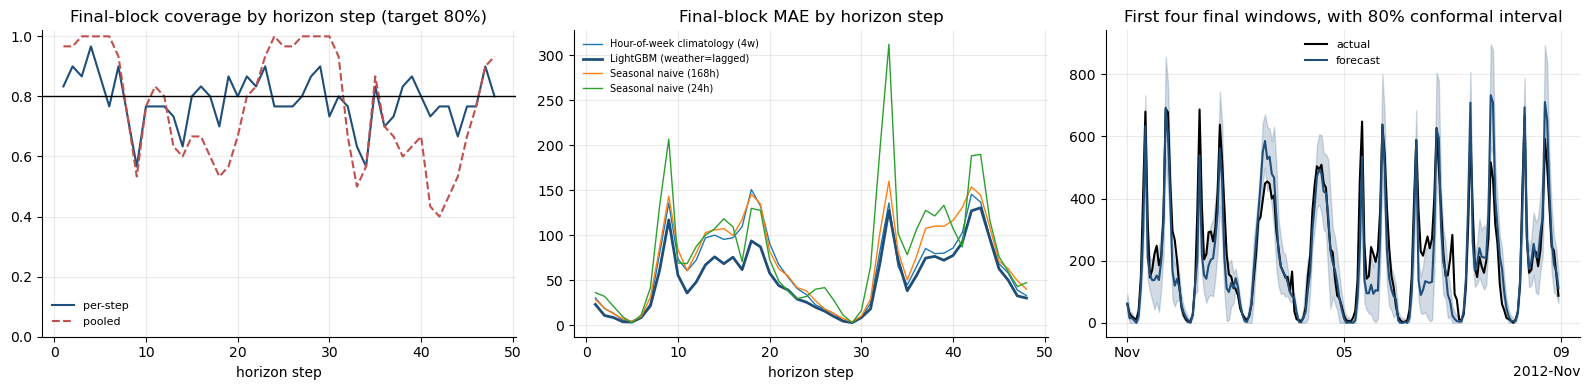

In [72]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
_bh = fin.groupby("h")
axes[0].plot(_bh["cov_per_h"].mean().index, _bh["cov_per_h"].mean().values, lw=1.5,
             color="#1f4e79", label="per-step")
axes[0].plot(_bh["cov_pooled"].mean().index, _bh["cov_pooled"].mean().values, lw=1.5,
             color="#c0504d", ls="--", label="pooled")
axes[0].axhline(1 - ALPHA, color="black", lw=1)
axes[0].set(title=f"Final-block coverage by horizon step (target {1-ALPHA:.0%})",
            xlabel="horizon step", ylim=(0, 1.02))
axes[0].legend(fontsize=8, frameon=False)

_mae_h = pd.concat(FINAL.values(), ignore_index=True)
for _nm, _g in _mae_h.groupby("model"):
    _c = "#1f4e79" if _nm == CARRIED_NAME else None
    _lw = 2 if _nm == CARRIED_NAME else 1
    axes[1].plot(_g.groupby("h")["y_true"].count().index,
                 _g.assign(ae=(_g["y_true"] - _g["y_pred"]).abs()).groupby("h")["ae"].mean().values,
                 lw=_lw, color=_c, label=_nm)
axes[1].set(title="Final-block MAE by horizon step", xlabel="horizon step")
axes[1].legend(fontsize=7, frameon=False)

_f0 = FINAL[CARRIED_NAME]
_w = _f0[_f0["fold"] <= 4]
axes[2].plot(_w["ds"], _w["y_true"], lw=1.5, color="black", label="actual")
axes[2].plot(_w["ds"], _w["y_pred"], lw=1.5, color="#1f4e79", label="forecast")
_hw = _w["h"].map(final_conf_by_h)
axes[2].fill_between(_w["ds"], np.clip(_w["y_pred"] - _hw, 0, None),
                     np.clip(_w["y_pred"] + _hw, 0, None), alpha=0.2, color="#1f4e79")
axes[2].set(title="First four final windows, with 80% conformal interval")
axes[2].legend(fontsize=8, frameon=False)
from matplotlib.dates import AutoDateLocator, ConciseDateFormatter
_date_locator = AutoDateLocator(minticks=3, maxticks=4)
axes[2].xaxis.set_major_locator(_date_locator)
axes[2].xaxis.set_major_formatter(ConciseDateFormatter(_date_locator))
plt.tight_layout(); plt.show()

### Final Coverage and Its Limits

| Construction | Nominal coverage | Observed hourly coverage | Mean width |
|:---|---:|---:|---:|
| Per horizon, primary | 80% | **78.7%** | 145.1 |
| Pooled, secondary | 80% | **76.8%** | 132.7 |

Both observed rates fall below nominal coverage. The pooled construction is narrower, while the per-horizon construction is closer to 80% on this block. No uncertainty interval or test for the difference was computed, so this does not establish that either construction is generally better calibrated.

Development assessment used 55 calibration paths and 37 later assessment paths; final evaluation uses thresholds estimated from all 92 development paths and a different target period. Their coverage difference cannot identify one cause such as seasonal drift, dependence, or calibration size.

The horizon plot shows variation hidden by the overall rates. Each step has only **30 outcomes**, and the 1,440 hourly hits are not independent Bernoulli trials. Clock hour and lead remain linked by midnight issuance.

The final panel illustrates **November 1–8**, the first four paths. Those paths do not represent the entire final evaluation, and the shaded pointwise intervals do not assert simultaneous containment of all 48 outcomes.

The saved results support a useful point forecast alongside an uncertainty construction whose transfer still requires prospective evaluation.

### 10.5 The supplementary short window -- withdrawn

**This result has been withdrawn, and the cell that produced it removed.** It is documented here rather than deleted silently.

The plan was to score the trailing 24 hours of 2012-12-31 as a clearly-labelled supplementary figure. The implementation reassigned the global `HORIZON` from 48 to 24 so that `run_model`'s one-prediction-per-hour assertion would pass. But `build_features()` reads that same global at call time, in two places:

- `shift = HORIZON` for the deployable weather features, and
- `range(HORIZON, HORIZON + 24)` for `recent_day_mean`.

So the supplementary forecast was built from weather observed at `t - 24` instead of `t - 48`, and from a recent-level average over lags 24-47 instead of 48-71. That is a **different configuration from the frozen carried pipeline** -- better informed, and not the thing this notebook set out to evaluate. The MAE it reported was therefore not the carried pipeline's performance on that window, and publishing it under the carried pipeline's name would have been wrong. The figure is not repeated here: its cell is gone, so no saved output in this notebook supports it.

A post-hoc audit found this. The minimum honest correction is to withdraw the number rather than re-engineer a replacement after seeing final results, so the cell has been removed.

**Consequences, stated precisely.** The headline evaluation is unaffected: all 30 complete 48-hour windows ran with `HORIZON = 48` throughout, and the mutation occurred only in the removed cell, after every headline figure had been computed. The `try/finally` restored `HORIZON` afterwards, so no later cell saw the altered value. What is lost is only the supplementary window, which the protocol had already excluded from every headline figure and from every conclusion. The block's window arithmetic is unchanged and still reported: 1464 = 30 x 48 + 24, with those trailing 24 hours simply left unscored.

The removed cell was the last code cell of the original run. This replay executes only the retained 48-step configuration; it does not reinstate or replace the withdrawn supplementary result.

## Section 11: Conclusions and Next Questions

### What the Comparisons Showed

The investigation began with a target-definition problem: absent hourly rows could not simply be interpolated without considering the supplied daily totals. Exact reconciliation supported inferred zeros under an explicit completeness assumption. Separating the target, lag source, and diagnostic grid made the subsequent comparisons interpretable.

The strongest simple reference was **four-week hour-of-week climatology**, not daily seasonal naive. Preserving weekday-dependent hourly shapes mattered enough that a rolling average remained competitive with considerably more elaborate procedures.

On the 92 development paths, **LightGBM with lagged weather** achieved the lowest observed MAE, **48.590**. Its adjusted comparisons with climatology and XGBoost remained unresolved under both IID and the specified HAC sensitivity. The other five contrasts fell below the adjusted 5% threshold. Selection followed the defined MAE rule rather than a claim of superiority over every comparator.

On the **30 final paths**, the carried pipeline achieved **MAE 51.882**, versus **64.534 for climatology**, an observed reduction of **12.652 rentals, or approximately 19.6%**. No final-period inference was performed. This is a favorable result on one later block, not proof of a universal advantage or a resolution of the earlier comparison on its own evidence.

### What the Diagnostics Added

The carried model relied strongly on hour-of-week summaries. Their inspection gains and permutation sensitivity describe a climatology-like information source inside a more flexible predictor, without identifying why its final-period error differed from the explicit baseline.

Lagged weather improved early tuning MAE by **1.570** under the fixed configuration and selection tolerance. The oracle's **19.9%** development contrast concerns access to realized future weather; it is neither an achievable improvement claim nor an accuracy bound.

Failures remained visible. Sandy produced the worst development path, at **259.6 MAE**. Absolute errors were largest around busy hours, while the ratio of MAE to mean rentals was largest overnight. Pooled residual dependence remained, but did not establish which additional information would improve a fixed-origin 48-step forecast.

Point accuracy and uncertainty also gave different answers. Final **80% pointwise intervals covered 78.7% per horizon and 76.8% pooled**. Their widths and coverage describe this execution and period; they do not establish a distribution-free guarantee or whole-path reliability.

### Limits on the Conclusions

- **The target is recorded rentals.** Inferred zeros depend on consistent, complete supplied daily totals. Neither aggregation measures unmet requests, and this system-wide study does not establish station-level performance.
- **The timeline is the supplied civil-time grid.** Spring DST positions are excluded from target scoring, and repeated autumn hours cannot be separated from the available fields.
- **Development was adaptive.** EDA, candidate representations, and model-family selection used development outcomes. Retrospective disruption labels informed the feature policy. Numerical timing checks do not make these analyst decisions prospective.
- **The final block had limited prior exposure.** Four inferred zero outcomes and its absence pattern were known before performance evaluation. Thirty potentially dependent paths in one later period cannot characterize performance across years or seasons.
- **Sensitivities have limited scope.** The window and lag-source comparisons apply to Ridge. Feature perturbations and descriptive residual tests do not supply causal explanations or guarantee an improvement from changing the model.
- **Replay is distinct from new evidence.** The earlier fresh-kernel verification reproduced the headline results in the existing environment, with the disclosed unselected SARIMA-candidate sensitivity. A clean installation remains untested. This Markdown revision does not rerun the experiments.

### The Most Useful Next Tests

The next evaluation should use a **previously unexamined period**, with the carried configuration, benchmarks, target policy, and issue schedule fixed before its outcomes are inspected. Repeating that evaluation across seasons would clarify how stable the observed advantage is.

Archived weather forecasts available at issuance would provide a practical successor to the oracle comparison. Event or service-status inputs could also be investigated, provided their publication times are known; the Sandy error does not establish that either input would solve the problem.

For uncertainty, a future protocol could test whether recent calibration or asymmetric intervals improve coverage and width under changing conditions. Any adaptation should be specified before its evaluation, including which past errors are available when thresholds update.

The main lesson I take forward is to assess the **complete forecasting procedure**: its target, information set, benchmark, selection rule, and uncertainty behavior. Here that approach produced a promising carried model while keeping the competitive baseline and unresolved questions visible.

## References and research sources

These sources explain the data and methods used above. Their assumptions are not established merely by implementing a related procedure.

**Data and calendar context**

1. Fanaee-T, H. (2013). [Bike Sharing](https://doi.org/10.24432/C5W894). UCI Machine Learning Repository. Dataset license: [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). The supplied `Data/Readme.txt` also requests citation of Fanaee-T and Gama's [Event labeling combining ensemble detectors and background knowledge](https://doi.org/10.1007/s13748-013-0040-3).
2. National Weather Service, Baltimore/Washington. Event reports for [Irene, August 27-28, 2011](https://www.weather.gov/lwx/events_20110827_irene), and [Sandy, October 29-30, 2012](https://www.weather.gov/lwx/events_20121030_sandy). These establish storm context, not a verified bike-share closure or a causal explanation of rental counts.

**Forecasting and model implementation**

3. Hyndman, R. J., and Athanasopoulos, G. [Forecasting: Principles and Practice, third edition](https://otexts.com/fpp3/): [time-series features](https://otexts.com/fpp3/features.html), [forecast evaluation](https://otexts.com/fpp3/toolbox.html), and [ARIMA models](https://otexts.com/fpp3/arima.html). These cover seasonal-strength summaries, scaled errors, and seasonal differencing.
4. scikit-learn developers. [Time-related feature engineering](https://scikit-learn.org/stable/auto_examples/applications/plot_cyclical_feature_engineering.html). Additive representations, periodic encodings, and explicit interactions.
5. Ke, G., et al. (2017). [LightGBM: A Highly Efficient Gradient Boosting Decision Tree](https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html); LightGBM developers, [leaf-wise growth and tuning](https://lightgbm.readthedocs.io/en/stable/Parameters-Tuning.html). Chen, T., and Guestrin, C. (2016). [XGBoost: A Scalable Tree Boosting System](https://arxiv.org/abs/1603.02754).
6. Prophet developers. [Seasonality and holidays](https://github.com/meta/prophet/blob/main/docs/_docs/seasonality,_holiday_effects,_and_regressors.md) and [uncertainty intervals](https://github.com/meta/prophet/blob/main/docs/_docs/uncertainty_intervals.md). The experiment uses Prophet's default MAP fitting rather than full posterior sampling.
7. statsmodels developers. [SARIMAX](https://www.statsmodels.org/stable/generated/statsmodels.tsa.statespace.sarimax.SARIMAX.html), [ADF](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.adfuller.html), and [KPSS](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.kpss.html). The environment record identifies the version used; linked stable documentation may describe a newer release.

**Comparison and uncertainty**

8. Diebold, F. X., and Mariano, R. S. (1995). [Comparing Predictive Accuracy](https://users.ssc.wisc.edu/~behansen/718/DieboldMariano1995.pdf). See also statsmodels documentation for [Newey-West HAC covariance](https://www.statsmodels.org/stable/generated/statsmodels.stats.sandwich_covariance.cov_hac.html) and [Holm's step-down adjustment](https://www.statsmodels.org/stable/generated/statsmodels.stats.multitest.multipletests.html). Here HAC is applied to origin-level path-loss differences with a fixed lag-4 Bartlett sensitivity.
9. Künsch, H. R. (1989). [The Jackknife and the Bootstrap for General Stationary Observations](https://doi.org/10.1214/aos/1176347265). Background for the moving-block resampling diagnostic; it does not make this changing series stationary.
10. Angelopoulos, A. N., and Bates, S. [A Gentle Introduction to Conformal Prediction and Distribution-Free Uncertainty Quantification](https://arxiv.org/abs/2107.07511). Background for the finite-sample calibration rank and its exchangeability requirement. The refitted chronological residual procedure here is assessed empirically, without importing a distribution-free guarantee.